# SAGE-CP v2.1 — Shift-Aware and Group-Equitable Conformal Prediction: cross-sectional health-condition identification under geographic and demographic distribution differences (BRFSS 2022)

**Status:** v2.1 is the corrected implementation. It addresses the v2.1 master prompt (Issues 1–9) and the dataset-validation protocol, and it has been validated **on synthetic data only**. **No number in this notebook is a research result until the notebook is re-executed on the real Kaggle file.** Every output row carries a `data_source` column (`kaggle`, `SYNTHETIC_SMOKE_TEST` or `SIMULATION`). Synthetic rows must never be reported as BRFSS results.

**Research framing (fixed):** this is *cross-sectional identification of prevalent, self-reported health conditions* (heart attack, stroke and diabetes history), using conformal prediction under differences between geographic regions and demographic groups. It does **not** establish any of the following:
- future disease prediction;
- prospective clinical risk;
- screening effectiveness;
- diagnostic accuracy;
- deployment readiness.

Note that the v1 title ("…Trustworthy Cardiometabolic **Risk Screening**…") is not supported by this design and must not be reused.

**Data:** Kaggle *Personal Key Indicators of Heart Disease* (kamilpytlak), file `heart_2022_no_nans.csv`, a processed, complete-case extract of CDC BRFSS 2022.
- The notebook verifies the file (name, SHA-256, shape, columns, categories) before any experiment. It stops if the file is missing or differs from the expectation; there is no automatic substitution.
- The file has no BRFSS survey-design variables, so every quantity is a **sample-level** estimate, not a population estimate.

### What changed relative to v2 (issue → section)

| Issue | v2.1 change | Section |
|---|---|---|
| 1 Outcome coding | Explicit category maps: positive → 1, negative → 0; don't know, refused, missing and unrecognised → excluded (NaN), never 0. Three diabetes codings use explicit borderline and gestational classes. An outcome whose coding cannot be verified is not analysed. Diagnostics: `outcome_coding_diagnostics.csv`, `table_outcome_coding.csv`. | 4 |
| 2 Clipping and validity | Weight types A–E are labelled on every row. The clip value is taken from `s_dom`, independent of calibration. Per-configuration weight diagnostics; three validity tiers documented. | 2, 7, 12 |
| 3 Inference | Fixed-region inference (seed × evaluation-sample bootstrap, shared across methods). Per-region effects; favouring counts; the sign-flip test is reframed as a symmetry-assumption reference; region resampling is kept only as an exploratory CI. | 11, 12 |
| 4 Overlapping groups | The independent-binomial reference is labelled an approximation. Two dependence-aware references preserve the actual overlapping memberships (one also preserves calibration-induced dependence). | 6, 12 |
| 5 Preprocessing | Split first. The one-hot vocabulary and imputation are fitted on `s_train` (base model) and on `s_dom`+`t_unlab` covariates (domain model), with `handle_unknown="ignore"`. No labels enter preprocessing. Audit and manifest written. | 5, 9 |
| 6 Integration | Experiments A–K preserved. Each run is wrapped so that a failure is recorded, never reported as complete. A machine-checked A–K status table is produced. | 10, 15 |
| 7 Validation | Pre-run unit tests A, B, D, E, F, R and post-run tests C, E, G. The simulation extends to estimated and clipped weights and to prior and concept shift, with a total-variation bound check. | 8, 14, 15 |
| 8 Audit trail | Config, manifest, validation results, preprocessing manifest and dataset provenance are written. | 1, 16 |
| Dataset protocol | Provenance, schema, response categories, Census-region verification, region tables, survey-design check, complete-case comparison, per-feature proxy audit and claim audit. | 3, 4, 15, 16 |

### How to run on Kaggle
1. *Add Input* → **Personal Key Indicators of Heart Disease** (kamilpytlak). Record the dataset **version number** shown in the Input panel. Accelerator: None. Internet: not required.
2. **Run All.** The validation cell (Section 8) stops the notebook if any critical check fails.
3. Download `/kaggle/working/results/` and check `SAGE_CP_v2_1_manifest.json` (`ready_for_reporting`) before using any number.

In [1]:
# ======================= 1. Configuration (v2.1) =======================
# v2 keys are UNCHANGED (sizes, seeds, models, grids, thresholds, experiments). v2.1 adds: dataset expectations,
# explicit outcome category maps (Issue 1), preprocessing mode (Issue 5), clip reference partition (Issue 2),
# evaluation-bootstrap size (Issue 3), and one new lowest-priority experiment (extended proxy set, Section 6 of the
# dataset protocol). Every change is listed in SAGE_CP_v2_1_correction_log.md.
import os, glob, re, time, json, hashlib, warnings, platform, sys, math, traceback
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")

EXPECTED_COLUMNS = [
    "State", "Sex", "GeneralHealth", "PhysicalHealthDays", "MentalHealthDays", "LastCheckupTime", "PhysicalActivities",
    "SleepHours", "RemovedTeeth", "HadHeartAttack", "HadAngina", "HadStroke", "HadAsthma", "HadSkinCancer", "HadCOPD",
    "HadDepressiveDisorder", "HadKidneyDisease", "HadArthritis", "HadDiabetes", "DeafOrHardOfHearing",
    "BlindOrVisionDifficulty", "DifficultyConcentrating", "DifficultyWalking", "DifficultyDressingBathing",
    "DifficultyErrands", "SmokerStatus", "ECigaretteUsage", "ChestScan", "RaceEthnicityCategory", "AgeCategory",
    "HeightInMeters", "WeightInKilograms", "BMI", "AlcoholDrinkers", "HIVTesting", "FluVaxLast12", "PneumoVaxEver",
    "TetanusLast10Tdap", "HighRiskLastYear", "CovidPos"]

CFG = dict(
    VERSION="SAGE-CP corrected v2.1",
    # ---------------- dataset (verified at run time; never assumed) ----------------
    DATASET=dict(name="Personal Key Indicators of Heart Disease", kaggle_slug="kamilpytlak/personal-key-indicators-of-heart-disease",
                 url="https://www.kaggle.com/datasets/kamilpytlak/personal-key-indicators-of-heart-disease",
                 origin="CDC Behavioral Risk Factor Surveillance System (BRFSS) 2022, processed and released on Kaggle by K. Pytlak",
                 file="heart_2022_no_nans.csv",            # the ONLY file used for modelling; no automatic substitution
                 companion_file="heart_2022_with_nans.csv", # used ONLY (if present in the same folder) to describe complete-case selection
                 expected_shape=[246022, 40], expected_columns=EXPECTED_COLUMNS),
    ALLOW_SHAPE_MISMATCH=False,     # True only after a deliberate, documented decision to use another file version
    SURVEY_DESIGN_VARS=["_LLCPWT", "_STSTR", "_PSU"],
    OUTCOMES=["HadHeartAttack", "HadStroke", "HadDiabetes"],
    # ---------------- outcome coding (Issue 1): normalised response text -> response class ----------------
    # Normalisation: strip, collapse internal whitespace, lower-case, curly apostrophe -> '. Anything not listed is
    # 'unrecognised' and is coded NaN (excluded), never 0.
    OUTCOME_CATEGORIES={
        "HadHeartAttack": {"yes": "positive", "no": "negative"},
        "HadStroke": {"yes": "positive", "no": "negative"},
        "HadDiabetes": {"yes": "positive", "no": "negative",
                        "no, pre-diabetes or borderline diabetes": "borderline",
                        "yes, but only during pregnancy (female)": "gestational"}},
    UNKNOWN_RESPONSES={"don't know/not sure": "dont_know", "don't know": "dont_know", "dont know": "dont_know",
                       "not sure": "dont_know", "refused": "refused", "": "missing", "nan": "missing", "na": "missing",
                       "n/a": "missing", "missing": "missing"},
    # response class -> code under each coding (classes not listed -> NaN). Binary outcomes only have positive/negative.
    CODINGS={"yes_only":          {"positive": 1, "negative": 0, "borderline": 0, "gestational": 0},   # v1/v2 definition (unchanged)
             "yes_or_borderline": {"positive": 1, "negative": 0, "borderline": 1, "gestational": 0},
             "drop_ambiguous":    {"positive": 1, "negative": 0}},                                     # borderline, gestational -> excluded
    STRICT_OUTCOME_CODING=True,     # an outcome with unrecognised responses or without both classes is NOT analysed
    SEEDS=[0, 1, 2, 3, 4],
    ALPHA=0.10,
    # ---- source partitions (all disjoint) - unchanged ----
    N_CAL=20000, N_SRC_TEST=20000, N_DOM=20000, MAX_TRAIN=60000,
    # ---------------- preprocessing (Issue 5) ----------------
    PREPROC_MODE="train_only",      # base-model encoder fitted on s_train covariates; domain encoder on s_dom + t_unlab covariates
    PREPROC_ALT_MODES=["global_transductive"],   # v2 behaviour (vocabulary from all rows); evaluated only in validation Test E
    # ---- importance weights ----
    WEIGHT_MODE="split", ALT_WEIGHT_MODES=["crossfit", "insample_legacy"], CROSSFIT_K=5, DOMAIN_C=0.1,
    CLIP_Q=0.99,                    # primary clip quantile (unchanged)
    CLIP_REF="s_dom",               # v2.1: clip value = quantile of source weights on s_dom (v2: s_cal). Independent of s_cal
                                    # and t_eval, so the clipped weight function is fixed given the domain fit (see Section 2).
    CLIP_GRID=[None, 0.999, 0.99, 0.95],
    N_CAL_GRID=[1000, 2500, 5000, 10000, 20000],
    # ---- Mondrian / borrowing ----
    MIN_ESS=1, ESS_GRID=[30, 100, 300],
    # ---- subgroup eligibility ----
    MIN_GROUP=100, MIN_POS=30, ALARM_TOL=0.02,
    NULL_MIN_SIMS=2000,             # simulations for every worst-group reference (Issue 4)
    # ---- baselines (K) ----
    QR_MODELS=["LR"], QR_ROUND=1e-3,
    # ---- features ----
    PROXY_FEATURES=["ChestScan", "LastCheckupTime", "PneumoVaxEver", "FluVaxLast12", "TetanusLast10Tdap",
                    "HIVTesting", "RemovedTeeth", "DifficultyWalking", "DifficultyDressingBathing",
                    "DifficultyErrands", "GeneralHealth", "PhysicalHealthDays", "HighRiskLastYear"],   # unchanged
    # v2.1: further features the proxy audit judged POSSIBLY post-diagnosis (feature_proxy_audit.csv); used only by the
    # new lowest-priority experiment 'no_proxy_ext'. The primary analysis and the v2 proxy list are unchanged.
    EXTENDED_PROXY_CANDIDATES=["BMI", "WeightInKilograms", "SmokerStatus", "AlcoholDrinkers", "PhysicalActivities",
                               "BlindOrVisionDifficulty", "DifficultyConcentrating", "MentalHealthDays"],
    MODELS=["LR", "XGB", "LGBM", "CatBoost"],
    SENS_SEEDS=[0, 1, 2], SENS_MODELS=["LR", "LGBM"],
    # ---- inference (Issue 3) ----
    BOOT_B=5000, BOOT_SEED=2026,
    EVAL_BOOT_B=200,                # Poisson bootstrap replicates of each target evaluation set (shared by all methods/models/outcomes)
    SAVE_BOOT=True,
    TIME_BUDGET_MIN=480,            # v2: 150. Run guard only (no effect on any result): v2.1 adds work; keep below the Kaggle session limit
    QUICK=os.environ.get("QUICK", "0") == "1",
)
if CFG["QUICK"]:   # offline synthetic validation only
    CFG.update(SEEDS=[0], N_CAL=1500, N_SRC_TEST=1500, N_DOM=1500, MAX_TRAIN=4000, MODELS=["LR", "LGBM"],
               SENS_SEEDS=[0], SENS_MODELS=["LR"], N_CAL_GRID=[500, 1500], NULL_MIN_SIMS=200, BOOT_B=500,
               EVAL_BOOT_B=50, MIN_GROUP=30, MIN_POS=10)
    if os.environ.get("SAGE_PROD_THRESHOLDS") == "1":   # validation variant: production eligibility thresholds on small synthetic data
        CFG.update(MIN_GROUP=100, MIN_POS=30)            # (exercises the 'no eligible group' / NaN paths)

# Experiments in priority order (unchanged; 'no_proxy_ext' is new and last, so the time guard drops it first).
EXPERIMENTS = [
    dict(name="main",              feature_set="full",             diab_coding="yes_only",          seeds="SEEDS",      models="MODELS",      outcomes="ALL",            extras=True),
    dict(name="race_heldout",      feature_set="no_race",          diab_coding="yes_only",          seeds="SENS_SEEDS", models="SENS_MODELS", outcomes="ALL",            extras=False),
    dict(name="no_proxy",          feature_set="no_proxy",         diab_coding="yes_only",          seeds="SENS_SEEDS", models="SENS_MODELS", outcomes="ALL",            extras=False),
    dict(name="no_race_no_proxy",  feature_set="no_race_no_proxy", diab_coding="yes_only",          seeds="SENS_SEEDS", models="SENS_MODELS", outcomes="ALL",            extras=False),
    dict(name="diab_borderline",   feature_set="full",             diab_coding="yes_or_borderline", seeds="SENS_SEEDS", models="SENS_MODELS", outcomes=["HadDiabetes"], extras=False),
    dict(name="diab_drop_ambig",   feature_set="full",             diab_coding="drop_ambiguous",    seeds="SENS_SEEDS", models="SENS_MODELS", outcomes=["HadDiabetes"], extras=False),
    dict(name="no_proxy_ext",      feature_set="no_proxy_ext",     diab_coding="yes_only",          seeds="SENS_SEEDS", models="SENS_MODELS", outcomes="ALL",            extras=False),
]
CAL_AXES, HELDOUT_AXES = ["Sex", "Age", "SexxAge"], ["Race"]

OUT = "/kaggle/working/results" if os.path.isdir("/kaggle/working") else os.environ.get("SAGE_OUT", "./results")
os.makedirs(OUT, exist_ok=True)
T0 = time.time(); ALPHA = CFG["ALPHA"]
CFG_HASH = hashlib.sha256(json.dumps([CFG, EXPERIMENTS], sort_keys=True, default=str).encode()).hexdigest()[:12]
CODE_HASH = "15eb366d6942d5d653bd5de3a0078897755f5e0bde0b9ce673e66b5f344c283e"   # SHA-256 of all cell sources, stamped by build.py; edit a cell -> rebuild so the stamp stays true
RUN_HASH = hashlib.sha256((CFG_HASH + CODE_HASH).encode()).hexdigest()[:12]
def cq_token(q):
    """Clip-configuration token written to outputs (never 'None'/'n/a', which read back as missing values)."""
    return "unclipped" if q is None or q == "unclipped" else "legacy" if q == "legacy" else str(q)
with open(f"{OUT}/SAGE_CP_v2_1_config.json", "w") as fh:
    json.dump(dict(CFG=CFG, EXPERIMENTS=EXPERIMENTS, CAL_AXES=CAL_AXES, HELDOUT_AXES=HELDOUT_AXES, cfg_hash=CFG_HASH, code_hash=CODE_HASH,
                   run_hash=RUN_HASH), fh, indent=2, default=str)
VALIDATION = []    # every validation check appends dict(test, check, expected, observed, passed, critical)
def check(test, name, passed, expected="", observed="", critical=True):
    VALIDATION.append(dict(test=test, check=name, expected=str(expected), observed=str(observed), passed=bool(passed), critical=critical))
    print(f"[{'PASS' if passed else 'FAIL'}] Test {test}: {name}" + ("" if passed else f" | expected {expected}, observed {observed}"))
    return bool(passed)
print(CFG["VERSION"], "| config hash", CFG_HASH, "| code hash", CODE_HASH[:12], "| run hash", RUN_HASH, "| output dir", OUT)

SAGE-CP corrected v2.1 | config hash 73ad18d4dd99 | code hash 15eb366d6942 | run hash bf5d5101fa0f | output dir /kaggle/working/results


## 2. Theoretical assumptions: what each weighting configuration can and cannot claim (Issue 2)

**Notation.**
- *P* is the source law of (X, Y): the four training regions pooled. *P̃* is the target law: the held-out region.
- Weighted split conformal (Tibshirani et al., 2019) calibrates the LAC score 1 − p̂_y with weights w(Xᵢ). The test point gets weight w(x) at +∞.
- SAGE-CP applies this within (label × Sex×Age) cells. With `MIN_ESS = 1`, cells are pooled with coarser levels only when a cell has no calibration point of that class.

### Tier 1 — exact guarantee with the true density ratio (holds only in the simulation, weight type A)

Assumptions:
- **(T1a) Covariate shift:** P̃(Y|X) = P(Y|X).
- **(T1b) Known ratio:** w(x) = dP̃_X/dP_X is known, and P̃_X ≪ P_X.
- **(T1c) Independence:** calibration points are i.i.d. from P, independent of the target test point. The base model is fitted on separate data.

Then P̃(Y ∈ Ĉ(X)) ≥ 1 − α (Tibshirani et al., 2019).

For class c and a cell g that is a function of x, the target law of X given (Y = c, G = g) has density ratio ∝ w(x) relative to the source law of X given (Y = c, G = g). Therefore weighted calibration restricted to the (c, g) calibration points gives P̃(c ∈ Ĉ(X) | Y = c, G = g) ≥ 1 − α.

Groups that are unions of cells (Sex, Age) inherit the bound as mixtures.

**There is no guarantee for race groups**, which are not calibration cells. SAGE-ESS30/100/300 give **no guarantee for borrowed cells**: the coarser-level quantile is applied only to cells that the data selected as having low ESS, so neither the cell nor the coarser group is covered by the argument.

**On BRFSS, Tier 1 never applies:** w is unknown, and T1a cannot be tested without target labels.

### Tier 2 — estimated, unclipped weights ŵ (weight type B, `split` mode, `clip_q = None`)

The domain classifier is fitted on `s_dom` ∪ `t_unlab` covariates, which are disjoint from `s_cal`, `s_test` and `t_eval`. Conditional on that fit, ŵ is a fixed function. Weighted CP with ŵ is then exactly valid for a surrogate target Q̂ with dQ̂_X/dP_X = ŵ/E_P ŵ and the same P(Y|X).

The laws of (calibration data, test point) under P̃ and under Q̂ differ only in the test covariate law. Therefore, still assuming T1a:

  P̃(Y ∈ Ĉ(X)) ≥ 1 − α − d_TV,  d_TV = ½ E_P | w(X) − ŵ(X)/E_P ŵ(X) |.

For the class × cell statement, the same argument uses the total-variation (TV) distance between the cell-conditional laws. That distance is larger for small cells.

A bound of this form appears in Lei & Candès (2021, JRSSB, Section 3). Check the exact statement and normalisation before citing it.

d_TV cannot be computed on real data because w is unknown. Section 14 computes it in the simulation and checks the bound.

### Tier 3 — estimated, clipped weights ŵ_c = min(ŵ, c) (weight type C)

If c depends only on data independent of `s_cal` and `t_eval`, then ŵ_c is another fixed function. v2.1 sets c to a quantile of ŵ on `s_dom` (`CLIP_REF = "s_dom"`). The Tier 2 bound therefore holds with ŵ_c, and the deficit is ½ E_P | w − ŵ_c/E_P ŵ_c |, which **combines estimation error and clipping bias**.

Clipping trades variance (higher effective sample size, ESS) for bias toward the source law. **It never restores the exact guarantee.**

In v2, c was a quantile of the `s_cal` weights. That made the weight function depend on the calibration points, so the fixed-function argument did not strictly apply. v2.1 changes the reference partition for this reason; set `CLIP_REF = "s_cal"` to reproduce v2.

### Weight types D and E (comparison only)

- **D. Cross-fitted:** each calibration weight comes from classifiers trained on other calibration points. The weights are therefore not one fixed function, and they depend on the rest of the calibration set. The Tier 2 argument does not apply exactly. Reported unclipped and clipped.
- **E. Legacy (v1):** the classifier was trained on the calibration points it weights, and the clip value used target-evaluation covariates. **No guarantee.** Kept only to quantify the change from v1.

`TargetOracle` is **not** an oracle-weight method. It calibrates on target labels from `t_unlab` and serves as a reference for what target labels would achieve.

### Assumptions that apply to every tier
- **i.i.d. sampling** within the pooled source and within the target region is a working assumption. BRFSS is a stratified, clustered survey, and the Kaggle file has no design variables (Section 3).
- **Covariate shift (T1a) is assumed, not shown.** Geographic differences can include prior shift (prevalence) and concept shift (P(Y|X) changes). Weighting by w(x) cannot correct either. Section 14 shows prior shift and a harmful concept shift (`concept_harm`) lowering coverage even with oracle weights. The v2 concept scenario raises the risk where the model already scores positives highly, so it happens not to lower positive-class coverage.
- **Leave-one-region-out folds share source data**, so the five region-level results are dependent (Section 11).
- **Label-free monitoring** estimates target coverage by weighted source coverage. It is valid only under T1a and accurate weights. v2.1 therefore estimates with the **unclipped** weights (type B). Clipped weights estimate coverage under the clipped surrogate law; that v2 estimator is reported as secondary (Table 6d).
- **Worst-group minima** are taken over *eligible* groups only (`MIN_GROUP`, `MIN_POS`). Groups below the thresholds are reported as ineligible, never as covered.

| Claim | Requires | Status for BRFSS |
|---|---|---|
| Finite-sample marginal / class × cell coverage | T1a + T1b + T1c | Not claimable: w unknown, T1a untested |
| Coverage ≥ 1 − α − d_TV with estimated weights | T1a + ŵ independent of calibration and test data (types B, C) | Conditional on T1a; d_TV unknown |
| Empirical coverage of types C, D, E | None (descriptive) | Reportable as sample-level empirical results |
| Race-group coverage | Nothing (race is not calibrated) | Empirical only |

In [2]:
# ======================= 3. Load the data and validate the dataset (strict; dataset protocol Sections 1, 4, 5) =======================
# The ONLY modelling file is CFG["DATASET"]["file"]. If it is absent the notebook stops: no other file or version is
# substituted. Synthetic data are generated only when QUICK=1 or BRFSS_SYNTHETIC=1 (offline validation), and every
# synthetic output is labelled. The companion 'with_nans' file is read only to describe complete-case selection.
DS = CFG["DATASET"]
CENSUS_REF = {   # U.S. Census Bureau regions (50 states + DC), as reproduced by CDC/NCHS "Health, United States" (geographic region
                 # definitions). Territories are not part of any Census region.
    "Northeast": ["Connecticut", "Maine", "Massachusetts", "New Hampshire", "New Jersey", "New York", "Pennsylvania", "Rhode Island", "Vermont"],
    "Midwest": ["Illinois", "Indiana", "Iowa", "Kansas", "Michigan", "Minnesota", "Missouri", "Nebraska", "North Dakota", "Ohio",
                "South Dakota", "Wisconsin"],
    "South": ["Alabama", "Arkansas", "Delaware", "District of Columbia", "Florida", "Georgia", "Kentucky", "Louisiana", "Maryland",
              "Mississippi", "North Carolina", "Oklahoma", "South Carolina", "Tennessee", "Texas", "Virginia", "West Virginia"],
    "West": ["Alaska", "Arizona", "California", "Colorado", "Hawaii", "Idaho", "Montana", "Nevada", "New Mexico", "Oregon", "Utah",
             "Washington", "Wyoming"]}
CENSUS_SOURCE = ("U.S. Census Bureau Census Regions (4 regions, 50 states + DC); transcribed from CDC/NCHS, Health, United States, "
                 "'Geographic region' definitions (https://www.cdc.gov/nchs/hus/sources-definitions/geographic-region.htm), accessed 2026-11-09")
TERRITORIES = ["Guam", "Puerto Rico", "Virgin Islands"]   # study-defined 5th group

def find_files(name):
    pats = [f"/kaggle/input/**/{name}", f"./{name}", f"./data/{name}"]
    if os.environ.get("SAGE_DATA_DIR"): pats.insert(0, os.path.join(os.environ["SAGE_DATA_DIR"], "**", name))
    hits = []
    for p in pats: hits += [h for h in sorted(glob.glob(p, recursive=True)) if h not in hits]
    return hits

def sha256_file(p, chunk=1 << 20):
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for b in iter(lambda: fh.read(chunk), b""): h.update(b)
    return h.hexdigest()

def synthetic_brfss(n=48000, seed=0):
    """SYNTHETIC stand-in with the real 40-column schema and category sets. Returns (no_nans-like file, with_nans-like
    companion). Deliberate stress injections in the no_nans-like file: outcome answers 'Don't know/Not sure', 'Refused'
    and NaN; a few feature NaNs; 20 duplicated rows; a COVID category that occurs ONLY in the territories (unseen-category test)."""
    r = np.random.default_rng(seed)
    states = sum(CENSUS_REF.values(), []) + TERRITORIES
    reg_of = {s: k for k, v in CENSUS_REF.items() for s in v} | {s: "Territories" for s in TERRITORIES}
    pst = np.ones(len(states)); pst[-3:] = [.3, .35, .2]; pst /= pst.sum()   # territories ~1.6% of rows (small, as in BRFSS)
    st = r.choice(states, n, p=pst); rg = pd.Series(st).map(reg_of).values
    shift = pd.Series(rg).map({"Northeast": 0, "Midwest": .1, "South": .4, "West": .2, "Territories": .8}).values
    ages = ["Age 18 to 24"] + [f"Age {a} to {a+4}" for a in range(25, 80, 5)] + ["Age 80 or older"]
    age = r.choice(ages, n); agen = pd.Series(age).str.extract(r"(\d+)")[0].astype(float).values
    races = ["White only, Non-Hispanic", "Black only, Non-Hispanic", "Hispanic", "Other race only, Non-Hispanic", "Multiracial, Non-Hispanic"]
    race = np.where(r.random(n) < shift * .8, "Hispanic", r.choice(races, n, p=[.62, .12, .14, .08, .04]))
    yn = lambda p: np.where(r.random(n) < p, "Yes", "No")
    h = r.normal(1.70, .1, n).round(2); wkg = r.normal(82 + 6 * shift, 18, n).clip(35, 250).round(2)
    covid = r.choice(["No", "Yes"], n, p=[.7, .3])
    covid = np.where((rg == "Territories") & (r.random(n) < .15), "Tested positive using home test without a health professional", covid)
    df = pd.DataFrame({
        "State": st, "Sex": r.choice(["Female", "Male"], n),
        "GeneralHealth": r.choice(["Excellent", "Very good", "Good", "Fair", "Poor"], n, p=[.17, .33, .32, .13, .05]),
        "PhysicalHealthDays": r.poisson(4, n).clip(0, 30).astype(float), "MentalHealthDays": r.poisson(4, n).clip(0, 30).astype(float),
        "LastCheckupTime": r.choice(["Within past year (anytime less than 12 months ago)", "Within past 2 years (1 year but less than 2 years ago)",
                                     "Within past 5 years (2 years but less than 5 years ago)", "5 or more years ago"], n, p=[.78, .1, .06, .06]),
        "PhysicalActivities": yn(.75), "SleepHours": r.normal(7, 1.3, n).round().clip(1, 24),
        "RemovedTeeth": r.choice(["None of them", "1 to 5", "6 or more, but not all", "All"], n, p=[.53, .3, .11, .06])})
    for c in ["HadAngina", "HadAsthma", "HadSkinCancer", "HadCOPD", "HadDepressiveDisorder", "HadKidneyDisease", "HadArthritis"]: df[c] = yn(.1)
    for c in ["DeafOrHardOfHearing", "BlindOrVisionDifficulty", "DifficultyConcentrating", "DifficultyWalking",
              "DifficultyDressingBathing", "DifficultyErrands"]: df[c] = yn(.1)
    df["SmokerStatus"] = r.choice(["Never smoked", "Former smoker", "Current smoker - now smokes some days", "Current smoker - now smokes every day"], n, p=[.6, .27, .04, .09])
    df["ECigaretteUsage"] = r.choice(["Never used e-cigarettes in my entire life", "Not at all (right now)", "Use them some days", "Use them every day"], n, p=[.76, .18, .03, .03])
    df["ChestScan"] = yn(.4); df["RaceEthnicityCategory"] = race; df["AgeCategory"] = age
    df["HeightInMeters"], df["WeightInKilograms"], df["BMI"] = h, wkg, (wkg / h ** 2).round(2)
    df["AlcoholDrinkers"], df["HIVTesting"], df["FluVaxLast12"], df["PneumoVaxEver"] = yn(.53), yn(.34), yn(.53), yn(.4)
    df["TetanusLast10Tdap"] = r.choice(["Yes, received tetanus shot but not sure what type", "No, did not receive any tetanus shot in the past 10 years",
                                        "Yes, received Tdap", "Yes, received tetanus shot, but not Tdap"], n, p=[.3, .34, .3, .06])
    df["HighRiskLastYear"], df["CovidPos"] = yn(.04), covid
    bmi = df["BMI"].values
    lin = -6 + .06 * agen + .05 * (bmi - 28) + .8 * (df.DifficultyWalking == "Yes") + .5 * shift + .4 * (df.Sex == "Male") \
          + .3 * (race == "Black only, Non-Hispanic")
    df["HadHeartAttack"] = np.where(r.random(n) < 1 / (1 + np.exp(-lin)), "Yes", "No")
    df["HadStroke"] = np.where(r.random(n) < 1 / (1 + np.exp(-(lin - .5))), "Yes", "No")
    d = np.where(r.random(n) < 1 / (1 + np.exp(-(lin + 2 + .08 * (bmi - 28)))), "Yes", "No")
    u = r.random(n)
    d = np.where((d == "No") & (u < .03), "No, pre-diabetes or borderline diabetes", d)
    d = np.where((d == "No") & (u > .995) & (df.Sex == "Female"), "Yes, but only during pregnancy (female)", d)
    df["HadDiabetes"] = d
    df = df[EXPECTED_COLUMNS]
    # companion 'with_nans': ~18% of rows get a missing value somewhere; the main file is its complete-case subset
    wn = df.copy().astype(object)
    hit = r.random(n) < .18
    for i in np.where(hit)[0]:
        wn.iat[i, r.integers(0, wn.shape[1])] = np.nan
    no = wn.dropna().reset_index(drop=True)
    no = no.astype({c: float for c in ["PhysicalHealthDays", "MentalHealthDays", "SleepHours", "HeightInMeters", "WeightInKilograms", "BMI"]})
    # stress injections (synthetic only)
    m = len(no); u2 = r.random(m)
    for k, o in enumerate(CFG["OUTCOMES"]):
        col = no[o].astype(object).copy()
        col[(u2 > .990 - .001 * k) & (u2 <= .995)] = "Don't know/Not sure"; col[(u2 > .995) & (u2 <= .998)] = "Refused"; col[u2 > .998] = np.nan
        no[o] = col; u2 = r.random(m)
    for c in ["BMI", "SleepHours", "GeneralHealth"]:
        no.loc[r.random(m) < .005, c] = np.nan
    no = pd.concat([no, no.iloc[:20]], ignore_index=True)
    return no, wn

hits = find_files(DS["file"])
PROV = dict(dataset=DS["name"], kaggle_slug=DS["kaggle_slug"], url=DS["url"], origin=DS["origin"], expected_file=DS["file"],
            files_found=hits, kaggle_version="NOT READABLE FROM THE CSV: copy the version number from the Kaggle 'Input' panel into this field",
            census_reference=CENSUS_SOURCE)
RAW_CC = None
if hits:
    path = hits[0]; raw = pd.read_csv(path, low_memory=False); DATA_SOURCE = "kaggle"
    if len(hits) > 1: print("WARNING: several copies of the expected file; using", path, "| all:", hits)
    st_ = os.stat(path)
    PROV.update(path=path, filename=os.path.basename(path), size_bytes=st_.st_size, sha256=sha256_file(path),
                mtime_utc=pd.Timestamp(st_.st_mtime, unit="s").isoformat())
    cpath = os.path.join(os.path.dirname(path), DS["companion_file"])
    if os.path.exists(cpath):
        RAW_CC = pd.read_csv(cpath, low_memory=False)
        PROV.update(companion_path=cpath, companion_sha256=sha256_file(cpath), companion_shape=list(RAW_CC.shape))
elif os.environ.get("BRFSS_SYNTHETIC") == "1" or CFG["QUICK"]:
    path = None; raw, RAW_CC = synthetic_brfss(); DATA_SOURCE = "SYNTHETIC_SMOKE_TEST"
    PROV.update(path=None, filename="SYNTHETIC (generated in memory)", sha256=None, companion_path="SYNTHETIC (in memory)")
    print("Using SYNTHETIC data (validation only)", raw.shape)
else:
    raise FileNotFoundError(
        f"STOP: expected file '{DS['file']}' was not found under /kaggle/input. Add the Kaggle dataset '{DS['kaggle_slug']}' "
        "via Add Input. No other file or dataset version is substituted automatically.")
SYNTH = DATA_SOURCE != "kaggle"

# ---- shape and column checks ----
cols = list(raw.columns)
PROV.update(shape=list(raw.shape), expected_shape=DS["expected_shape"], shape_matches_expected=list(raw.shape) == DS["expected_shape"],
            columns_missing=[c for c in DS["expected_columns"] if c not in cols],
            columns_unexpected=[c for c in cols if c not in DS["expected_columns"]],
            column_order_matches=cols == DS["expected_columns"])
REQUIRED = CFG["OUTCOMES"] + ["State", "Sex", "AgeCategory", "RaceEthnicityCategory"]
if [c for c in REQUIRED if c not in cols]:
    raise ValueError(f"STOP: required columns missing: {[c for c in REQUIRED if c not in cols]}")
if not SYNTH and not PROV["shape_matches_expected"] and not CFG["ALLOW_SHAPE_MISMATCH"]:
    raise ValueError(f"STOP: file shape {raw.shape} differs from the expected {DS['expected_shape']} (columns missing "
                     f"{PROV['columns_missing']}, unexpected {PROV['columns_unexpected']}). This may be a different dataset version. "
                     "Set CFG['ALLOW_SHAPE_MISMATCH']=True only after documenting why.")
print("shape", raw.shape, "| expected", DS["expected_shape"], "| match:", PROV["shape_matches_expected"],
      "| missing cols:", PROV["columns_missing"], "| unexpected cols:", PROV["columns_unexpected"])

# ---- schema, response categories, duplicates, survey design ----
OTHER_CONDITIONS = [c for c in cols if c.startswith("Had") and c not in CFG["OUTCOMES"]]
def role_of(c):
    if c in CFG["OUTCOMES"]: return "outcome"
    if c in OTHER_CONDITIONS: return "other diagnosed condition (excluded from all feature sets)"
    if c == "State": return "geography (defines regions; not a feature)"
    if c in ("Sex", "AgeCategory", "RaceEthnicityCategory"): return "feature + group definition"
    return "feature"
sch = []
for c in cols:
    s = raw[c]; isnum = pd.api.types.is_numeric_dtype(s)
    row = dict(column=c, dtype=str(s.dtype), kind="numeric" if isnum else "categorical", role=role_of(c),
               n_unique=int(s.nunique(dropna=True)), n_missing=int(s.isna().sum()), frac_missing=float(s.isna().mean()),
               in_expected_schema=c in DS["expected_columns"])
    if isnum and s.notna().any():
        row.update(min=float(s.min()), median=float(s.median()), max=float(s.max()))
    else:
        vc = s.value_counts(dropna=False).head(5); row["top_values"] = " | ".join(f"{k}: {v}" for k, v in vc.items())
    sch.append(row)
SCHEMA = pd.DataFrame(sch); SCHEMA.insert(0, "data_source", DATA_SOURCE); SCHEMA.to_csv(f"{OUT}/dataset_schema.csv", index=False)
cat_cols = [c for c in cols if not pd.api.types.is_numeric_dtype(raw[c])]
rc = []
for c in cat_cols:
    vc = raw[c].value_counts(dropna=False)
    for k, v in vc.items():
        rc.append(dict(column=c, value="<NaN>" if pd.isna(k) else str(k), count=int(v), frac=float(v / len(raw))))
RESP = pd.DataFrame(rc); RESP.insert(0, "data_source", DATA_SOURCE); RESP.to_csv(f"{OUT}/dataset_response_categories.csv", index=False)
PROV["n_duplicate_rows"] = int(raw.duplicated().sum())    # reported, NOT removed (no respondent ID: identical answers can be distinct people)
PROV["survey_design_vars_present"] = [c for c in CFG["SURVEY_DESIGN_VARS"] if c in cols]
SURVEY_DESIGN_AVAILABLE = len(PROV["survey_design_vars_present"]) == len(CFG["SURVEY_DESIGN_VARS"])
print(f"duplicate rows (kept): {PROV['n_duplicate_rows']} | survey-design variables present: {PROV['survey_design_vars_present']} "
      f"-> {'available' if SURVEY_DESIGN_AVAILABLE else 'ABSENT: all estimates are sample-level; no weights are reconstructed'}")
print(SCHEMA[["column", "dtype", "n_unique", "n_missing"]].to_string())

shape (246022, 40) | expected [246022, 40] | match: True | missing cols: [] | unexpected cols: []
duplicate rows (kept): 9 | survey-design variables present: [] -> ABSENT: all estimates are sample-level; no weights are reconstructed
                       column    dtype  n_unique  n_missing
0                       State   object        54          0
1                         Sex   object         2          0
2               GeneralHealth   object         5          0
3          PhysicalHealthDays  float64        31          0
4            MentalHealthDays  float64        31          0
5             LastCheckupTime   object         4          0
6          PhysicalActivities   object         2          0
7                  SleepHours  float64        23          0
8                RemovedTeeth   object         4          0
9              HadHeartAttack   object         2          0
10                  HadAngina   object         2          0
11                  HadStroke   object         

In [3]:
# ======================= 4. Regions, outcome coding (Issue 1), groups, feature sets and proxy audit =======================
# ---------- 4a. state -> region map (UNCHANGED from v1/v2) and its verification against the Census reference ----------
REGION = {}
for s in ["Connecticut","Maine","Massachusetts","New Hampshire","Rhode Island","Vermont","New Jersey","New York","Pennsylvania"]: REGION[s] = "Northeast"
for s in ["Illinois","Indiana","Michigan","Ohio","Wisconsin","Iowa","Kansas","Minnesota","Missouri","Nebraska","North Dakota","South Dakota"]: REGION[s] = "Midwest"
for s in ["Delaware","Florida","Georgia","Maryland","North Carolina","South Carolina","Virginia","District of Columbia","West Virginia",
          "Alabama","Kentucky","Mississippi","Tennessee","Arkansas","Louisiana","Oklahoma","Texas"]: REGION[s] = "South"
for s in ["Arizona","Colorado","Idaho","Montana","Nevada","New Mexico","Utah","Wyoming","Alaska","California","Hawaii","Oregon","Washington"]: REGION[s] = "West"
for s in ["Guam","Puerto Rico","Virgin Islands"]: REGION[s] = "Territories"

_ref = {s: r for r, ss in CENSUS_REF.items() for s in ss}
_study = {s: r for s, r in REGION.items() if r != "Territories"}
_mm = sorted(s for s in set(_ref) | set(_study) if _ref.get(s) != _study.get(s))
check("DS", "state->region map equals the Census reference for 50 states + DC", not _mm, "no mismatches", _mm)
check("DS", "Census region sizes (NE, MW, S incl. DC, W)", [len(CENSUS_REF[r]) for r in ["Northeast", "Midwest", "South", "West"]] == [9, 12, 17, 13],
      [9, 12, 17, 13], [len(CENSUS_REF[r]) for r in ["Northeast", "Midwest", "South", "West"]])
check("DS", "territories form a separate study-defined group", all(REGION[t] == "Territories" for t in TERRITORIES), "Territories", [REGION[t] for t in TERRITORIES])

df = raw.copy()
EXCL = [dict(stage="0 rows in file", n_before=len(df), n_excluded=0, n_after=len(df), detail=PROV.get("filename"))]
_n = len(df); df = df[df["State"].notna()]
EXCL.append(dict(stage="1 missing State", n_before=_n, n_excluded=_n - len(df), n_after=len(df), detail=""))
df["Region"] = df["State"].astype(object).map(REGION)
UNMAPPED_STATES = sorted(map(str, set(df.loc[df["Region"].isna(), "State"])))
_n = len(df); df = df[df["Region"].notna()].reset_index(drop=True)
EXCL.append(dict(stage="2 State not in the region map", n_before=_n, n_excluded=_n - len(df), n_after=len(df), detail=";".join(UNMAPPED_STATES)))
check("DS", "every observed State value is mapped", not UNMAPPED_STATES, "[]", UNMAPPED_STATES, critical=False)
REG = df["Region"].to_numpy(dtype=str)
# v2 dropped rows with a missing outcome for ALL outcomes before modelling; v2.1 excludes per outcome only (below).

# ---------- 4b. outcome coding (Issue 1) ----------
def _normalise(v):
    if v is None or (not isinstance(v, str) and pd.isna(v)): return None
    return " ".join(str(v).replace("’", "'").split()).lower()

def response_class(values, outcome):
    """Response class of every answer: positive / negative / borderline / gestational / dont_know / refused / missing / unrecognised."""
    cmap, unk = CFG["OUTCOME_CATEGORIES"][outcome], CFG["UNKNOWN_RESPONSES"]
    def _cls(v):
        n = _normalise(v)
        return "missing" if n is None else cmap.get(n, unk.get(n, "unrecognised"))
    vals = pd.Series(values, dtype=object)
    lut = {u: _cls(u) for u in pd.unique(vals) if not (not isinstance(u, str) and pd.isna(u))}   # map unique answers once
    return np.array(["missing" if (not isinstance(v, str) and pd.isna(v)) else lut[v] for v in vals], dtype=object)

def coding_map(outcome, coding):
    return CFG["CODINGS"][coding] if outcome == "HadDiabetes" else {"positive": 1, "negative": 0}

def code_from_classes(cls, outcome, coding):
    return pd.Series(cls).map(coding_map(outcome, coding)).astype(float).to_numpy()   # unmapped classes -> NaN (excluded)

RESP_CLASS = {o: response_class(df[o], o) for o in CFG["OUTCOMES"]}
def code_outcome(outcome, coding="yes_only"):
    """1 / 0 / NaN (NaN = excluded for this outcome under this coding). For heart attack and stroke the coding argument is
    irrelevant (binary)."""
    return code_from_classes(RESP_CLASS[outcome], outcome, coding)

DIAB_CODINGS = list(CFG["CODINGS"])
def verify_outcome(classes, raw_values):
    """Coding is verified only if both substantive classes occur and no answer is unrecognised."""
    vc = pd.Series(classes).value_counts()
    unrec = sorted(map(str, set(pd.Series(raw_values, dtype=object)[np.asarray(classes) == "unrecognised"])))
    ok = vc.get("positive", 0) > 0 and vc.get("negative", 0) > 0 and vc.get("unrecognised", 0) == 0
    return dict(verified=bool(ok), n_positive=int(vc.get("positive", 0)), n_negative=int(vc.get("negative", 0)),
                n_unrecognised=int(vc.get("unrecognised", 0)), unrecognised_values=unrec[:20], class_counts={k: int(v) for k, v in vc.items()})
OUTCOME_CHECK = {}
for o in CFG["OUTCOMES"]:
    OUTCOME_CHECK[o] = verify_outcome(RESP_CLASS[o], df[o]); ok = OUTCOME_CHECK[o]["verified"]
    check("A", f"{o}: coding verified (both classes present, no unrecognised answers)", ok, "verified", OUTCOME_CHECK[o]["class_counts"],
          critical=False)
ACTIVE_OUTCOMES = [o for o in CFG["OUTCOMES"] if OUTCOME_CHECK[o]["verified"] or not CFG["STRICT_OUTCOME_CODING"]]
if not ACTIVE_OUTCOMES: raise RuntimeError("STOP: no outcome passed coding verification")
print("Outcomes analysed:", ACTIVE_OUTCOMES, "| not analysed (coding not verifiable):", [o for o in CFG["OUTCOMES"] if o not in ACTIVE_OUTCOMES])
DIAB_NOTES = []
if "HadDiabetes" in CFG["OUTCOMES"]:
    _dc = OUTCOME_CHECK["HadDiabetes"]["class_counts"]
    for k, desc in [("borderline", "pre-diabetes / borderline"), ("gestational", "pregnancy-only")]:
        if _dc.get(k, 0) == 0:
            DIAB_NOTES.append(f"No '{desc}' answers in this file: the diabetes codings cannot differ on this category.")
    print("Diabetes answer classes:", _dc, "|", DIAB_NOTES)

# diagnostics: original answers, classes, codes under each coding
def _rawrep(s): return s.astype(object).where(s.notna(), "<NaN>").astype(str)
diag = []
for o in CFG["OUTCOMES"]:
    t = pd.DataFrame({"raw_value": _rawrep(df[o]), "response_class": RESP_CLASS[o]}).value_counts().rename("count").reset_index()
    for _, r_ in t.iterrows():
        row = dict(outcome=o, raw_value=r_.raw_value, response_class=r_.response_class, count=int(r_["count"]),
                   frac=r_["count"] / len(df), coding_verified=OUTCOME_CHECK[o]["verified"])
        for c in (DIAB_CODINGS if o == "HadDiabetes" else ["binary"]):
            v = coding_map(o, "yes_only" if c == "binary" else c).get(r_.response_class)
            row[f"code_{c}"] = "excluded" if v is None else int(v)
        diag.append(row)
OCD = pd.DataFrame(diag); OCD.insert(0, "data_source", DATA_SOURCE); OCD.to_csv(f"{OUT}/outcome_coding_diagnostics.csv", index=False)

def wilson(k, n, z=1.959964):
    if n == 0: return np.nan, np.nan
    p = k / n; d = 1 + z * z / n; c = (p + z * z / (2 * n)) / d; h = z * np.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / d
    return c - h, c + h

toc = []
for o in CFG["OUTCOMES"]:
    for c in (DIAB_CODINGS if o == "HadDiabetes" else ["binary"]):
        y_ = code_outcome(o, "yes_only" if c == "binary" else c)
        for reg in ["ALL"] + sorted(set(REG)):
            m_ = np.ones(len(df), bool) if reg == "ALL" else REG == reg
            cl = pd.Series(RESP_CLASS[o][m_]).value_counts(); yy = y_[m_]; nv = int((~np.isnan(yy)).sum()); npos = int(np.nansum(yy))
            lo, hi = wilson(npos, nv)
            toc.append(dict(outcome=o, coding=c, region=reg, n_rows=int(m_.sum()), n_valid=nv, n_positive=npos, n_negative=nv - npos,
                            n_excluded=int(m_.sum()) - nv, **{f"n_{k}": int(cl.get(k, 0)) for k in
                            ["dont_know", "refused", "missing", "unrecognised", "borderline", "gestational"]},
                            prevalence=npos / nv if nv else np.nan, prev_ci95_lo=lo, prev_ci95_hi=hi))
TOC = pd.DataFrame(toc); TOC.insert(0, "data_source", DATA_SOURCE); TOC.to_csv(f"{OUT}/table_outcome_coding.csv", index=False)
TOC[TOC.region != "ALL"].to_csv(f"{OUT}/dataset_region_prevalence.csv", index=False)   # sample-level (unweighted) prevalence
print(TOC[TOC.region == "ALL"][["outcome", "coding", "n_valid", "n_positive", "n_excluded", "prevalence"]].to_string())
# v2 table S1 (kept): diabetes answer distribution and prevalence by coding, per region
_dk = pd.Series(RESP_CLASS["HadDiabetes"], name="answer")
tab_diab = pd.crosstab(pd.Series(REG, name="Region"), _dk, normalize="index").round(4); tab_diab["n"] = pd.Series(REG).value_counts()
for c in DIAB_CODINGS: tab_diab[f"prev_{c}"] = pd.Series(code_outcome("HadDiabetes", c)).groupby(REG).mean().round(4)
tab_diab.insert(0, "data_source", DATA_SOURCE); tab_diab.to_csv(f"{OUT}/tableS1_diabetes_coding.csv")

# ---------- 4c. demographic groups (definitions unchanged) ----------
agenum = df["AgeCategory"].astype(object).astype(str).str.extract(r"(\d+)")[0].astype(float)
sex = df["Sex"].astype(object).astype(str).to_numpy(dtype=str)
age = pd.cut(agenum, [0, 44, 64, 200], labels=["18-44", "45-64", "65+"]).astype(str).to_numpy(dtype=str)
race = df["RaceEthnicityCategory"].astype(object).astype(str).to_numpy(dtype=str)
GROUPS = pd.DataFrame({"Sex": sex, "Age": age, "Race": race, "SexxAge": pd.Series(sex) + "|" + pd.Series(age)})
KEYS = [GROUPS["SexxAge"].to_numpy(dtype=str), GROUPS["Age"].to_numpy(dtype=str), np.array(["all"] * len(df))]
EVAL_AXES = CAL_AXES + HELDOUT_AXES

# ---------- 4d. complete-case selection (dataset protocol Section 5) ----------
CC_ROWS = []
if RAW_CC is not None:
    cc = RAW_CC[[c for c in EXPECTED_COLUMNS if c in RAW_CC.columns]].copy()
    cc_reg = cc["State"].astype(object).map(REGION).to_numpy(dtype=object)
    n_cc_complete = int(cc.dropna().shape[0])
    CC_ROWS += [dict(section="rows", item="rows in file", region="ALL", with_nans=len(cc), no_nans=len(raw)),
                dict(section="rows", item="complete cases in the with_nans file (no missing value in any of its columns)", region="ALL",
                     with_nans=n_cc_complete, no_nans=len(raw)),
                dict(section="rows", item="excluded by complete-case filtering", region="ALL", with_nans=len(cc) - len(raw), no_nans=np.nan)]
    for c in cc.columns:
        CC_ROWS.append(dict(section="missing_by_column", item=c, region="ALL", with_nans=int(cc[c].isna().sum()), no_nans=int(raw[c].isna().sum()) if c in raw else np.nan))
    for o in CFG["OUTCOMES"]:
        y_cc = code_from_classes(response_class(cc[o], o), o, "yes_only"); y_no = code_outcome(o, "yes_only")
        for reg in ["ALL"] + sorted(set(REG)):
            mc = np.ones(len(cc), bool) if reg == "ALL" else cc_reg == reg; mn = np.ones(len(df), bool) if reg == "ALL" else REG == reg
            CC_ROWS.append(dict(section="prevalence_yes_only", item=o, region=reg, with_nans=np.nanmean(y_cc[mc]), no_nans=np.nanmean(y_no[mn]),
                                n_valid_with_nans=int((~np.isnan(y_cc[mc])).sum()), n_valid_no_nans=int((~np.isnan(y_no[mn])).sum())))
    for var, val in [("Sex", "Female"), ("AgeCategory", "Age 80 or older"), ("RaceEthnicityCategory", "White only, Non-Hispanic"),
                     ("RaceEthnicityCategory", "Hispanic"), ("RaceEthnicityCategory", "Black only, Non-Hispanic")]:
        CC_ROWS.append(dict(section="composition", item=f"{var} = {val}", region="ALL", with_nans=float((cc[var].astype(object) == val).mean()),
                            no_nans=float((raw[var].astype(object) == val).mean())))
    for reg in sorted(set(REG)):
        CC_ROWS.append(dict(section="region_share", item="share of rows", region=reg, with_nans=float((cc_reg == reg).mean()), no_nans=float((REG == reg).mean())))
    CCT = pd.DataFrame(CC_ROWS); CCT["difference_no_minus_with"] = CCT.no_nans - CCT.with_nans
    CCT.insert(0, "data_source", DATA_SOURCE); CCT.to_csv(f"{OUT}/dataset_complete_case_comparison.csv", index=False)
    PROV["complete_case_reproduces_no_nans"] = bool(n_cc_complete == len(raw))
    print(f"complete-case check: with_nans {len(cc)} rows, {n_cc_complete} complete -> no_nans has {len(raw)} rows "
          f"({'identical count' if n_cc_complete == len(raw) else 'COUNT DIFFERS'})")
else:
    PROV["complete_case_reproduces_no_nans"] = None
    print("Companion with_nans file not found next to the main file: complete-case comparisons NOT performed (stated in the report).")

# ---------- 4e. feature sets and the proxy / post-diagnosis audit (dataset protocol Section 6) ----------
RACE_COLS = ["RaceEthnicityCategory"]
FEATURE_SET_DROPS = {"full": [], "no_race": RACE_COLS, "no_proxy": CFG["PROXY_FEATURES"],
                     "no_race_no_proxy": RACE_COLS + CFG["PROXY_FEATURES"],
                     "no_proxy_ext": CFG["PROXY_FEATURES"] + CFG["EXTENDED_PROXY_CANDIDATES"]}
NON_FEATURES = CFG["OUTCOMES"] + OTHER_CONDITIONS + ["State", "Region"]
def feature_vars(fs):
    return [c for c in df.columns if c not in NON_FEATURES and c not in FEATURE_SET_DROPS[fs]]
_X_CACHE = {}
def build_X(fs):
    """Raw feature frame (no fitting). Categorical NaN -> '__MISSING__' (deterministic, no learned parameter).
    Encoding/imputation are FITTED later on permitted partitions only (Section 9)."""
    if fs in _X_CACHE: return _X_CACHE[fs]
    v = feature_vars(fs); Xr = df[v].copy()
    num = [c for c in v if pd.api.types.is_numeric_dtype(Xr[c])]; cat = [c for c in v if c not in num]
    for c in cat: Xr[c] = Xr[c].astype(object).where(Xr[c].notna(), "__MISSING__").astype(str)
    for c in num: Xr[c] = Xr[c].astype(float)
    assert not any(c in Xr.columns for c in NON_FEATURES), "outcome / diagnosis / geography column in a feature frame"
    _X_CACHE[fs] = (Xr, num, cat); return _X_CACHE[fs]

def build_X_transductive(fs):
    """v2 behaviour, kept ONLY as a labelled alternative for validation Test E: vocabulary and medians from ALL rows."""
    Xr, num, cat = build_X(fs); Xd = Xr.copy(); Xd[num] = Xd[num].fillna(Xd[num].median())
    return pd.get_dummies(Xd, columns=cat, dummy_na=False, dtype=np.float32)

FEATURE_AUDIT = {  # feature: (what it measures, why associated with an EXISTING diagnosis, could it occur/change after diagnosis, appropriate for cross-sectional identification)
 "Sex": ("self-reported sex", "prevalence differs by sex", "no (fixed attribute)", "yes"),
 "AgeCategory": ("5-year age band", "prevalence rises with age", "no", "yes"),
 "RaceEthnicityCategory": ("self-reported race/ethnicity (5 groups)", "prevalence differences reflecting social and structural factors", "no",
                           "contested: fairness concern; held out of base AND density-ratio models in no_race* experiments"),
 "HeightInMeters": ("self-reported height", "weak; confounded by sex and age", "no (adults)", "yes"),
 "WeightInKilograms": ("self-reported weight", "obesity is linked to diabetes and cardiovascular disease", "possible: weight change after diagnosis (treatment, illness)", "yes, with caution"),
 "BMI": ("derived from height and weight", "strong association with diabetes", "possible: as for weight", "yes, with caution"),
 "GeneralHealth": ("self-rated general health (5 levels)", "people with diagnosed conditions rate their health lower", "yes: reflects current health including consequences of the condition", "questionable"),
 "PhysicalHealthDays": ("days of poor physical health, past 30 days", "consequence of chronic disease", "yes", "questionable"),
 "MentalHealthDays": ("days of poor mental health, past 30 days", "depression is common after heart attack/stroke and with diabetes", "possible", "yes, with caution"),
 "LastCheckupTime": ("time since last routine check-up", "diagnosed people see clinicians more often", "yes: healthcare contact induced by the diagnosis", "questionable"),
 "PhysicalActivities": ("any exercise in the past 30 days", "inactivity is a risk factor; disability after stroke/heart attack reduces activity; advice after diagnosis may increase it", "possible (both directions)", "yes, with caution"),
 "SleepHours": ("average sleep per 24 h", "associations with cardiometabolic disease", "possible (minor)", "yes"),
 "RemovedTeeth": ("permanent teeth removed (decay/gum disease)", "periodontal disease is associated with diabetes and CVD; socioeconomic marker", "possible: accumulates over time; diabetes accelerates periodontal disease", "questionable"),
 "DeafOrHardOfHearing": ("hearing difficulty", "age-related; diabetes is associated with hearing loss", "possible", "yes"),
 "BlindOrVisionDifficulty": ("serious vision difficulty", "diabetic retinopathy is a complication of diabetes; stroke can cause visual loss", "yes for diabetes and stroke (complication)", "questionable for diabetes and stroke"),
 "DifficultyConcentrating": ("difficulty concentrating/remembering", "cognitive deficits are a common stroke sequela", "yes for stroke (sequela)", "questionable for stroke"),
 "DifficultyWalking": ("serious difficulty walking or climbing stairs", "stroke sequela; diabetic neuropathy/amputation; heart failure", "yes", "questionable"),
 "DifficultyDressingBathing": ("difficulty dressing or bathing", "stroke sequela; severe disease", "yes", "questionable"),
 "DifficultyErrands": ("difficulty doing errands alone", "stroke sequela; severe disease", "yes", "questionable"),
 "SmokerStatus": ("smoking history (4 levels)", "major cardiovascular risk factor", "possible: quitting after a heart attack or stroke ('former smoker')", "yes, with caution"),
 "ECigaretteUsage": ("e-cigarette use", "correlated with smoking history", "possible (switching after diagnosis, minor)", "yes"),
 "ChestScan": ("ever had a CT/CAT chest scan", "diagnostic work-up for heart and lung disease", "yes: likely a consequence of symptoms or diagnosis", "questionable"),
 "AlcoholDrinkers": ("any alcohol in the past 30 days", "people may stop drinking after diagnosis or because of medication", "possible", "yes, with caution"),
 "HIVTesting": ("ever tested for HIV", "marker of healthcare contact", "possible", "questionable"),
 "FluVaxLast12": ("influenza vaccine in past 12 months", "recommended for people with chronic heart disease and diabetes; healthcare contact", "yes: recommended because of the diagnosis", "questionable"),
 "PneumoVaxEver": ("ever received pneumococcal vaccine", "recommended for adults with diabetes or chronic heart disease", "yes", "questionable"),
 "TetanusLast10Tdap": ("tetanus vaccination in past 10 years", "marker of healthcare contact", "possible", "questionable"),
 "HighRiskLastYear": ("HIV-related high-risk behaviour in past year", "little clinical link to the outcomes", "no clear mechanism", "yes (low relevance)"),
 "CovidPos": ("ever tested positive for COVID-19", "COVID-19 is associated with cardiovascular events; testing intensity is higher with chronic disease", "possible: temporal order unknown", "questionable"),
}
_aud = []
for v in feature_vars("full"):
    a = FEATURE_AUDIT.get(v)
    sets_excl = [fs for fs, d in FEATURE_SET_DROPS.items() if v in d]
    _aud.append(dict(feature=v, audited=a is not None, measures=a[0] if a else "NOT AUDITED", association_with_existing_diagnosis=a[1] if a else "",
                     could_occur_or_change_after_diagnosis=a[2] if a else "", appropriate_for_cross_sectional_identification=a[3] if a else "",
                     in_v2_proxy_list=v in CFG["PROXY_FEATURES"], in_extended_proxy_candidates=v in CFG["EXTENDED_PROXY_CANDIDATES"],
                     exclude_in_proxy_sensitivity=("yes (no_proxy, no_race_no_proxy, no_proxy_ext)" if v in CFG["PROXY_FEATURES"] else
                                                   "yes (no_proxy_ext only)" if v in CFG["EXTENDED_PROXY_CANDIDATES"] else "no"),
                     excluded_in_feature_sets=";".join(sets_excl)))
for v in OTHER_CONDITIONS + ["State"]:
    _aud.append(dict(feature=v, audited=True, measures="other self-reported diagnosis" if v != "State" else "state of residence",
                     association_with_existing_diagnosis="comorbidity" if v != "State" else "defines the geographic shift units",
                     could_occur_or_change_after_diagnosis="yes" if v != "State" else "no",
                     appropriate_for_cross_sectional_identification="excluded from ALL feature sets (v1 design, unchanged)",
                     in_v2_proxy_list=False, in_extended_proxy_candidates=False, exclude_in_proxy_sensitivity="always excluded",
                     excluded_in_feature_sets="all"))
AUDIT = pd.DataFrame(_aud); AUDIT.insert(0, "judgement", "author judgement, not an empirical test; review before publication")
AUDIT.to_csv(f"{OUT}/feature_proxy_audit.csv", index=False)
check("DS", "every feature in the full feature set has a proxy-audit entry", AUDIT.audited.all(), "all audited",
      AUDIT.loc[~AUDIT.audited, "feature"].tolist())
FS_MANIFEST = {}
for fs in FEATURE_SET_DROPS:
    Xr, num, cat = build_X(fs)
    FS_MANIFEST[fs] = dict(variables=list(Xr.columns), n_variables=Xr.shape[1], numeric=num, categorical=cat,
                           dropped_beyond_base=[c for c in FEATURE_SET_DROPS[fs] if c in df.columns],
                           always_excluded=[c for c in NON_FEATURES if c in df.columns] ,
                           race_included="RaceEthnicityCategory" in Xr.columns,
                           v2_proxies_included=[c for c in CFG["PROXY_FEATURES"] if c in Xr.columns],
                           experiments=[e["name"] for e in EXPERIMENTS if e["feature_set"] == fs])
    pd.Series(list(Xr.columns), name="variable").to_csv(f"{OUT}/features_{fs}.csv", index=False)
json.dump(dict(note="One-hot columns are created per (seed, held-out region) from the permitted partition (Section 9); the variable lists below are exact.",
               data_source=DATA_SOURCE, feature_sets=FS_MANIFEST), open(f"{OUT}/feature_sets_manifest.json", "w"), indent=2)
print({fs: m["n_variables"] for fs, m in FS_MANIFEST.items()})

# ---------- 4f. region-level tables (dataset protocol Section 3) ----------
rc_ = []
st_counts = df.groupby(["Region", "State"]).size()
for (rg, s), n in st_counts.items(): rc_.append(dict(level="state", region=rg, state=s, n=int(n), frac=n / len(df)))
for rg, n in pd.Series(REG).value_counts().items():
    yv = {o: code_outcome(o, "yes_only")[REG == rg] for o in CFG["OUTCOMES"]}
    rc_.append(dict(level="region", region=rg, state=f"{int((st_counts.loc[rg] > 0).sum())} states", n=int(n), frac=n / len(df),
                    **{f"n_pos_{o}": int(np.nansum(yv[o])) for o in CFG["OUTCOMES"]},
                    **{f"expected_t_eval_pos_{o}": int(np.nansum(yv[o]) // 2) for o in CFG["OUTCOMES"]},
                    adequate_heldout_unit=bool(n > 500 and all(np.nansum(yv[o]) // 2 >= CFG["MIN_POS"] for o in CFG["OUTCOMES"]))))
REGC = pd.DataFrame(rc_); REGC.insert(0, "data_source", DATA_SOURCE); REGC.to_csv(f"{OUT}/dataset_region_counts.csv", index=False)
dem = []
for var, vals in [("Sex", sex), ("Age", age), ("Race", race)]:
    t = pd.crosstab(pd.Series(REG, name="region"), pd.Series(vals, name="category"))
    for rg in t.index:
        for cat_ in t.columns: dem.append(dict(region=rg, variable=var, category=cat_, n=int(t.loc[rg, cat_]), frac=t.loc[rg, cat_] / t.loc[rg].sum()))
pd.DataFrame(dem).assign(data_source=DATA_SOURCE).to_csv(f"{OUT}/dataset_region_demographics.csv", index=False)
mis = []
for c in [c for c in EXPECTED_COLUMNS if c in df.columns]:
    isnum = pd.api.types.is_numeric_dtype(df[c])
    unk = np.zeros(len(df), bool) if isnum else df[c].astype(object).map(_normalise).isin(set(CFG["UNKNOWN_RESPONSES"]) - {"", "nan"}).to_numpy()
    for rg in ["ALL"] + sorted(set(REG)):
        m_ = np.ones(len(df), bool) if rg == "ALL" else REG == rg
        mis.append(dict(column=c, region=rg, n_rows=int(m_.sum()), n_nan=int(df[c][m_].isna().sum()), n_unknown_or_refused_text=int(unk[m_].sum())))
MIS = pd.DataFrame(mis); MIS["frac_nan"] = MIS.n_nan / MIS.n_rows; MIS.insert(0, "data_source", DATA_SOURCE)
MIS.to_csv(f"{OUT}/dataset_missingness.csv", index=False)
for o in CFG["OUTCOMES"]:
    ex = TOC[(TOC.outcome == o) & (TOC.region == "ALL")]
    for _, r_ in ex.iterrows():
        EXCL.append(dict(stage=f"3 outcome-specific: {o} [{r_.coding}]", n_before=int(r_.n_rows), n_excluded=int(r_.n_excluded),
                         n_after=int(r_.n_valid), detail=f"dont_know {r_.n_dont_know}, refused {r_.n_refused}, missing {r_.n_missing}, "
                                                         f"unrecognised {r_.n_unrecognised}, ambiguous excluded by coding"))
pd.DataFrame(EXCL).assign(data_source=DATA_SOURCE).to_csv(f"{OUT}/dataset_exclusions.csv", index=False)
desc = pd.DataFrame({"Region": REG, **{o: code_outcome(o, "yes_only") for o in CFG["OUTCOMES"]}, "Female": (sex == "Female").astype(int),
                     "Age65plus": (age == "65+").astype(int)}).groupby("Region").mean().round(4)
desc.insert(0, "n", pd.Series(REG).value_counts()); desc.insert(0, "data_source", DATA_SOURCE); desc.to_csv(f"{OUT}/table0_cohort_by_region.csv")
print(REGC[REGC.level == "region"].to_string())

[PASS] Test DS: state->region map equals the Census reference for 50 states + DC
[PASS] Test DS: Census region sizes (NE, MW, S incl. DC, W)
[PASS] Test DS: territories form a separate study-defined group
[PASS] Test DS: every observed State value is mapped
[PASS] Test A: HadHeartAttack: coding verified (both classes present, no unrecognised answers)
[PASS] Test A: HadStroke: coding verified (both classes present, no unrecognised answers)
[PASS] Test A: HadDiabetes: coding verified (both classes present, no unrecognised answers)
Outcomes analysed: ['HadHeartAttack', 'HadStroke', 'HadDiabetes'] | not analysed (coding not verifiable): []
Diabetes answer classes: {'negative': 204834, 'positive': 33813, 'borderline': 5392, 'gestational': 1983} | []
           outcome             coding  n_valid  n_positive  n_excluded  prevalence
0   HadHeartAttack             binary   246022       13435           0    0.054609
6        HadStroke             binary   246022       10112           0    0.041

In [4]:
# ======================= 5. Base models, metrics (unchanged) and the train-only encoder (Issue 5) =======================
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, brier_score_loss
from scipy.stats import binomtest

MODEL_BACKEND = {}
def make_model(name, seed):
    if name == "LR":
        MODEL_BACKEND[name] = "sklearn LogisticRegression"
        return make_pipeline(StandardScaler(), LogisticRegression(max_iter=500, C=1.0))
    try:
        if name == "XGB":
            import xgboost as xgb; MODEL_BACKEND[name] = f"xgboost {xgb.__version__}"
            return xgb.XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=6, subsample=0.8,
                                     colsample_bytree=0.8, tree_method="hist", n_jobs=-1,
                                     random_state=seed, eval_metric="logloss")
        if name == "LGBM":
            import lightgbm as lgb; MODEL_BACKEND[name] = f"lightgbm {lgb.__version__}"
            return lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, num_leaves=63, subsample=0.8,
                                      subsample_freq=1, colsample_bytree=0.8, random_state=seed, verbose=-1)
        if name == "CatBoost":
            import catboost; from catboost import CatBoostClassifier; MODEL_BACKEND[name] = f"catboost {catboost.__version__}"
            return CatBoostClassifier(iterations=400, learning_rate=0.08, depth=6, random_seed=seed,
                                      verbose=0, thread_count=-1)
    except ImportError:
        print(f"[{name}] not installed -> sklearn HistGradientBoosting used instead (recorded in run_manifest.json)")
    MODEL_BACKEND[name] = "FALLBACK sklearn HistGradientBoosting"
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=seed)

def ece_score(y, p, bins=15):
    edges = np.linspace(0, 1, bins + 1); idx = np.clip(np.digitize(p, edges) - 1, 0, bins - 1); e = 0.0
    for b in range(bins):
        m = idx == b
        if m.any(): e += m.mean() * abs(y[m].mean() - p[m].mean())
    return e

def perf(y, p):
    return dict(auc=roc_auc_score(y, p) if 0 < y.mean() < 1 else np.nan,
                brier=brier_score_loss(y, p), ece=ece_score(y, p), mean_pred=p.mean())

# ---------- preprocessing fitted on PERMITTED partitions only (Issue 5) ----------
# Numeric: median imputation (no-op on the no_nans file); categorical: one-hot with handle_unknown="ignore" (an unseen
# category becomes an all-zero block). No scaling is added here: the LR pipelines keep their own StandardScaler, fitted
# on the rows the model is trained on, exactly as in v2. Fitting uses covariates only; outcome columns never enter.
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
def make_encoder(num, cat):
    return ColumnTransformer([("num", SimpleImputer(strategy="median"), num),
                              ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False, dtype=np.float32), cat)],
                             remainder="drop", verbose_feature_names_out=False)

def fit_encoder(Xraw, rows, num, cat):
    Xf = Xraw.iloc[rows]
    assert not any(c in Xf.columns for c in NON_FEATURES), "label / diagnosis / geography column passed to an encoder"
    return make_encoder(num, cat).fit(Xf)

def encode(enc, Xraw, rows):
    return enc.transform(Xraw.iloc[rows]).astype(np.float32)

def unseen_counts(enc, Xraw, rows, cat):
    """Rows (per categorical variable) whose category was not seen when the encoder was fitted."""
    cats = enc.named_transformers_["cat"].categories_
    Xp = Xraw.iloc[rows]
    return {c: int((~Xp[c].isin(set(k))).sum()) for c, k in zip(cat, cats) if (~Xp[c].isin(set(k))).any()}

In [5]:
# ======================= 6. Conformal methods, metrics and worst-group references =======================
# weighted_q / conformal_sets / sage_sets / set_metrics / group_table / worst_fields / monitor_table: unchanged from v2.
# v2.1: (i) group-QR baseline drops indicator columns with no calibration member of the class (they were unidentified in
# the LP); (ii) Issue 4: the v2 independent-binomial worst-group reference is kept and LABELLED as an approximation, and
# two dependence-aware references that preserve the actual overlapping group memberships are added.
from scipy.optimize import linprog
from scipy.sparse import csr_matrix, hstack as sp_hstack, identity as sp_identity

def weighted_q(cal_scores, cal_w, test_w, alpha):
    # (1-alpha)-quantile of sum_i w_i delta(s_i) + w_x delta(+inf) (normalised), per test point.
    o = np.argsort(cal_scores); s = cal_scores[o]; cw = np.cumsum(cal_w[o]); W = cw[-1]
    k = np.searchsorted(cw, (1 - alpha) * (W + test_w), side="left")
    return np.where(k < len(s), s[np.minimum(k, len(s) - 1)], np.inf)

def conformal_sets(p_cal, y_cal, p_te, alpha, w_cal=None, w_te=None, class_cond=False):
    n_te = len(p_te)
    w_cal = np.ones(len(p_cal)) if w_cal is None else w_cal
    w_te = np.ones(n_te) if w_te is None else w_te
    P_te, P_cal = np.c_[1 - p_te, p_te], np.c_[1 - p_cal, p_cal]
    S = np.zeros((n_te, 2), bool)
    if class_cond:
        for c in (0, 1):
            m = y_cal == c
            S[:, c] = (1 - P_te[:, c]) <= (weighted_q(1 - P_cal[m, c], w_cal[m], w_te, alpha) if m.any() else np.inf)
    else:
        q = weighted_q(1 - P_cal[np.arange(len(y_cal)), y_cal], w_cal, w_te, alpha)
        S = (1 - P_te) <= q[:, None]
    return S

def sage_sets(p_cal, y_cal, keys_cal, p_te, keys_te, alpha, w_cal=None, w_te=None, min_ess=100):
    n_te = len(p_te)
    w_cal = np.ones(len(p_cal)) if w_cal is None else w_cal
    w_te = np.ones(n_te) if w_te is None else w_te
    P_te, P_cal = np.c_[1 - p_te, p_te], np.c_[1 - p_cal, p_cal]
    S = np.zeros((n_te, 2), bool); lvl = np.zeros((n_te, 2), int)
    for c in (0, 1):
        mc = y_cal == c; done = np.zeros(n_te, bool)
        for L, (kc, kt) in enumerate(zip(keys_cal, keys_te)):
            last = L == len(keys_cal) - 1
            for k in np.unique(kt[~done]):
                ti = np.where(~done & (kt == k))[0]
                cm = mc & (kc == k); wc = w_cal[cm]
                ess = wc.sum() ** 2 / (wc ** 2).sum() if cm.any() else 0.0
                if ess < min_ess and not last: continue
                q = weighted_q(1 - P_cal[cm, c], wc, w_te[ti], alpha) if cm.any() else np.full(len(ti), np.inf)
                S[ti, c] = (1 - P_te[ti, c]) <= q
                lvl[ti, c] = L; done[ti] = True
    return S, lvl

def kish(w):
    w = np.asarray(w, float)
    return float(w.sum() ** 2 / (w ** 2).sum()) if len(w) and (w ** 2).sum() > 0 else 0.0

# ---------------- Group quantile-regression baseline (K) ----------------
# Label-conditional linear quantile regression of the LAC score on OVERLAPPING group indicators
# (Sex x Age cells + Race). Split, unaugmented version in the spirit of BatchGCP (Jung et al., ICLR 2023)
# and the group class of Gibbs, Cherian & Candes: approximate group-conditional coverage (finite-sample
# slack of order dim/n), NOT the exact augmented guarantee. Optional sample weights give a covariate-shift
# variant (test-point weight ignored: an approximation, stated as such).
SA_CATS = sorted(pd.unique(GROUPS["SexxAge"])); RACE_CATS = sorted(pd.unique(GROUPS["Race"]))
D_SA = (GROUPS["SexxAge"].to_numpy(dtype=str)[:, None] == np.array(SA_CATS)[None, :]).astype(float)
D_RACE = (GROUPS["Race"].to_numpy(dtype=str)[:, None] == np.array(RACE_CATS)[None, :]).astype(float)
CELL_ID = D_SA.argmax(1) * 100 + D_RACE.argmax(1)

def _qr_lp(Xd, s, w, tau):
    n, d = Xd.shape
    c = np.r_[np.zeros(d), tau * w, (1 - tau) * w]
    A = sp_hstack([csr_matrix(Xd), sp_identity(n), -sp_identity(n)]).tocsr()
    res = linprog(c, A_eq=A, b_eq=s, bounds=[(None, None)] * d + [(0, None)] * (2 * n), method="highs")
    if not res.success: raise RuntimeError("quantile-regression LP failed: " + res.message)
    return res.x[:d]

def groupqr_sets(p_cal, y_cal, idx_cal, parts, alpha, w_cal=None, include_race=True, grid=1e-3):
    """parts: list of (p_eval, idx_eval). The LP is solved once per class and applied to every part."""
    D = np.c_[D_SA, D_RACE] if include_race else D_SA
    P_cal = np.c_[1 - p_cal, p_cal]
    outs = [np.zeros((len(pe), 2), bool) for pe, _ in parts]
    for c in (0, 1):
        m = y_cal == c
        n_eff = 0 if not m.any() else (m.sum() if w_cal is None else kish(w_cal[m]))
        tau = 1.0 if n_eff == 0 else min(1.0, math.ceil((1 - alpha) * (n_eff + 1)) / n_eff)
        if tau >= 1.0:
            for S in outs: S[:, c] = True
            continue
        s = np.ceil((1 - P_cal[m, c]) / grid) * grid                       # round UP: conservative
        w = np.ones(m.sum()) if w_cal is None else w_cal[m]
        comp = pd.DataFrame({"cell": CELL_ID[idx_cal][m], "s": s, "w": w}).groupby(["cell", "s"], as_index=False)["w"].sum()
        first_row = pd.Series(np.arange(len(idx_cal))[m], index=CELL_ID[idx_cal][m]).groupby(level=0).first()
        act = D[idx_cal[m]].sum(0) > 0                                       # v2.1: only identified indicator columns
        beta = np.zeros(D.shape[1])
        beta[act] = _qr_lp(D[idx_cal[first_row.loc[comp["cell"]].values]][:, act], comp["s"].values, comp["w"].values, tau)
        for S, (pe, ie) in zip(outs, parts):
            S[:, c] = (1 - np.c_[1 - pe, pe][:, c]) <= D[ie] @ beta + 1e-9
    return outs

# ---------------- corrected metrics ----------------

def set_metrics(S, y, alpha):
    cov = S[np.arange(len(y)), y]; size = S.sum(1); only1 = S[:, 1] & ~S[:, 0]
    out = dict(n=len(y), n_pos=int(y.sum()), prevalence=y.mean(), coverage=cov.mean(),
               cov_pos=cov[y == 1].mean() if (y == 1).any() else np.nan,
               cov_neg=cov[y == 0].mean() if (y == 0).any() else np.nan,
               set_size=size.mean(), singleton=(size == 1).mean(), empty=(size == 0).mean(), both=(size == 2).mean(),
               singleton1_rate=only1.mean(),
               ppv_singleton1=y[only1].mean() if only1.any() else np.nan,        # P(y=1 | set = {1})
               sens_singleton1=only1[y == 1].mean() if (y == 1).any() else np.nan,  # P(set = {1} | y=1)
               p_undercover=binomtest(int(cov.sum()), len(cov), 1 - alpha, alternative="less").pvalue)
    for k in ["coverage", "cov_pos", "cov_neg"]:
        out[f"under_{k}"] = max(0.0, (1 - alpha) - out[k]) if not np.isnan(out[k]) else np.nan
        out[f"absdev_{k}"] = abs(out[k] - (1 - alpha)) if not np.isnan(out[k]) else np.nan
    return out

def group_table(S, y, gdf, w=None):
    """Per (axis, group): n, n_pos, coverage, positive-class coverage, Kish ESS of positives.
    With w (source data), coverages are importance-weighted estimates of TARGET coverage."""
    cov = S[np.arange(len(y)), y].astype(float); rows = []
    for ax in EVAL_AXES:
        for g, idx in gdf.groupby(ax).indices.items():
            pos = idx[y[idx] == 1]
            if w is None:
                c_all, c_pos, ess = cov[idx].mean(), (cov[pos].mean() if len(pos) else np.nan), float(len(pos))
            else:
                c_all = np.average(cov[idx], weights=w[idx]) if w[idx].sum() > 0 else np.nan
                c_pos = np.average(cov[pos], weights=w[pos]) if len(pos) and w[pos].sum() > 0 else np.nan
                ess = kish(w[pos])
            rows.append(dict(axis=ax, axis_type="calibrated" if ax in CAL_AXES else "heldout", group=str(g),
                             n=len(idx), n_pos=len(pos), cov=c_all, cov_pos=c_pos, ess_pos=ess))
    return pd.DataFrame(rows)

def _worst(gt, mask, col):
    sub = gt[mask]
    if sub.empty or sub[col].isna().all(): return np.nan, "INSUFFICIENT_DATA"
    i = sub[col].idxmin(); return float(sub.loc[i, col]), f"{sub.loc[i, 'axis']}={sub.loc[i, 'group']}"

def worst_fields(gt):
    """Target worst-group metrics with explicit eligibility; NaN (not 1.0) when no group qualifies (C4)."""
    big = gt.n >= CFG["MIN_GROUP"]; posok = big & (gt.n_pos >= CFG["MIN_POS"])
    cal, ho = gt.axis_type == "calibrated", gt.axis_type == "heldout"
    out = {}
    for name, m in [("cal", cal), ("race", ho), ("all", cal | ho)]:
        out[f"wg_{name}_pos"], out[f"wg_{name}_pos_group"] = _worst(gt, m & posok, "cov_pos")
        out[f"wg_{name}_cov"], out[f"wg_{name}_cov_group"] = _worst(gt, m & big, "cov")
        out[f"n_elig_{name}_pos"] = int((m & posok).sum())
        v = out[f"wg_{name}_pos"]
        out[f"under_wg_{name}_pos"] = max(0.0, (1 - ALPHA) - v) if not np.isnan(v) else np.nan
    return out

def null_min_reference(n_pos_list, alpha, sims, rng):
    """[v2 reference - INDEPENDENT-BINOMIAL APPROXIMATION, not an exact null] Mean and 5th percentile of the minimum of
    Binomial(n_g, 1-alpha)/n_g over eligible groups, treating the groups as INDEPENDENT. The real groups overlap
    (Sex, Age and Sex x Age are nested; Race cuts across them) and test points in one calibration cell share one
    calibration quantile, so this approximation mis-states the dependence. Kept for comparison with v2."""
    n = np.asarray(n_pos_list, int)
    if len(n) == 0: return np.nan, np.nan
    m = (rng.binomial(n[None, :], 1 - alpha, size=(sims, len(n))) / n[None, :]).min(1)
    return float(m.mean()), float(np.quantile(m, 0.05))

def monitor_table(gt_est, gt_act):
    """Align label-free estimates (weighted source) and actual target values on the SAME groups (C3).
    status: eligible only if (i) Kish ESS of weighted source positives >= MIN_POS [label-free, source labels],
    (ii) group size in the target evaluation set >= MIN_GROUP [label-free: covariates only],
    (iii) target positives >= MIN_POS [needs target labels: evaluation only]."""
    m = gt_est.merge(gt_act, on=["axis", "axis_type", "group"], how="outer", suffixes=("_est", "_act"))
    src_ok = m.ess_pos_est.fillna(0) >= CFG["MIN_POS"]
    size_ok = m.n_act.fillna(0) >= CFG["MIN_GROUP"]
    eval_ok = m.n_pos_act.fillna(0) >= CFG["MIN_POS"]
    m["deployable"] = src_ok & size_ok
    m["status"] = np.select([~src_ok, ~size_ok, ~eval_ok], ["insufficient_source_ess", "insufficient_target_size",
                            "insufficient_target_positives"], "ok")
    return m

REF_ASSUMPTIONS = {
    "indep": "groups independent; each group Binomial(n_g, 1-alpha) [v2; approximation: ignores overlap and shared calibration]",
    "overlap": "actual overlapping memberships; each target positive covered independently w.p. 1-alpha [ignores shared calibration quantiles]",
    "overlap_beta": "actual memberships; positives in Sex x Age cell c share pi_c ~ Beta(k, n_c+1-k), n_c = calibration positives in c "
                    "[exact for unweighted label x cell split CP, continuous scores, no shift; race-within-cell coverage assumed equal to the cell's]",
    "overlap_beta_ess": "as overlap_beta with n_c = floor(Kish ESS of the cell's weighted calibration positives) [approximation for weighted CP]"}
# The references are nulls for label x Sex-x-Age split CP calibrated on s_cal: overlap_beta for GroupCond, overlap_beta_ess (an
# approximation) for SAGE-CP. For every other method they are only BENCHMARKS ("what an exactly cell-conditional procedure with
# these calibration counts would show"), not that method's null distribution (TargetOracle calibrates on t_unlab, SCP/ClassCond/
# GroupQR are not label x cell procedures, SAGE-ESS* borrow across cells).
PRIMARY_REF = {"GroupCond": "overlap_beta", "SAGE-CP": "overlap_beta_ess"}
def ref_for(method): return PRIMARY_REF.get(method, "overlap_beta_ess" if method in ("Weighted", "Weighted+ClassCond", "W-GroupQR+Race") or method.startswith("SAGE") else "overlap_beta")
def ref_role(method): return "null (label x cell CP)" if method in PRIMARY_REF else "benchmark only (not this method's null)"

def group_membership(y_te, g_te):
    """Eligible groups (same rule as worst_fields) and their membership matrices.
    Returns dict name -> (Mpos [n_pos x G_pos], labels_pos, Mall [n x G_all], labels_all), and the positive indices."""
    pos = np.where(y_te == 1)[0]; out = {}
    for name, axes in [("cal", CAL_AXES), ("race", HELDOUT_AXES)]:
        Mp, Lp, Ma, La = [], [], [], []
        for ax in axes:
            for g, ix in g_te.groupby(ax).indices.items():
                if len(ix) < CFG["MIN_GROUP"]: continue
                v = np.zeros(len(y_te), bool); v[ix] = True; Ma.append(v); La.append(f"{ax}={g}")
                if int(y_te[ix].sum()) >= CFG["MIN_POS"]: Mp.append(v[pos]); Lp.append(f"{ax}={g}")
        out[name] = (np.array(Mp, dtype=np.float32).T if Mp else np.zeros((len(pos), 0), np.float32), Lp,
                     np.array(Ma, dtype=np.float32).T if Ma else np.zeros((len(y_te), 0), np.float32), La)
    return out, pos

def _beta_pi(ncell, alpha, sims, rng):
    """Conditional coverage given calibration of a label x cell split-CP quantile with n calibration points."""
    n = int(ncell)
    if n <= 0: return np.ones(sims)
    k = math.ceil((1 - alpha) * (n + 1))
    return np.ones(sims) if k > n else rng.beta(k, n + 1 - k, size=sims)

def worst_group_references(gm, cell_pos, cal_n, cal_ess, alpha, sims, rng):
    """Dependence-aware references for the minimum positive-class coverage over ELIGIBLE groups (cal axes; race axis).
    gm: output of group_membership; cell_pos: Sex x Age cell of every target positive; cal_n / cal_ess: dict cell ->
    calibration positives (count / Kish ESS). Returns {f'ref_{ref}_{axis}_{mean|p05}': value}."""
    out = {}
    npos = gm["cal"][0].shape[0]
    cells = sorted(set(cell_pos)); ci = np.searchsorted(np.array(cells), cell_pos) if npos else np.zeros(0, int)
    probs = {"overlap": None}
    def _n_eff(src, c):
        # a cell without calibration positives is calibrated at the parent (Age) level by sage_sets (MIN_ESS=1), so its reference
        # uses the parent's count (for ESS: the sum of the cells' ESS - an approximation)
        v = src.get(c, 0)
        return v if v > 0 else sum(x for k, x in src.items() if str(k).split("|")[-1] == str(c).split("|")[-1])
    for ref, src in [("overlap_beta", cal_n), ("overlap_beta_ess", cal_ess)]:
        pi = np.column_stack([_beta_pi(math.floor(_n_eff(src, c)), alpha, sims, rng) for c in cells]) if cells else np.ones((sims, 0))
        probs[ref] = pi[:, ci] if npos else None
    for ref, p in probs.items():
        Z = (rng.random((sims, npos)) < (1 - alpha if p is None else p)).astype(np.float32)
        for name in ["cal", "race"]:
            M = gm[name][0]
            if M.shape[1] == 0:
                out[f"ref_{ref}_{name}_mean"] = out[f"ref_{ref}_{name}_p05"] = np.nan; continue
            mn = ((Z @ M) / M.sum(0)).min(1)
            out[f"ref_{ref}_{name}_mean"], out[f"ref_{ref}_{name}_p05"] = float(mn.mean()), float(np.quantile(mn, .05))
    return out

# ---- sanity checks (unchanged) ----
_r = np.random.default_rng(1); _p = _r.random(20000); _y = (_r.random(20000) < _p).astype(int)
_S = conformal_sets(_p[:10000], _y[:10000], _p[10000:], 0.1)
print("Split CP sanity coverage (~0.90):", round(_S[np.arange(10000), _y[10000:]].mean(), 4))
_k = [np.where(_r.random(20000) < .5, "a", "b"), np.array(["all"] * 20000)]
_S2, _ = sage_sets(_p[:10000], _y[:10000], [k[:10000] for k in _k], _p[10000:], [k[10000:] for k in _k], 0.1)
_c = _S2[np.arange(10000), _y[10000:]]
print("SAGE sanity coverage (~0.90) overall / y=1:", round(_c.mean(), 4), round(_c[_y[10000:] == 1].mean(), 4))

Split CP sanity coverage (~0.90): 0.898
SAGE sanity coverage (~0.90) overall / y=1: 0.8983 0.8964


In [6]:
# ======================= 7. Importance weights: types A-E, clipping, diagnostics (Issue 2) =======================
# Weight types (label written on every result row; see Section 2 for what each can claim):
#   A oracle            true density ratio - exists ONLY in the simulation (Section 14)
#   B estimated         split mode, unclipped        (domain classifier on s_dom vs t_unlab; fixed function given the fit)
#   C estimated-clipped split mode, clipped at a quantile of the s_dom weights (CLIP_REF), i.e. still a fixed function
#   D cross-fitted      K-fold over s_cal (unclipped and clipped variants)
#   E legacy            v1 in-sample classifier and v1 clip rule (s_cal + t_eval quantile) - comparison only
# The domain classifier, its scaler and its one-hot encoder see covariates only (no labels).
def fit_domain(Xs, Xt):
    Xd = np.r_[Xs, Xt]; yd = np.r_[np.zeros(len(Xs)), np.ones(len(Xt))]
    m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, C=CFG["DOMAIN_C"])).fit(Xd, yd)
    m.log_prior_ = np.log(len(Xs) / len(Xt))         # odds correction for the training class ratio
    return m

def weights_from(models, Xq):
    """w(x) = P(T|x)/P(S|x) * n_S/n_T; with several models (cross-fit) the logits are averaged."""
    lo = np.mean([m.decision_function(Xq) + m.log_prior_ for m in models], axis=0)
    return np.exp(np.clip(lo, -30, 30))

WPARTS = ["s_cal", "s_test", "s_dom", "t_eval", "t_unlab"]
def estimate_weights(mode, XD, seed):
    """XD: dict partition -> covariate matrix encoded by the DOMAIN encoder. Returns (raw weights per partition, legacy clip)."""
    if mode == "split":
        m = fit_domain(XD["s_dom"], XD["t_unlab"])
        return {k: weights_from([m], XD[k]) for k in WPARTS}, None
    if mode == "crossfit":
        K = CFG["CROSSFIT_K"]; rng = np.random.default_rng(seed + 7919)
        fold = rng.permutation(np.arange(len(XD["s_cal"])) % K)
        w_cal = np.empty(len(XD["s_cal"])); ms = []
        for k in range(K):
            mk = fit_domain(XD["s_cal"][fold != k], XD["t_unlab"]); ms.append(mk)
            w_cal[fold == k] = weights_from([mk], XD["s_cal"][fold == k])
        return {"s_cal": w_cal, **{k: weights_from(ms, XD[k]) for k in WPARTS if k != "s_cal"}}, None
    if mode == "insample_legacy":   # v1: classifier on 70% of (s_cal[:N_DOM] + t_unlab[:N_DOM]); v1 clip used w_cal and w_eval
        from sklearn.model_selection import train_test_split
        nd = CFG["N_DOM"]; dX = np.r_[XD["s_cal"][:nd], XD["t_unlab"][:nd]]
        dy = np.r_[np.zeros(len(XD["s_cal"][:nd])), np.ones(len(XD["t_unlab"][:nd]))]
        dXtr, _, dytr, _ = train_test_split(dX, dy, test_size=0.3, random_state=seed, stratify=dy)
        m = make_pipeline(StandardScaler(), LogisticRegression(max_iter=500, C=CFG["DOMAIN_C"])).fit(dXtr, dytr)
        ratio = len(XD["s_cal"][:nd]) / len(XD["t_unlab"][:nd])
        def wl(Xq):
            p = np.clip(m.predict_proba(Xq)[:, 1], 1e-4, 1 - 1e-4); return p / (1 - p) * ratio
        W = {k: wl(XD[k]) for k in WPARTS}
        return W, float(np.quantile(np.r_[W["s_cal"], W["t_eval"]], 0.99))
    raise ValueError(mode)

def clip_value(W, q, ref=None):
    """Clip threshold = q-quantile of the weights on the reference partition (q=None: no clipping).
    ref='s_dom' (v2.1 default) keeps the threshold independent of s_cal and t_eval; ref='s_cal' reproduces v2."""
    return np.inf if q is None else float(np.quantile(W[ref or CFG["CLIP_REF"]], q))

def clip_weights(W, q, legacy_clip=None, ref=None):
    cv = legacy_clip if legacy_clip is not None else clip_value(W, q, ref)
    return {k: np.minimum(v, cv) for k, v in W.items()}, cv

def weight_type(wm, clip_q):
    unc = clip_q in (None, "None", "unclipped")
    if wm == "oracle": return "A:oracle" + ("" if unc else "-clipped")
    if wm == "split": return "B:estimated-unclipped" if unc else "C:estimated-clipped"
    if wm == "crossfit": return "D:crossfit-unclipped" if unc else "D:crossfit-clipped"
    if wm == "insample_legacy": return "E:legacy-insample"
    return "none"

def wstats(w, prefix):
    w = np.asarray(w, float)
    return {f"{prefix}_mean": w.mean(), f"{prefix}_median": np.median(w), f"{prefix}_p90": np.quantile(w, .9),
            f"{prefix}_p95": np.quantile(w, .95), f"{prefix}_p99": np.quantile(w, .99), f"{prefix}_max": w.max()}

def weight_diagnostics(W_raw, clip_q, legacy_clip=None):
    """One row per (weight mode, clip configuration). Statistics of the weights ACTUALLY USED (after clipping) and of the
    raw weights; Kish ESS of the calibration weights; clipped counts; out-of-sample domain AUC (s_test vs t_eval
    covariates - diagnostic only); E_S[w] on held-out source (should be about 1 for raw estimated weights)."""
    from sklearn.metrics import roc_auc_score as _auc
    Wc, cv = clip_weights(W_raw, clip_q, legacy_clip)
    lw_st, lw_te = np.log(W_raw["s_test"]), np.log(W_raw["t_eval"])
    d = dict(clip_q=cq_token(clip_q) if legacy_clip is None else "legacy", clip_ref=CFG["CLIP_REF"] if legacy_clip is None else "s_cal+t_eval (v1)",
             clip_value=cv, dom_auc_oos=_auc(np.r_[np.zeros(len(lw_st)), np.ones(len(lw_te))], np.r_[lw_st, lw_te]),
             n_cal=len(W_raw["s_cal"]), ess_cal_raw=kish(W_raw["s_cal"]), ess_cal=kish(Wc["s_cal"]),
             n_clipped_cal=int((W_raw["s_cal"] > cv).sum()), n_clipped_eval=int((W_raw["t_eval"] > cv).sum()),
             frac_clipped_cal=float((W_raw["s_cal"] > cv).mean()), frac_clipped_eval=float((W_raw["t_eval"] > cv).mean()),
             mean_w_srctest_raw=W_raw["s_test"].mean(), mean_w_srctest_used=Wc["s_test"].mean(),
             mean_inv_w_teval_raw=(1 / W_raw["t_eval"]).mean())
    d["ess_cal_frac"] = d["ess_cal"] / d["n_cal"]
    d.update(wstats(Wc["s_cal"], "wcal_used")); d.update(wstats(Wc["t_eval"], "weval_used"))
    d.update(wstats(W_raw["s_cal"], "wcal_raw")); d.update(wstats(W_raw["t_eval"], "weval_raw"))
    for nm, key in [("s_cal", "wcal_raw"), ("t_eval", "weval_raw")]:     # v2 column names (kept for continuity)
        d[f"w_{nm}_q50"], d[f"w_{nm}_q90"], d[f"w_{nm}_q99"], d[f"w_{nm}_max"] = d[f"{key}_median"], d[f"{key}_p90"], d[f"{key}_p99"], d[f"{key}_max"]
    return d

In [7]:
# ======================= 8. Pre-run validation tests (Issue 7: tests A, B, D, E-unit, F, R) =======================
# Every check is recorded in validation_results.csv. A failed CRITICAL check stops the notebook before any experiment.
# ---------------- Test A: outcome coding ----------------
_tA = pd.Series(["Yes", "No", "Don't know/Not sure", "Refused", np.nan, "", "  yes ", "Maybe", "NO", "Don’t know/Not sure"], dtype=object)
_cl = response_class(_tA, "HadHeartAttack")
_exp_cl = ["positive", "negative", "dont_know", "refused", "missing", "missing", "positive", "unrecognised", "negative", "dont_know"]
check("A", "binary outcome: response classes", list(_cl) == _exp_cl, _exp_cl, list(_cl))
_c = code_from_classes(_cl, "HadHeartAttack", "yes_only")
_exp_c = [1, 0, np.nan, np.nan, np.nan, np.nan, 1, np.nan, 0, np.nan]
check("A", "binary outcome: codes (unknown/refused/missing/unrecognised -> NaN, never 0)", np.array_equal(_c, _exp_c, equal_nan=True), _exp_c, list(_c))
_tD = pd.Series(["Yes", "No", "No, pre-diabetes or borderline diabetes", "Yes, but only during pregnancy (female)", "Refused",
                 "Don't know/Not sure", np.nan, "Borderline"], dtype=object)
_cd = response_class(_tD, "HadDiabetes")
check("A", "diabetes: response classes", list(_cd) == ["positive", "negative", "borderline", "gestational", "refused", "dont_know", "missing", "unrecognised"],
      "positive,negative,borderline,gestational,refused,dont_know,missing,unrecognised", list(_cd))
for cod, exp_ in [("yes_only", [1, 0, 0, 0] + [np.nan] * 4), ("yes_or_borderline", [1, 0, 1, 0] + [np.nan] * 4),
                  ("drop_ambiguous", [1, 0, np.nan, np.nan] + [np.nan] * 4)]:
    got = code_from_classes(_cd, "HadDiabetes", cod)
    check("A", f"diabetes coding '{cod}'", np.array_equal(got, exp_, equal_nan=True), exp_, list(got))
_ver_bad = verify_outcome(_cl, _tA); _ver_ok = verify_outcome(_cl[_cl != "unrecognised"], _tA[_cl != "unrecognised"])
_ver_one = verify_outcome(np.array(["positive", "missing"], dtype=object), pd.Series(["Yes", np.nan], dtype=object))
check("A", "production verify_outcome(): fails with an unrecognised answer, passes without it, fails with one class only",
      (not _ver_bad["verified"]) and _ver_ok["verified"] and (not _ver_one["verified"]) and _ver_bad["unrecognised_values"] == ["Maybe"],
      "False / True / False, unrecognised=['Maybe']", (_ver_bad["verified"], _ver_ok["verified"], _ver_one["verified"], _ver_bad["unrecognised_values"]))
for o in CFG["OUTCOMES"]:   # on the loaded data: no non-substantive answer is ever coded 0/1
    for cod in (DIAB_CODINGS if o == "HadDiabetes" else ["yes_only"]):
        yy = code_outcome(o, cod); bad = np.isin(RESP_CLASS[o], ["dont_know", "refused", "missing", "unrecognised"]) & ~np.isnan(yy)
        check("A", f"loaded data, {o} [{cod}]: unknown/refused/missing never coded", bad.sum() == 0, 0, int(bad.sum()))
if SYNTH:
    for o in CFG["OUTCOMES"]:
        cc_ = OUTCOME_CHECK[o]["class_counts"]
        check("A", f"synthetic stress data contain dont_know, refused and missing answers for {o}",
              all(cc_.get(k, 0) > 0 for k in ["dont_know", "refused", "missing"]), ">0 each", cc_, critical=False)

# ---------------- Test B: weight clipping and diagnostics ----------------
_r = np.random.default_rng(5)
_W = {k: _r.lognormal(.5 if k.startswith("t_") else 0, 1.2, 4000) for k in WPARTS}
_ess = []
for q in CFG["CLIP_GRID"]:
    Wc_, cv_ = clip_weights(_W, q); d_ = weight_diagnostics(_W, q); _ess.append(d_["ess_cal"])
    if q is None:
        check("B", "clip None: weights identical to raw, n_clipped = 0", all(np.array_equal(Wc_[k], _W[k]) for k in _W) and d_["n_clipped_cal"] == 0,
              "identical, 0", d_["n_clipped_cal"])
    else:
        check("B", f"clip {q}: threshold = quantile of {CFG['CLIP_REF']} weights", np.isclose(cv_, np.quantile(_W[CFG["CLIP_REF"]], q)),
              np.quantile(_W[CFG["CLIP_REF"]], q), cv_)
        check("B", f"clip {q}: clipped and unclipped weights distinguishable", (not np.array_equal(Wc_["s_cal"], _W["s_cal"])) and Wc_["s_cal"].max() <= cv_,
              "differ; max <= clip value", Wc_["s_cal"].max())
        check("B", f"clip {q}: n_clipped_cal correct", d_["n_clipped_cal"] == int((_W["s_cal"] > cv_).sum()), int((_W["s_cal"] > cv_).sum()), d_["n_clipped_cal"])
    ok = all(np.isclose(d_[f"wcal_used_{s}"], f_(Wc_["s_cal"])) for s, f_ in
             [("mean", np.mean), ("median", np.median), ("p90", lambda w: np.quantile(w, .9)), ("p95", lambda w: np.quantile(w, .95)),
              ("p99", lambda w: np.quantile(w, .99)), ("max", np.max)])
    check("B", f"clip {q}: weight summary statistics equal direct numpy computation", ok and np.isclose(d_["ess_cal"], kish(Wc_["s_cal"])) and
          np.isclose(d_["ess_cal_frac"], kish(Wc_["s_cal"]) / 4000), "equal", ok)
check("B", "ESS non-decreasing as clipping gets stronger (None, .999, .99, .95)", all(np.diff(_ess) >= -1e-9), "monotone", np.round(_ess, 1))
_W2 = dict(_W); _W2["s_cal"] = _W["s_cal"] * np.where(_W["s_cal"] > np.quantile(_W["s_cal"], .9), 100, 1)
check("B", "clip threshold does not depend on calibration weights (fixed weight function)", clip_value(_W2, .99) == clip_value(_W, .99),
      clip_value(_W, .99), clip_value(_W2, .99))
check("B", "legacy configuration uses the v1 clip value", weight_diagnostics(_W, None, legacy_clip=3.0)["clip_value"] == 3.0, 3.0,
      weight_diagnostics(_W, None, legacy_clip=3.0)["clip_value"])
_types = [weight_type("oracle", None), weight_type("split", None), weight_type("split", .99), weight_type("crossfit", None),
          weight_type("crossfit", .99), weight_type("insample_legacy", "legacy")]
check("B", "weight types A-E distinctly labelled", len(set(_types)) == 6 and {t[0] for t in _types} == set("ABCDE"), "6 labels, A-E", _types)

# ---------------- Test D: worst-group references ----------------
check("D", "independent-binomial reference documented as an approximation (documentation check only)", "approximation" in REF_ASSUMPTIONS["indep"]
      and "APPROXIMATION" in (null_min_reference.__doc__ or ""), "labelled", REF_ASSUMPTIONS["indep"][:60], critical=False)
_r = np.random.default_rng(11); _S = 4000
def _gm(cols): M = np.array(cols, np.float32).T; return {"cal": (M, [], None, []), "race": (np.zeros((M.shape[0], 0), np.float32), [], None, [])}
_cells = np.repeat(np.arange(4), 150).astype(str)
_disj = [(_cells == c) for c in "0123"]
_ref = worst_group_references(_gm(_disj), _cells, {}, {}, ALPHA, _S, _r)
_ind = null_min_reference([150] * 4, ALPHA, _S, _r)
_sd = np.sqrt(2) * 0.02 / np.sqrt(_S)
check("D", "disjoint groups: overlap reference = independent-binomial reference (within MC error)",
      abs(_ref["ref_overlap_cal_mean"] - _ind[0]) < 6 * _sd + 1e-3, round(_ind[0], 4), round(_ref["ref_overlap_cal_mean"], 4))
_sexA = np.r_[np.ones(300), np.zeros(300)].astype(bool); _ageA = np.tile(np.r_[np.ones(150), np.zeros(150)], 2).astype(bool)
_cross = [_sexA, ~_sexA, _ageA, ~_ageA] + [a & b for a in (_sexA, ~_sexA) for b in (_ageA, ~_ageA)]
_refx = worst_group_references(_gm(_cross), _cells, {}, {}, ALPHA, _S, _r)
_indx = null_min_reference([int(m.sum()) for m in _cross], ALPHA, _S, _r)
check("D", "overlapping groups: dependence-aware reference differs from the independence approximation",
      _refx["ref_overlap_cal_mean"] - _indx[0] > 6 * _sd, f"overlap > indep + {6*_sd:.4f}", f"{_refx['ref_overlap_cal_mean']:.4f} vs {_indx[0]:.4f}")
# exactness of overlap_beta: empirical worst-group positive coverage of label x cell split CP (no shift) vs the reference
_emp, _rb, _ro, _ri = [], [], [], []
_sx = np.array(["F", "M"]); _ag = np.array(["18-44", "45-64", "65+"])
for rep in range(250):
    rr = np.random.default_rng(1000 + rep); nc, nt = 1200, 1500
    gc = pd.DataFrame({"Sex": rr.choice(_sx, nc), "Age": rr.choice(_ag, nc)}); gt_ = pd.DataFrame({"Sex": rr.choice(_sx, nt), "Age": rr.choice(_ag, nt)})
    for g_ in (gc, gt_): g_["SexxAge"] = g_.Sex + "|" + g_.Age; g_["Race"] = rr.choice(["R1", "R2", "R3"], len(g_))
    yc_ = (rr.random(nc) < .3).astype(int); yt_ = (rr.random(nt) < .3).astype(int)
    pc_ = rr.beta(2, 2, nc); pt_ = rr.beta(2, 2, nt)          # scores i.i.d. within cells (no shift)
    S_, _ = sage_sets(pc_, yc_, [gc.SexxAge.values, gc.Age.values, np.array(["all"] * nc)], pt_,
                      [gt_.SexxAge.values, gt_.Age.values, np.array(["all"] * nt)], ALPHA, min_ess=1)
    gtab = group_table(S_, yt_, gt_); _emp.append(worst_fields(gtab)["wg_cal_pos"])
    gm_, posi = group_membership(yt_, gt_)
    cn = pd.Series(gc.SexxAge.values[yc_ == 1]).value_counts().to_dict()
    rf = worst_group_references(gm_, gt_.SexxAge.values[posi], cn, cn, ALPHA, 1000, rr)
    _rb.append(rf["ref_overlap_beta_cal_mean"]); _ro.append(rf["ref_overlap_cal_mean"])
    _ri.append(null_min_reference(gm_["cal"][0].sum(0).astype(int), ALPHA, 1000, rr)[0])
_se = np.std(_emp) / np.sqrt(len(_emp))
check("D", "overlap_beta reference reproduces the empirical worst-group coverage of label x cell CP (no shift)",
      abs(np.mean(_emp) - np.mean(_rb)) < 3 * _se + 2e-3, f"{np.mean(_emp):.4f} +/- {3*_se:.4f}", round(np.mean(_rb), 4))
REF_EXACTNESS = dict(empirical=np.mean(_emp), mc_se=_se, overlap_beta=np.mean(_rb), overlap=np.mean(_ro), indep=np.mean(_ri))
# accuracy of the ESS approximation for WEIGHTED label x cell CP under a known covariate shift (informational, non-critical)
_ew, _rw = [], []
_mu = np.array([.4, .3])
for rep in range(200):
    rr = np.random.default_rng(5000 + rep); nc, nt = 1200, 1500
    xc = rr.normal(size=(nc, 2)); xt = rr.normal(size=(nt, 2)) + _mu
    def _g(x):
        g_ = pd.DataFrame({"Sex": np.where(x[:, 0] > 0, "F", "M"), "Age": np.where(x[:, 1] < -.43, "18-44", np.where(x[:, 1] < .43, "45-64", "65+"))})
        g_["SexxAge"] = g_.Sex + "|" + g_.Age; g_["Race"] = "R"; return g_
    gc, gt_ = _g(xc), _g(xt); wc_ = np.exp(xc @ _mu - _mu @ _mu / 2); wt_ = np.exp(xt @ _mu - _mu @ _mu / 2)
    pc_ = 1 / (1 + np.exp(-(xc.sum(1) + rr.normal(size=nc)))); pt_ = 1 / (1 + np.exp(-(xt.sum(1) + rr.normal(size=nt))))
    yc_, yt_ = np.ones(nc, int), np.ones(nt, int)
    S_, _ = sage_sets(pc_, yc_, [gc.SexxAge.values, gc.Age.values, np.array(["all"] * nc)], pt_,
                      [gt_.SexxAge.values, gt_.Age.values, np.array(["all"] * nt)], ALPHA, wc_, wt_, min_ess=1)
    _ew.append(worst_fields(group_table(S_, yt_, gt_))["wg_cal_pos"])
    gm_, posi = group_membership(yt_, gt_)
    ess_ = {c: kish(wc_[gc.SexxAge.values == c]) for c in set(gc.SexxAge)}
    _rw.append(worst_group_references(gm_, gt_.SexxAge.values[posi], ess_, ess_, ALPHA, 1000, rr)["ref_overlap_beta_ess_cal_mean"])
_sew = np.std(_ew) / np.sqrt(len(_ew))
REF_EXACTNESS.update(weighted_empirical=np.mean(_ew), weighted_mc_se=_sew, overlap_beta_ess=np.mean(_rw))
check("D", "overlap_beta_ess approximation vs empirical worst-group coverage of WEIGHTED label x cell CP (known shift; informational)",
      abs(np.mean(_ew) - np.mean(_rw)) < 3 * _sew + 5e-3, f"{np.mean(_ew):.4f} +/- {3*_sew+5e-3:.4f}", round(np.mean(_rw), 4), critical=False)
print("worst-group reference check (no shift):", {k: round(v, 4) for k, v in REF_EXACTNESS.items()})

# ---------------- Test E (unit): preprocessing ----------------
_tr = pd.DataFrame({"a": ["x", "y", "x", "y"], "n": [1.0, np.nan, 3.0, 4.0]}); _te = pd.DataFrame({"a": ["z", "x"], "n": [np.nan, 2.0]})
_enc = make_encoder(["n"], ["a"]).fit(_tr); _Xte = _enc.transform(_te)
check("E", "unseen category -> all-zero one-hot block, no error", _Xte.shape == (2, 3) and np.all(_Xte[0, 1:] == 0) and _Xte[1, 1] == 1,
      "shape (2,3), zero block", _Xte.tolist())
check("E", "numeric imputation uses the training median only", _Xte[0, 0] == 3.0, 3.0, _Xte[0, 0])
try:
    fit_encoder(df[["Sex", "HadHeartAttack"]].assign(HadHeartAttack=df["HadHeartAttack"].astype(str)), np.arange(10), [], ["Sex", "HadHeartAttack"]); _raised = False
except AssertionError:
    _raised = True
check("E", "an outcome column passed to an encoder is rejected", _raised, "AssertionError", _raised)
for fs in FEATURE_SET_DROPS:
    Xr_, _, _ = build_X(fs)
    check("E", f"feature set '{fs}': no outcome, other-diagnosis, State or Region column", not any(c in Xr_.columns for c in NON_FEATURES), "none",
          [c for c in Xr_.columns if c in NON_FEATURES])
    if "no_race" in fs:
        check("E", f"feature set '{fs}': race absent (applies to base AND density-ratio models)", "RaceEthnicityCategory" not in Xr_.columns, "absent",
              "RaceEthnicityCategory" in Xr_.columns)

# ---------------- Test F: conformal implementation ----------------
_S = np.array([[1, 0], [0, 1], [1, 1], [0, 0], [0, 1], [1, 0]], bool); _y = np.array([0, 1, 1, 0, 0, 1])
_m = set_metrics(_S, _y, ALPHA)
_exp = dict(coverage=3 / 6, cov_pos=2 / 3, cov_neg=1 / 3, set_size=1.0, empty=1 / 6, singleton=4 / 6, both=1 / 6,
            singleton1_rate=2 / 6, ppv_singleton1=0.5, sens_singleton1=1 / 3)
for k, v in _exp.items(): check("F", f"set_metrics {k}", np.isclose(_m[k], v), round(v, 4), round(_m[k], 4))
_r = np.random.default_rng(3); _p = _r.random(500); _yy = (_r.random(500) < _p).astype(int)
for nm, S_ in [("conformal_sets", conformal_sets(_p[:250], _yy[:250], _p[250:], ALPHA)),
               ("sage_sets", sage_sets(_p[:250], _yy[:250], [np.array(["a"] * 250)], _p[250:], [np.array(["a"] * 250)], ALPHA)[0])]:
    check("F", f"{nm} returns a boolean (n, 2) set array", S_.dtype == bool and S_.shape == (250, 2), "(250, 2) bool", (S_.shape, S_.dtype))
_sc = np.sort(_r.random(99)); _q = weighted_q(_sc, np.ones(99), np.ones(1), ALPHA)[0]
check("F", "weighted_q with unit weights = order statistic ceil((n+1)(1-alpha))", _q == _sc[math.ceil(100 * (1 - ALPHA)) - 1],
      _sc[math.ceil(100 * (1 - ALPHA)) - 1], _q)
_cv = []
for rep in range(400):
    rr = np.random.default_rng(50 + rep); p_ = rr.random(400); y_ = (rr.random(400) < p_).astype(int)
    S_ = conformal_sets(p_[:200], y_[:200], p_[200:], ALPHA); _cv.append(S_[np.arange(200), y_[200:]].mean())
_target = math.ceil(201 * (1 - ALPHA)) / 201
check("F", "split CP: Monte Carlo coverage = ceil((n+1)(1-alpha))/(n+1)", abs(np.mean(_cv) - _target) < 3 * np.std(_cv) / 20,
      round(_target, 4), round(np.mean(_cv), 4))
def _wq_brute(sc, w, wx, alpha):
    """Definition: smallest t in scores U {+inf} with sum_i w_i 1[s_i <= t] + wx 1[t = +inf] >= (1-alpha)(sum w + wx)."""
    tgt = (1 - alpha) * (w.sum() + wx)
    for t in np.sort(np.unique(sc)):
        if w[sc <= t].sum() >= tgt - 1e-12: return t
    return np.inf
_r = np.random.default_rng(17); _mis = 0
for rep in range(300):
    n_ = int(_r.integers(1, 40)); sc = np.round(_r.random(n_), 1 if rep % 2 else 6); w = _r.exponential(1, n_) * (_r.random(n_) < .9)
    wx = _r.exponential(1, 3)
    if w.sum() == 0: continue
    _mis += int(np.sum(weighted_q(sc, w, wx, ALPHA) != np.array([_wq_brute(sc, w, x, ALPHA) for x in wx])))
check("F", "weighted_q equals the definitional weighted quantile incl. test-point mass (non-uniform weights, ties)", _mis == 0, 0, _mis)
_cw, _cu = [], []
for rep in range(300):        # known covariate shift + misspecified model: unweighted CP under-covers, true-ratio weighting restores
    rr = np.random.default_rng(900 + rep)
    xs = rr.normal(0, 1, 800); xt = rr.normal(1, 1, 400)
    f_ = lambda x: 1 / (1 + np.exp(-1.5 * x)); p_ = lambda x: 1 / (1 + np.exp(-(0.3 - 1.0 * x)))
    ys = (rr.random(800) < f_(xs)).astype(int); yt = (rr.random(400) < f_(xt)).astype(int)
    Sw = conformal_sets(p_(xs), ys, p_(xt), ALPHA, np.exp(xs - .5), np.exp(xt - .5)); Su = conformal_sets(p_(xs), ys, p_(xt), ALPHA)
    _cw.append(Sw[np.arange(400), yt].mean()); _cu.append(Su[np.arange(400), yt].mean())
_se = np.std(_cw) / np.sqrt(300)
check("F", "test has power: unweighted CP under-covers the shifted target (< 1-alpha - 10 SE)", np.mean(_cu) < 1 - ALPHA - 10 * _se,
      f"< {1-ALPHA-10*_se:.4f}", f"{np.mean(_cu):.4f}")
check("F", "weighted CP with the true density ratio restores target coverage (|cov - (1-alpha)| < 3 SE + 0.01)",
      abs(np.mean(_cw) - (1 - ALPHA)) < 3 * _se + 0.01, f"{1-ALPHA} +/- {3*_se+0.01:.4f}", f"{np.mean(_cw):.4f}")

# ---------------- Test M: every configured model backend can be fitted (fail fast, before hours of computing) ----------------
_Xm = np.random.default_rng(0).normal(size=(300, 5)).astype(np.float32); _ym = (np.random.default_rng(1).random(300) < .3).astype(int)
for mname in sorted(set(CFG["MODELS"]) | set(CFG["SENS_MODELS"])):
    try:
        _pm = make_model(mname, 0).fit(_Xm, _ym).predict_proba(_Xm)[:, 1]; _okm = _pm.shape == (300,) and np.isfinite(_pm).all()
        check("M", f"model '{mname}' fits and predicts ({MODEL_BACKEND.get(mname)})", _okm, "finite probabilities", MODEL_BACKEND.get(mname))
    except Exception as e:
        check("M", f"model '{mname}' fits and predicts", False, "no exception", f"{type(e).__name__}: {e}")

# ---------------- Test R (part 1): continuity with v2 ----------------
_v2_drop = int(raw[CFG["OUTCOMES"] + ["State"]].isna().any(axis=1).sum())
check("R", "row set identical to v2 (v2 dropped rows with a missing outcome; partitions unchanged iff 0)", _v2_drop == 0, 0, _v2_drop,
      critical=False)

VAL_PRE = pd.DataFrame(VALIDATION); VAL_PRE.insert(0, "data_source", DATA_SOURCE); VAL_PRE.to_csv(f"{OUT}/validation_results.csv", index=False)
_fail = VAL_PRE[(~VAL_PRE.passed) & VAL_PRE.critical]
print(f"\nPre-run validation: {VAL_PRE.passed.sum()}/{len(VAL_PRE)} checks passed; critical failures: {len(_fail)}")
if len(_fail): raise AssertionError("STOP: critical validation failures:\n" + _fail[["test", "check", "expected", "observed"]].to_string())

[PASS] Test A: binary outcome: response classes
[PASS] Test A: binary outcome: codes (unknown/refused/missing/unrecognised -> NaN, never 0)
[PASS] Test A: diabetes: response classes
[PASS] Test A: diabetes coding 'yes_only'
[PASS] Test A: diabetes coding 'yes_or_borderline'
[PASS] Test A: diabetes coding 'drop_ambiguous'
[PASS] Test A: production verify_outcome(): fails with an unrecognised answer, passes without it, fails with one class only
[PASS] Test A: loaded data, HadHeartAttack [yes_only]: unknown/refused/missing never coded
[PASS] Test A: loaded data, HadStroke [yes_only]: unknown/refused/missing never coded
[PASS] Test A: loaded data, HadDiabetes [yes_only]: unknown/refused/missing never coded
[PASS] Test A: loaded data, HadDiabetes [yes_or_borderline]: unknown/refused/missing never coded
[PASS] Test A: loaded data, HadDiabetes [drop_ambiguous]: unknown/refused/missing never coded
[PASS] Test B: clip None: weights identical to raw, n_clipped = 0
[PASS] Test B: clip None: weigh

In [8]:
# ======================= 9. Experiment engine (leave-one-region-out) =======================
# Partitions per (seed, held-out region), all disjoint and seeded exactly as in v1/v2:
#   source: s_cal (calibration) | s_test (source evaluation + label-free monitoring) | s_dom (domain classifier) | s_train (base model)
#   target: t_unlab (unlabelled: domain classifier; labels used ONLY by the TargetOracle reference) | t_eval (evaluation only)
# v2.1 preprocessing (Issue 5): split first, then fit
#   base-model encoder   on s_train covariates          -> applied to s_cal, s_test, t_unlab, t_eval
#   domain-model encoder on s_dom + t_unlab covariates  -> applied to every partition that needs a weight
# No preprocessing step reads an outcome. Unseen categories are encoded as all-zero blocks and counted per partition.
REGIONS_ALL = ["Northeast", "Midwest", "South", "West", "Territories"]      # canonical order: seeds use this index (= v2 when all 5 are kept)
REG_LIST = [r for r in REGIONS_ALL if (REG == r).sum() > 500]
for r in [r for r in REGIONS_ALL if r not in REG_LIST]:
    EXCL.append(dict(stage=f"4 held-out unit dropped: region {r}", n_before=int((REG == r).sum()), n_excluded=0, n_after=int((REG == r).sum()),
                     detail="<= 500 rows: not used as a held-out region (rows remain in the source pools)"))
    print(f"WARNING: region {r} has <= 500 rows and is NOT a held-out unit")
ROWS, GROUP_ROWS, MON_ROWS, WDIAG_ROWS, SKIPPED, PREPROC_LOG, REF_ROWS = [], [], [], [], [], [], []
BOOT = {}
BOOT_METRICS = ["coverage", "cov_pos", "set_size", "both", "empty", "wg_cal_pos", "wg_race_pos", "wg_cal_cov", "wg_race_cov"]
BOOT_VARIANTS = {"primary", "baseline", "wmode"}
SAGE_VARIANTS = [f"SAGE-ESS{e}" for e in CFG["ESS_GRID"]] + ["SAGE-CP"]
MAIN_METHODS = ["SCP", "ClassCond", "GroupCond", "Weighted", "Weighted+ClassCond"] + SAGE_VARIANTS
MONITOR_METHODS = ["SCP", "GroupCond", "Weighted+ClassCond", "SAGE-CP"]
WEIGHTED_METHODS = {"Weighted", "Weighted+ClassCond", "W-GroupQR+Race"} | set(SAGE_VARIANTS)

def cap(idx, n, rng):
    return idx if len(idx) <= n else rng.choice(idx, n, replace=False)

def partitions(seed, region):
    rng = np.random.default_rng(seed * 100 + REGIONS_ALL.index(region))
    src = rng.permutation(np.where(REG != region)[0]); tgt = rng.permutation(np.where(REG == region)[0])
    n_cal, n_st, n_dom = (min(CFG[k], len(src) // 5) for k in ["N_CAL", "N_SRC_TEST", "N_DOM"])
    a = 0; s_cal = src[a:a + n_cal]; a += n_cal; s_test = src[a:a + n_st]; a += n_st; s_dom = src[a:a + n_dom]; a += n_dom
    P = dict(s_cal=s_cal, s_test=s_test, s_dom=s_dom, s_train=cap(src[a:], CFG["MAX_TRAIN"], rng),
             t_unlab=tgt[: len(tgt) // 2], t_eval=tgt[len(tgt) // 2:])
    allidx = np.concatenate(list(P.values()))
    assert len(allidx) == len(np.unique(allidx)), "partition overlap"          # leakage guard
    assert not np.isin(P["t_eval"], np.r_[P["s_train"], P["s_cal"], P["s_dom"], P["t_unlab"]]).any()
    return P

def eligible_npos(y_te, g_te, axes):
    out = []
    for ax in axes:
        for _, ix in g_te.groupby(ax).indices.items():
            npos = int(y_te[ix].sum())
            if len(ix) >= CFG["MIN_GROUP"] and npos >= CFG["MIN_POS"]: out.append(npos)
    return out

def eval_boot_weights(seed, region, n):
    """Poisson(1) bootstrap weights of the TARGET EVALUATION set, generated once per (seed, region) over the full t_eval
    partition and then shared by every outcome, model, method and experiment (keeps comparisons paired)."""
    rng = np.random.default_rng(CFG["BOOT_SEED"] + 7 * (seed * 100 + REGIONS_ALL.index(region)))
    return rng.poisson(1.0, size=(CFG["EVAL_BOOT_B"], n)).astype(np.float32)

def boot_metrics(S, y, Wb, gm, pos):
    """Metrics of BOOT_METRICS on every evaluation-bootstrap replicate (rows of Wb). Group eligibility is held fixed at
    the observed eligible set (gm), as in worst_fields."""
    cov = S[np.arange(len(y)), y].astype(np.float32); size = S.sum(1).astype(np.float32)
    den = Wb.sum(1); Wp = Wb[:, pos]
    out = {"coverage": Wb @ cov / den, "cov_pos": Wp @ cov[pos] / Wp.sum(1), "set_size": Wb @ size / den,
           "both": Wb @ (size == 2).astype(np.float32) / den, "empty": Wb @ (size == 0).astype(np.float32) / den}
    with np.errstate(invalid="ignore", divide="ignore"):
        for name in ["cal", "race"]:
            Mp, _, Ma, _ = gm[name]
            out[f"wg_{name}_pos"] = np.nanmin((Wp @ (cov[pos, None] * Mp)) / (Wp @ Mp), 1) if Mp.shape[1] else np.full(len(Wb), np.nan)
            out[f"wg_{name}_cov"] = np.nanmin((Wb @ (cov[:, None] * Ma)) / (Wb @ Ma), 1) if Ma.shape[1] else np.full(len(Wb), np.nan)
    return np.column_stack([out[m] for m in BOOT_METRICS]).astype(np.float32)

def save_all():
    for name, rows in [("raw_results", ROWS), ("group_results", GROUP_ROWS), ("monitor_results", MON_ROWS),
                       ("weight_diagnostics_v2_1", WDIAG_ROWS), ("worst_group_reference_cells", REF_ROWS)]:
        if rows: pd.DataFrame(rows).to_csv(f"{OUT}/{name}.csv", index=False)
    if WDIAG_ROWS:   # v2 file name kept: primary clip configuration only
        wd = pd.DataFrame(WDIAG_ROWS); wd[wd.is_primary_config].to_csv(f"{OUT}/weight_diagnostics.csv", index=False)

# ---- source / target counts for every held-out-region split (dataset protocol Section 3) ----
ROW_HASH = pd.util.hash_pandas_object(df[[c for c in EXPECTED_COLUMNS if c in df.columns]], index=False).to_numpy()
_pc = []
for seed in sorted(set(CFG["SEEDS"]) | set(CFG["SENS_SEEDS"])):
    for region in REG_LIST:
        P_ = partitions(seed, region)
        row = dict(seed=seed, heldout_region=region, **{f"n_{k}": len(v) for k, v in P_.items()})
        for o in CFG["OUTCOMES"]:
            yo = code_outcome(o, "yes_only")
            for k in ["s_cal", "t_eval"]:
                row[f"{k}_valid_{o}"] = int((~np.isnan(yo[P_[k]])).sum()); row[f"{k}_pos_{o}"] = int(np.nansum(yo[P_[k]]))
        if seed == CFG["SEEDS"][0]:   # exact duplicate rows (all 40 columns) shared between partitions - reported, not removed
            h_ = ROW_HASH
            row.update(n_s_test_rows_with_duplicate_in_s_cal=int(np.isin(h_[P_["s_test"]], h_[P_["s_cal"]]).sum()),
                       n_s_test_rows_with_duplicate_in_s_train=int(np.isin(h_[P_["s_test"]], h_[P_["s_train"]]).sum()),
                       n_t_eval_rows_with_duplicate_in_t_unlab=int(np.isin(h_[P_["t_eval"]], h_[P_["t_unlab"]]).sum()))
        _pc.append(row)
PART_COUNTS = pd.DataFrame(_pc); PART_COUNTS.insert(0, "data_source", DATA_SOURCE)
PART_COUNTS.to_csv(f"{OUT}/dataset_heldout_partition_counts.csv", index=False)
print(PART_COUNTS[PART_COUNTS.seed == CFG["SEEDS"][0]].drop(columns="data_source").to_string())

def run_experiment(exp):
    Xraw, num_vars, cat_vars = build_X(exp["feature_set"])
    seeds, models = CFG[exp["seeds"]], CFG[exp["models"]]
    req = CFG["OUTCOMES"] if exp["outcomes"] == "ALL" else exp["outcomes"]
    outcomes = [o for o in req if o in ACTIVE_OUTCOMES]
    for o in [o for o in req if o not in ACTIVE_OUTCOMES]:
        SKIPPED.append(dict(exp=exp["name"], seed=None, region=None, reason=f"{o}: outcome coding not verified"))
    Ymap = {o: code_outcome(o, exp["diab_coding"]) for o in outcomes}
    pm = CFG["WEIGHT_MODE"]
    wmodes = [pm] + (CFG["ALT_WEIGHT_MODES"] if exp["extras"] else [])
    for seed in seeds:
        for region in REG_LIST:
            if (time.time() - T0) / 60 > CFG["TIME_BUDGET_MIN"]:
                SKIPPED.append(dict(exp=exp["name"], seed=seed, region=region, reason="time budget")); return False
            P = partitions(seed, region); ri = REGIONS_ALL.index(region)
            # ---------------- preprocessing fitted on permitted partitions (Issue 5) ----------------
            enc_b = fit_encoder(Xraw, P["s_train"], num_vars, cat_vars)
            XB = {k: encode(enc_b, Xraw, P[k]) for k in ["s_train", "s_cal", "s_test", "t_eval", "t_unlab"]}
            enc_d = fit_encoder(Xraw, np.r_[P["s_dom"], P["t_unlab"]], num_vars, cat_vars)
            XD = {k: encode(enc_d, Xraw, P[k]) for k in WPARTS}
            PREPROC_LOG.append(dict(exp=exp["name"], feature_set=exp["feature_set"], seed=seed, region=region,
                                    base_encoder_fit="s_train (covariates only)", n_fit_base=len(P["s_train"]), n_cols_base=XB["s_train"].shape[1],
                                    domain_encoder_fit="s_dom + t_unlab (covariates only)", n_fit_domain=len(P["s_dom"]) + len(P["t_unlab"]),
                                    n_cols_domain=XD["s_dom"].shape[1],
                                    race_in_base="RaceEthnicityCategory" in enc_b.feature_names_in_,
                                    race_in_domain="RaceEthnicityCategory" in enc_d.feature_names_in_,
                                    outcome_in_encoder_input=any(c in NON_FEATURES for c in enc_b.feature_names_in_) or
                                                             any(c in NON_FEATURES for c in enc_d.feature_names_in_),
                                    **{f"unseen_base_{k}": json.dumps(unseen_counts(enc_b, Xraw, P[k], cat_vars)) for k in ["s_cal", "s_test", "t_unlab", "t_eval"]},
                                    **{f"unseen_domain_{k}": json.dumps(unseen_counts(enc_d, Xraw, P[k], cat_vars)) for k in ["s_cal", "s_test"]}))
            # ---------------- importance weights (Issue 2) ----------------
            WRAW, WCL, LEG = {}, {}, {}
            for wm in wmodes:
                W, legacy_clip = estimate_weights(wm, XD, seed)
                WRAW[wm], LEG[wm] = W, legacy_clip
                WCL[wm], _ = clip_weights(W, CFG["CLIP_Q"], legacy_clip)
                cfgs = ([("legacy", legacy_clip)] if wm == "insample_legacy" else
                        [(q, None) for q in CFG["CLIP_GRID"]] if wm == pm else [(CFG["CLIP_Q"], None), (None, None)])
                for q, lc in cfgs:
                    d = weight_diagnostics(W, None if q == "legacy" else q, lc)
                    WDIAG_ROWS.append(dict(exp=exp["name"], feature_set=exp["feature_set"], data_source=DATA_SOURCE, seed=seed, region=region,
                                           weight_mode=wm, weight_type=weight_type(wm, cq_token(q)),
                                           is_primary_config=(q == CFG["CLIP_Q"]) or wm == "insample_legacy", **d))
            Wb_full = eval_boot_weights(seed, region, len(P["t_eval"]))
            for oi, outcome in enumerate(outcomes):
                yfull = Ymap[outcome]; okm = ~np.isnan(yfull)
                M = {k: okm[P[k]] for k in P}; idx = {k: P[k][M[k]] for k in P}
                y = {k: yfull[idx[k]].astype(int) for k in idx}
                Xm = {k: XB[k][M[k]] for k in XB}
                wsel = lambda wm, part, W=None: (WCL if W is None else W)[wm][part][M[part]]
                g = {k: GROUPS.iloc[idx[k]][EVAL_AXES].reset_index(drop=True) for k in ["s_test", "t_eval"]}
                kk = {k: [K_[idx[k]] for K_ in KEYS] for k in ["s_cal", "s_test", "t_eval", "t_unlab"]}
                Wb = Wb_full[:, M["t_eval"]]
                gm, posi = group_membership(y["t_eval"], g["t_eval"])
                # ---- worst-group references (Issue 4): v2 independent approximation (same RNG stream as v2) + dependence-aware ----
                rng_null = np.random.default_rng(seed * 100000 + ri * 100 + oi)
                null_cal = null_min_reference(eligible_npos(y["t_eval"], g["t_eval"], CAL_AXES), ALPHA, CFG["NULL_MIN_SIMS"], rng_null)
                null_race = null_min_reference(eligible_npos(y["t_eval"], g["t_eval"], HELDOUT_AXES), ALPHA, CFG["NULL_MIN_SIMS"], rng_null)
                cpos = kk["s_cal"][0][y["s_cal"] == 1]; wcp = wsel(pm, "s_cal")[y["s_cal"] == 1]
                cal_n = pd.Series(cpos).value_counts().to_dict()
                cal_ess = {c: kish(wcp[cpos == c]) for c in cal_n}
                refs = worst_group_references(gm, g["t_eval"]["SexxAge"].to_numpy(dtype=str)[posi], cal_n, cal_ess, ALPHA,
                                              CFG["NULL_MIN_SIMS"], np.random.default_rng(seed * 100000 + ri * 100 + oi + 55555))
                refs.update(ref_indep_cal_mean=null_cal[0], ref_indep_cal_p05=null_cal[1], ref_indep_race_mean=null_race[0], ref_indep_race_p05=null_race[1])
                REF_ROWS.append(dict(exp=exp["name"], data_source=DATA_SOURCE, seed=seed, region=region, outcome=outcome,
                                     n_elig_cal_pos=gm["cal"][0].shape[1], n_elig_race_pos=gm["race"][0].shape[1],
                                     elig_cal_groups=";".join(gm["cal"][1]), elig_race_groups=";".join(gm["race"][1]),
                                     min_cal_pos_per_cell=min(cal_n.values()) if cal_n else 0, **refs))
                # label-free monitoring: primary = UNCLIPPED split weights (type B: estimates the target, not the clipped surrogate);
                # the clipped weights (type C, v2 behaviour) are kept as a secondary estimator
                W_MON = {"B:unclipped (primary)": WRAW[pm]["s_test"][M["s_test"]], "C:clipped (v2)": wsel(pm, "s_test")}
                for mname in models:
                    t1 = time.time()
                    model = make_model(mname, seed).fit(Xm["s_train"], y["s_train"])
                    pr = {k: model.predict_proba(Xm[k])[:, 1] for k in ["s_cal", "s_test", "t_eval", "t_unlab"]}
                    base = dict(exp=exp["name"], feature_set=exp["feature_set"], diab_coding=exp["diab_coding"],
                                data_source=DATA_SOURCE, seed=seed, region=region, outcome=outcome, model=mname,
                                fit_s=time.time() - t1)
                    pt = {f"t_{k}": v for k, v in perf(y["t_eval"], pr["t_eval"]).items()}
                    ps = {f"s_{k}": v for k, v in perf(y["s_test"], pr["s_test"]).items()}
                    pc, yc = pr["s_cal"], y["s_cal"]

                    def record(S_te, method, variant="primary", wm=pm, clip_q=CFG["CLIP_Q"], n_cal=None, S_st=None,
                               monitor=False, store_groups=False, extra=None):
                        weighted = method in WEIGHTED_METHODS and wm not in ("none",)
                        meta = dict(method=method, variant=variant, weight_mode=wm if weighted or wm == "none" else "none",
                                    clip_q=cq_token(clip_q) if weighted else "unweighted", weight_type=weight_type(wm, cq_token(clip_q)) if weighted else "none",
                                    n_cal_used=len(yc) if n_cal is None else n_cal, **(extra or {}))
                        gt = group_table(S_te, y["t_eval"], g["t_eval"])
                        ROWS.append({**base, **meta, "split": "target", **pt, **ps, **set_metrics(S_te, y["t_eval"], ALPHA),
                                     **worst_fields(gt), **refs})
                        if variant in BOOT_VARIANTS:
                            BOOT[(exp["name"], seed, region, outcome, mname, method, variant, meta["weight_mode"], meta["clip_q"])] = \
                                boot_metrics(S_te, y["t_eval"], Wb, gm, posi)
                        if store_groups:
                            GROUP_ROWS.extend({**base, **meta, **r} for r in gt.to_dict("records"))
                        if S_st is not None:
                            gs = group_table(S_st, y["s_test"], g["s_test"])
                            ROWS.append({**base, **meta, "split": "source", **pt, **ps,
                                         **set_metrics(S_st, y["s_test"], ALPHA), **worst_fields(gs)})
                        if monitor and S_st is not None:
                            cs = S_st[np.arange(len(y["s_test"])), y["s_test"]]; ct = S_te[np.arange(len(y["t_eval"])), y["t_eval"]]
                            posm = y["s_test"] == 1
                            for mw, w_st_est in W_MON.items():
                                mt = monitor_table(group_table(S_st, y["s_test"], g["s_test"], w=w_st_est), gt)
                                ov = pd.DataFrame([dict(axis="overall", axis_type="overall", group="all", deployable=True, status="ok",
                                                        cov_est=np.average(cs, weights=w_st_est), cov_act=ct.mean(),
                                                        cov_pos_est=np.average(cs[posm], weights=w_st_est[posm]),
                                                        cov_pos_act=ct[y["t_eval"] == 1].mean() if (y["t_eval"] == 1).any() else np.nan,
                                                        ess_pos_est=kish(w_st_est[posm]), n_act=len(ct), n_pos_act=int(y["t_eval"].sum()))])
                                MON_ROWS.extend({**base, **meta, "monitor_weights": mw, **r} for r in pd.concat([mt, ov], ignore_index=True).to_dict("records"))

                    # ---------------- primary methods (target + source; monitoring for MONITOR_METHODS) ----------------
                    wc = wsel(pm, "s_cal")
                    defs = {
                        "SCP": lambda part: (conformal_sets(pc, yc, pr[part], ALPHA), {}),
                        "ClassCond": lambda part: (conformal_sets(pc, yc, pr[part], ALPHA, class_cond=True), {}),
                        "GroupCond": lambda part: (sage_sets(pc, yc, kk["s_cal"], pr[part], kk[part], ALPHA, min_ess=1)[0], {}),
                        "Weighted": lambda part: (conformal_sets(pc, yc, pr[part], ALPHA, wc, wsel(pm, part)), {}),
                        "Weighted+ClassCond": lambda part: (conformal_sets(pc, yc, pr[part], ALPHA, wc, wsel(pm, part), class_cond=True), {}),
                    }
                    for e_ in CFG["ESS_GRID"] + ["CP"]:
                        me = CFG["MIN_ESS"] if e_ == "CP" else e_
                        def _sage(part, me=me):
                            S, lvl = sage_sets(pc, yc, kk["s_cal"], pr[part], kk[part], ALPHA, wc, wsel(pm, part), min_ess=me)
                            return S, dict(borrow_rate_pos=(lvl[:, 1] > 0).mean())
                        defs["SAGE-CP" if e_ == "CP" else f"SAGE-ESS{e_}"] = _sage
                    for meth in MAIN_METHODS:
                        S_te, ex = defs[meth]("t_eval"); S_st, _ = defs[meth]("s_test")
                        record(S_te, meth, S_st=S_st, monitor=meth in MONITOR_METHODS, store_groups=True, extra=ex)

                    if not exp["extras"]: continue
                    # ---------------- baselines (K) ----------------
                    S_or, _ = sage_sets(pr["t_unlab"], y["t_unlab"], kk["t_unlab"], pr["t_eval"], kk["t_eval"], ALPHA, min_ess=1)
                    record(S_or, "TargetOracle", variant="baseline", wm="none", store_groups=True)   # uses TARGET labels: reference only
                    if mname in CFG["QR_MODELS"]:
                        for qn, wq in [("GroupQR+Race", None), ("W-GroupQR+Race", wc)]:
                            S_te, S_st = groupqr_sets(pc, yc, idx["s_cal"], [(pr["t_eval"], idx["t_eval"]), (pr["s_test"], idx["s_test"])],
                                                      ALPHA, w_cal=wq, grid=CFG["QR_ROUND"])
                            record(S_te, qn, variant="baseline", wm=pm if wq is not None else "none", S_st=S_st, store_groups=True)
                    # ---------------- weight-mode sensitivity (A): types D (unclipped and clipped) and E ----------------
                    for wm in CFG["ALT_WEIGHT_MODES"]:
                        qs = ["legacy"] if wm == "insample_legacy" else [CFG["CLIP_Q"], None]
                        for q in qs:
                            Wq = WCL[wm] if q in ("legacy", CFG["CLIP_Q"]) else WRAW[wm]
                            wcm, wtm = Wq["s_cal"][M["s_cal"]], Wq["t_eval"][M["t_eval"]]
                            S, _ = sage_sets(pc, yc, kk["s_cal"], pr["t_eval"], kk["t_eval"], ALPHA, wcm, wtm, min_ess=CFG["MIN_ESS"])
                            record(S, "SAGE-CP", variant="wmode", wm=wm, clip_q=q)
                            record(conformal_sets(pc, yc, pr["t_eval"], ALPHA, wcm, wtm, class_cond=True), "Weighted+ClassCond", variant="wmode", wm=wm, clip_q=q)
                    # ---------------- clipping sensitivity (F): types B (None) and C ----------------
                    for q in CFG["CLIP_GRID"]:
                        Wq, _ = clip_weights(WRAW[pm], q)
                        wcq = Wq["s_cal"][M["s_cal"]]; wtq = Wq["t_eval"][M["t_eval"]]
                        S, _ = sage_sets(pc, yc, kk["s_cal"], pr["t_eval"], kk["t_eval"], ALPHA, wcq, wtq, min_ess=CFG["MIN_ESS"])
                        record(S, "SAGE-CP", variant="clip", clip_q=q)
                        record(conformal_sets(pc, yc, pr["t_eval"], ALPHA, wcq, wtq), "Weighted", variant="clip", clip_q=q)
                        record(conformal_sets(pc, yc, pr["t_eval"], ALPHA, wcq, wtq, class_cond=True), "Weighted+ClassCond", variant="clip", clip_q=q)
                    # ---------------- calibration-size sensitivity (G) ----------------
                    for nc in CFG["N_CAL_GRID"]:
                        if nc > len(yc): continue
                        sub = np.random.default_rng(seed * 100000 + ri * 1000 + oi * 10 + CFG["N_CAL_GRID"].index(nc)).choice(len(yc), nc, replace=False)
                        ks = [K_[sub] for K_ in kk["s_cal"]]
                        S, _ = sage_sets(pc[sub], yc[sub], ks, pr["t_eval"], kk["t_eval"], ALPHA, wc[sub], wsel(pm, "t_eval"), min_ess=CFG["MIN_ESS"])
                        record(S, "SAGE-CP", variant="ncal", n_cal=nc)
                        S, _ = sage_sets(pc[sub], yc[sub], ks, pr["t_eval"], kk["t_eval"], ALPHA, min_ess=1)
                        record(S, "GroupCond", variant="ncal", n_cal=nc)
                        record(conformal_sets(pc[sub], yc[sub], pr["t_eval"], ALPHA, wc[sub], wsel(pm, "t_eval"), class_cond=True),
                               "Weighted+ClassCond", variant="ncal", n_cal=nc)
                print(f"[{exp['name']}] seed={seed} {region:<11} {outcome:<15} done | {(time.time()-T0)/60:.1f} min")
            save_all()
    return True

   seed heldout_region  n_s_cal  n_s_test  n_s_dom  n_s_train  n_t_unlab  n_t_eval  s_cal_valid_HadHeartAttack  s_cal_pos_HadHeartAttack  t_eval_valid_HadHeartAttack  t_eval_pos_HadHeartAttack  s_cal_valid_HadStroke  s_cal_pos_HadStroke  t_eval_valid_HadStroke  t_eval_pos_HadStroke  s_cal_valid_HadDiabetes  s_cal_pos_HadDiabetes  t_eval_valid_HadDiabetes  t_eval_pos_HadDiabetes  n_s_test_rows_with_duplicate_in_s_cal  n_s_test_rows_with_duplicate_in_s_train  n_t_eval_rows_with_duplicate_in_t_unlab
0     0      Northeast    20000     20000    20000      60000      21931     21932                       20000                      1105                        21932                       1155                  20000                  890                   21932                   755                    20000                   2867                     21932                    2548                                    0.0                                      0.0                                      

In [9]:
# ======================= 10. Run all experiments (priority order, time-guarded, failures recorded - Issue 6) =======================
# An experiment is 'complete' only if run_experiment returns normally after every (seed, region, outcome, model) unit.
# An exception is caught, recorded with its traceback and reported as FAILED; it is never marked complete.
EXP_STATUS, EXP_ERRORS = {}, {}
for exp in EXPERIMENTS:
    if (time.time() - T0) / 60 > CFG["TIME_BUDGET_MIN"]:
        EXP_STATUS[exp["name"]] = "skipped (time budget)"; continue
    t_start = time.time()
    try:
        done = run_experiment(exp)
        EXP_STATUS[exp["name"]] = ("complete" if done else "partial (time budget)") + f", {(time.time()-t_start)/60:.1f} min"
    except Exception as e:
        EXP_STATUS[exp["name"]] = f"FAILED: {type(e).__name__}: {e}"; EXP_ERRORS[exp["name"]] = traceback.format_exc()
        print(EXP_ERRORS[exp["name"]])
    save_all(); print(exp["name"], "->", EXP_STATUS[exp["name"]])
R = pd.DataFrame(ROWS); G = pd.DataFrame(GROUP_ROWS); MON = pd.DataFrame(MON_ROWS); WD = pd.DataFrame(WDIAG_ROWS); REFS = pd.DataFrame(REF_ROWS)
PRE = pd.DataFrame(PREPROC_LOG)
print("rows:", len(R), "group rows:", len(G), "monitor rows:", len(MON), "weight diagnostics:", len(WD), "bootstrap records:", len(BOOT))
print(EXP_STATUS, "\nSkipped units:", SKIPPED)
if CFG["SAVE_BOOT"] and BOOT:
    _bk = list(BOOT)
    np.savez_compressed(f"{OUT}/boot_eval_replicates.npz", data=np.stack([BOOT[k] for k in _bk]),
                        keys=np.array([json.dumps(k, default=str) for k in _bk]), metrics=np.array(BOOT_METRICS))

[main] seed=0 Northeast   HadHeartAttack  done | 1.3 min
[main] seed=0 Northeast   HadStroke       done | 1.7 min
[main] seed=0 Northeast   HadDiabetes     done | 2.0 min
[main] seed=0 Midwest     HadHeartAttack  done | 2.5 min
[main] seed=0 Midwest     HadStroke       done | 3.0 min
[main] seed=0 Midwest     HadDiabetes     done | 3.4 min
[main] seed=0 South       HadHeartAttack  done | 3.9 min
[main] seed=0 South       HadStroke       done | 4.3 min
[main] seed=0 South       HadDiabetes     done | 4.8 min
[main] seed=0 West        HadHeartAttack  done | 5.3 min
[main] seed=0 West        HadStroke       done | 5.7 min
[main] seed=0 West        HadDiabetes     done | 6.1 min
[main] seed=0 Territories HadHeartAttack  done | 6.5 min
[main] seed=0 Territories HadStroke       done | 6.8 min
[main] seed=0 Territories HadDiabetes     done | 7.0 min
[main] seed=1 Northeast   HadHeartAttack  done | 7.5 min
[main] seed=1 Northeast   HadStroke       done | 7.8 min
[main] seed=1 Northeast   HadDi

## 11. Inference audit (Issue 3): five fixed regions, not a random sample of regions

**Unit of inference.** The held-out region. Cells that share a (seed, region) share `t_eval`, `s_cal` and the weights. Outcomes share rows, models produce highly correlated predictions, and seeds are re-splits of the same respondents. Cells are therefore averaged within (region, seed) before any resampling. **The 300 cells of the main experiment are never treated as independent observations.**

| Procedure (v2) | What it assumes | Does it hold here? | v2.1 treatment |
|---|---|---|---|
| Region aggregation: mean over outcomes × models → seeds → regions | The estimand is the unweighted average over the five studied regions | Yes, by definition | Kept |
| `hboot`: resample regions, then seeds within each region | Regions are i.i.d. draws from a super-population of regions | **No.** The five regions are fixed and exhaustive for this file. Leave-one-region-out folds share source data. With 5 units there are only 126 distinct resamples, so percentile intervals are unreliable | Kept only as an *exploratory region-resampling interval*; never the primary interval |
| `signflip_p`: all 2⁵ = 32 sign patterns of the five region differences | Under H₀ each region difference is symmetric about 0, independently across regions | **Not guaranteed by the design.** Nothing is randomised. Regions are dependent (shared source data). Enumerating 32 patterns does not make this an exact randomisation test | Reported as a *sign-symmetry reference p* under stated assumptions. Its minimum two-sided value is 2/32 = 0.0625, so it can never fall below 0.05 |
| Holm adjustment of those p-values | Valid p-values | Inherits the problem above | Kept, with the same label |
| Within-cell binomial under-coverage (Table 13) | Cells independent | No | Descriptive only (as in v2) |
| Evaluation-sample variability | Not represented in v2 | — | **Added**: a Poisson bootstrap of `t_eval`, with each replicate shared by every method, model, outcome and experiment, so comparisons stay paired |

**Primary interval (v2.1): fixed-region percentile interval.**

The estimand is θ = (1/5) Σ_r E_split[Δ_r]. This is the average, over the **five studied regions**, of the expected method difference over random re-partitions of *this* dataset. Each bootstrap draw:
1. keeps all five regions;
2. resamples seeds with replacement within each region;
3. for each sampled seed, picks one evaluation-bootstrap replicate.

Caveats:
- **Not validated.** The interval's coverage has not been checked by simulation. With 5 seeds (3 in the sensitivity experiments) the seed component is coarse; resampling seeds shrinks their variance by (n_S − 1)/n_S, and with 1 seed (QUICK mode) it is degenerate.
- **Partly super-population.** The evaluation bootstrap treats `t_eval` as a sample from the region's population, while `s_cal`, `s_train` and `t_unlab` vary only through the seeds.
- **Metrics without evaluation replicates** (e.g. `singleton`, AUC) use seed resampling only.

**Worst-group (minimum-type) metrics** (`wg_*`, `under_wg_*`, references):
- The level of a minimum over groups is a non-smooth statistic. Bootstrap intervals for it are not valid: in the independent audit's simulation of this exact construction, basic and percentile intervals covered the true minimum in 0–88% of replications, depending on how close the groups were.
- **No interval is reported for worst-group levels.** Report the per-region values, the dependence-aware reference (Section 6) and the gap to it.
- For **differences** of worst-group metrics between methods (paired on the same groups and replicates), a percentile interval is shown but labelled *approximate*. A claim about them requires the same direction in every region.
- The observed minimum of noisy group coverages is biased downward relative to the true minimum. The bootstrap bias is reported as `boot_bias`.

**What these intervals do not cover.**
- They say nothing about regions outside the five studied ones.
- They do not account for the BRFSS sampling design.
- They do not give population-level coverage.

**Statements the design supports:**
- "In k of 5 regions, A had lower positive-class under-coverage than B. The mean difference over the five regions was d (fixed-region 95% percentile interval [a, b])."

**Statements it does not support:**
- "A generalises to other geographic populations."
- "A is significantly better (p < 0.05) across regions."

Every comparison table reports, for each method pair:
- the effect (region-average difference, in metric units);
- the five per-region differences;
- the number of regions favouring each method (direction fixed in advance per metric);
- both intervals;
- the reference p-value;
- an assumptions column.

In [10]:
# ======================= 12. Statistical analysis: region-level effects and inference (Issues 2-5) =======================
import itertools
RNG = np.random.default_rng(CFG["BOOT_SEED"])
def tex(df_, name):
    try: df_.to_latex(f"{OUT}/{name}.tex", float_format="%.3f")
    except Exception as e: print("LaTeX export skipped:", e)
def save(df_, name, latex=True):
    df_ = df_.copy(); df_.insert(0, "data_source", DATA_SOURCE); df_.to_csv(f"{OUT}/{name}.csv", index=False)
    if latex: tex(df_.drop(columns="data_source"), name)

def sel(exp="main", variant="primary", split="target", methods=None, **kw):
    d = R[(R.exp == exp) & (R.variant == variant) & (R.split == split)]
    for k, v in kw.items(): d = d[d[k] == v]
    return d if methods is None else d[d.method.isin(methods)]

DERIVED = {f"{k}_{b}": (b, k) for b in ["coverage", "cov_pos", "wg_cal_pos", "wg_race_pos", "wg_cal_cov", "wg_race_cov"] for k in ["under", "absdev"]}
DIRECTION = {"cov_pos": 1, "wg_cal_pos": 1, "wg_race_pos": 1, "wg_cal_cov": 1, "wg_race_cov": 1, "set_size": -1, "both": -1,
             **{k: -1 for k in DERIVED}}            # +1: higher favours the method; -1: lower favours; absent: no direction
KEYCOLS = ["exp", "seed", "region", "outcome", "model", "method", "variant", "weight_mode", "clip_q"]
def is_min_type(metric):
    """Worst-group (minimum over groups) statistics: non-smooth, so bootstrap intervals are not valid for their levels."""
    return str(metric).startswith(("wg_", "under_wg_", "absdev_wg_", "ref_"))

def boot_metric(arr, metric):
    base, kind = DERIVED.get(metric, (metric, None))
    if arr is None or base not in BOOT_METRICS: return None
    v = arr[:, BOOT_METRICS.index(base)].astype(float)
    if kind == "under": v = np.where(np.isnan(v), np.nan, np.maximum(0.0, (1 - ALPHA) - v))
    if kind == "absdev": v = np.abs(v - (1 - ALPHA))
    return v

def _rs_tables(dA, metric, dB=None):
    """Per (region, seed): observed cell-mean of metric (A or A-B) and its evaluation-bootstrap vector (None if unavailable)."""
    key = ["seed", "region", "outcome", "model"]
    if dB is None: m = dA.assign(_v=dA[metric])
    else:
        m = dA.merge(dB, on=key, suffixes=("", "_B")); m["_v"] = m[metric] - m[f"{metric}_B"]
    obs, bvec, have_boot = {}, {}, True
    cols = list(m.columns)
    for r_ in m.itertuples(index=False):
        rd = dict(zip(cols, r_)); rs = (rd["region"], rd["seed"])
        obs.setdefault(rs, []).append(rd["_v"])
        ka = tuple(rd[c] for c in KEYCOLS); va = boot_metric(BOOT.get(ka), metric)
        if dB is not None:
            kb = tuple(rd[c] if c in key else rd[f"{c}_B"] for c in KEYCOLS); vb = boot_metric(BOOT.get(kb), metric)
            va = None if va is None or vb is None else va - vb
        if va is None: have_boot = False
        else: bvec.setdefault(rs, []).append(va)
    obs = {k: np.nanmean(v) if np.isfinite(v).any() else np.nan for k, v in obs.items()}
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        bvec = {k: np.nanmean(np.vstack(v), 0) for k, v in bvec.items()} if have_boot else None
    return obs, bvec, len(m), int(np.isfinite(m["_v"].astype(float)).sum()) if len(m) else 0

def region_inference(dA, metric, dB=None, T=None):
    """Region-level point estimate, per-region values, fixed-region interval (primary) and exploratory region-resampling interval."""
    T = T or CFG["BOOT_B"]
    obs, bvec, ncell, nfin = _rs_tables(dA, metric, dB)
    out = dict(metric=metric, n_cells=ncell, n_cells_nonmissing=nfin, frac_cells_missing=1 - nfin / ncell if ncell else np.nan)
    if not obs: return {**out, "point": np.nan, "per_region": {}, "n_regions": 0}
    regs = sorted({r for r, _ in obs}); per_region = {}
    for r in regs:
        v = [obs[(r, s)] for (rr, s) in obs if rr == r]; per_region[r] = np.nanmean(v) if np.isfinite(v).any() else np.nan
    pr_ = np.array(list(per_region.values()), float)
    out.update(point=np.nanmean(pr_) if np.isfinite(pr_).any() else np.nan, per_region=per_region, n_regions=int(np.isfinite(pr_).sum()),
               n_seeds_min=min(sum(1 for (rr, _) in obs if rr == r) for r in regs))
    # ---- fixed-region interval: regions fixed; seeds resampled within region; one eval-bootstrap replicate per sampled seed ----
    draws = []
    for r in regs:
        seeds_r = sorted(s for (rr, s) in obs if rr == r)
        if bvec is not None:
            Br = np.vstack([bvec[(r, s)] for s in seeds_r]); nS, B = Br.shape
            si = RNG.integers(0, nS, (T, nS)); bi = RNG.integers(0, B, (T, nS)); draws.append(np.nanmean(Br[si, bi], 1))
        else:
            ob = np.array([obs[(r, s)] for s in seeds_r]); si = RNG.integers(0, len(ob), (T, len(ob))); draws.append(np.nanmean(ob[si], 1))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore"); th = np.nanmean(np.vstack(draws), 0)
    ok = np.isfinite(th).sum() > 0.9 * T
    qlo, qhi = (np.nanquantile(th, .025), np.nanquantile(th, .975)) if ok else (np.nan, np.nan)
    src_ = "seed x evaluation sample" if bvec is not None else "seed resampling only (no evaluation replicates; degenerate with 1 seed)"
    if is_min_type(metric) and dB is None:
        # level of a minimum over groups: the bootstrap is not valid (independent audit: basic/percentile intervals covered the true
        # minimum in 0-88% of simulations). No interval is reported; use per-region values and the dependence-aware reference.
        out.update(ci_fixed_lo=np.nan, ci_fixed_hi=np.nan, ci_method="not reported: minimum-type level (bootstrap not valid)")
    else:
        out.update(ci_fixed_lo=qlo, ci_fixed_hi=qhi,
                   ci_method=f"fixed-region percentile bootstrap: {src_}" + ("; APPROXIMATE (difference of minimum-type statistics)" if is_min_type(metric) else ""))
    out.update(ci_pct_lo=qlo, ci_pct_hi=qhi, boot_bias=(np.nanmean(th) - out["point"]) if ok else np.nan)
    # ---- exploratory (v2) region-resampling interval ----
    tab = pd.Series(obs).unstack()
    v = tab.values; nR, nS = v.shape
    ri = RNG.integers(0, nR, (T, nR)); si = RNG.integers(0, nS, (T, nR, nS))
    with warnings.catch_warnings():
        warnings.simplefilter("ignore"); bs = np.nanmean(np.nanmean(v[ri[:, :, None], si], 2), 1)
    out.update(ci_explore_lo=np.nanquantile(bs, .025), ci_explore_hi=np.nanquantile(bs, .975))
    return out

def hboot(d, metric, B=None):     # v2 interface kept (exploratory region-resampling interval)
    r_ = region_inference(d, metric, T=B); return r_.get("point", np.nan), r_.get("ci_explore_lo", np.nan), r_.get("ci_explore_hi", np.nan), r_.get("n_regions", 0)

def signflip_p(x):
    """Sign-symmetry reference p: proportion of the 2^k sign patterns whose |mean| >= observed |mean|. Interpretable only if,
    under H0, the k region-level differences are independent and each symmetric about 0 - NOT guaranteed by this design."""
    x = np.asarray(x, float); x = x[~np.isnan(x)]
    if len(x) == 0 or np.allclose(x, 0): return np.nan
    if len(x) > 16: s = RNG.choice([-1, 1], (20000, len(x)))
    else: s = np.array(list(itertools.product([-1, 1], repeat=len(x))))
    return float((np.abs((s * x).mean(1)) >= abs(x.mean()) - 1e-12).mean())

def holm(p):
    p = np.asarray(p, float); out = np.full(len(p), np.nan); ok = ~np.isnan(p)
    if ok.sum() == 0: return out
    pv = p[ok]; o = np.argsort(pv); m = len(pv)
    adj = np.minimum(1, np.maximum.accumulate((m - np.arange(m)) * pv[o])); res = np.empty(m); res[o] = adj
    out[ok] = res; return out

ASSUMPTIONS = ("estimand = unweighted average over the 5 studied regions of the expected difference over re-partitions of this dataset; "
               "fixed-region interval resamples seeds and evaluation samples only (no statement about other regions); "
               "exploratory interval treats regions as i.i.d. draws (not satisfied); sign-symmetry p assumes independent, symmetric "
               "region differences under H0 (not guaranteed: regions share source data; nothing randomised); min two-sided p with 5 regions = 0.0625; "
               "sample-level (no survey weights)")

def compare(dA, dB, metric):
    r_ = region_inference(dA, metric, dB)
    per = r_.get("per_region", {}); vals = np.array(list(per.values()), float); dirn = DIRECTION.get(metric)
    fin = vals[np.isfinite(vals)]
    return dict(metric=metric, direction={1: "higher favours A", -1: "lower favours A"}.get(dirn, "no direction (two-sided target)"),
                mean_diff=r_.get("point", np.nan), median_region_diff=np.median(fin) if len(fin) else np.nan,
                min_region_diff=fin.min() if len(fin) else np.nan, max_region_diff=fin.max() if len(fin) else np.nan,
                ci_lo=r_.get("ci_fixed_lo", np.nan), ci_hi=r_.get("ci_fixed_hi", np.nan), ci_method=r_.get("ci_method", ""),
                ci_pct_lo=r_.get("ci_pct_lo", np.nan), ci_pct_hi=r_.get("ci_pct_hi", np.nan), boot_bias=r_.get("boot_bias", np.nan),
                ci_explore_lo=r_.get("ci_explore_lo", np.nan), ci_explore_hi=r_.get("ci_explore_hi", np.nan),
                n_regions=r_.get("n_regions", 0), n_seeds_min=r_.get("n_seeds_min", 0), n_cells=r_.get("n_cells", 0),
                n_cells_nonmissing=r_.get("n_cells_nonmissing", 0), frac_cells_missing=r_.get("frac_cells_missing", np.nan),
                regions_A_higher=int((fin > 0).sum()), regions_A_lower=int((fin < 0).sum()), regions_tied=int((fin == 0).sum()),
                regions_favouring_A=int((np.sign(fin) == dirn).sum()) if dirn else np.nan,
                regions_favouring_B=int((np.sign(fin) == -dirn).sum()) if dirn else np.nan,
                p_signsym_region=signflip_p(fin),
                per_region=";".join(f"{k}:{v:+.4f}" for k, v in per.items()), per_region_dict=per)

KEYM = ["coverage", "under_coverage", "absdev_coverage", "cov_pos", "under_cov_pos", "absdev_cov_pos",
        "wg_cal_pos", "under_wg_cal_pos", "wg_race_pos", "under_wg_race_pos", "set_size", "both", "empty", "singleton"]
BASELINES = ["TargetOracle", "GroupQR+Race", "W-GroupQR+Race"]

# ---- Table 1: all methods on the unseen region (region-level means; fixed-region intervals) ----
T_main = pd.concat([sel(), sel(variant="baseline")])
rows = []
for meth, d in T_main.groupby("method"):
    for mt in KEYM:
        r_ = region_inference(d, mt)
        rows.append(dict(method=meth, metric=mt, mean=r_.get("point"), ci_lo=r_.get("ci_fixed_lo"), ci_hi=r_.get("ci_fixed_hi"),
                         ci_method=r_.get("ci_method"), ci_pct_lo=r_.get("ci_pct_lo"), ci_pct_hi=r_.get("ci_pct_hi"), boot_bias=r_.get("boot_bias"),
                         ci_explore_lo=r_.get("ci_explore_lo"), ci_explore_hi=r_.get("ci_explore_hi"), n_regions=r_.get("n_regions"),
                         n_cells=r_.get("n_cells"), n_cells_nonmissing=r_.get("n_cells_nonmissing"),
                         models_averaged=",".join(sorted(d.model.unique()))))
tab1 = pd.DataFrame(rows); save(tab1, "table1_methods_target_long", latex=False)
fmt = lambda v: "nan" if pd.isna(v) else f"{v:.3f}"
tab1w = tab1.assign(cell=lambda d: d["mean"].map(fmt) + " [" + d.ci_lo.map(fmt) + ", " + d.ci_hi.map(fmt) + "]") \
           .pivot(index="method", columns="metric", values="cell").reindex(columns=KEYM)
tab1w = tab1w.reindex([m for m in MAIN_METHODS + BASELINES if m in tab1w.index]).reset_index()
save(tab1w, "table1_methods_target"); print("TABLE 1 (region-level mean [95% fixed-region interval]; worst-group levels: no interval)\n", tab1w.to_string())
# Table 1c: like-for-like on the LR model only (the group-QR baselines are fitted for LR only)
rows = []
for meth, d in T_main[T_main.model.isin(CFG["QR_MODELS"])].groupby("method"):
    for mt in KEYM:
        r_ = region_inference(d, mt)
        rows.append(dict(method=meth, metric=mt, mean=r_.get("point"), ci_lo=r_.get("ci_fixed_lo"), ci_hi=r_.get("ci_fixed_hi"),
                         ci_method=r_.get("ci_method"), n_regions=r_.get("n_regions"), models_averaged=",".join(CFG["QR_MODELS"])))
save(pd.DataFrame(rows), "table1c_methods_target_LR_only", latex=False)
tab1b = T_main.groupby(["region", "method"])[KEYM].mean().reset_index(); save(tab1b, "table1b_region_method", latex=False)

# ---- Table 2 and 3 (unchanged) ----
d = sel(methods=["SCP"])
tab2 = d.groupby(["model", "region"])[["s_auc", "t_auc", "s_brier", "t_brier", "s_ece", "t_ece"]].mean().round(4).reset_index()
tab2b = d.groupby(["model", "outcome"])[["s_auc", "t_auc", "s_brier", "t_brier", "s_ece", "t_ece"]].mean().round(4).reset_index()
save(tab2, "table2_model_perf_source_vs_target_by_region"); save(tab2b, "table2b_model_perf_by_outcome")
SETM = ["coverage", "cov_pos", "cov_neg", "set_size", "singleton", "both", "empty", "singleton1_rate", "sens_singleton1", "ppv_singleton1"]
tab3 = pd.concat([sel(split="target"), sel(split="source"), sel(variant="baseline", split="target")]) \
         .groupby(["outcome", "method", "split"])[SETM].mean().round(4).reset_index()
save(tab3, "table3_set_composition_by_outcome"); print("\nTABLE 3 (head)\n", tab3.head(12).to_string())

# ---- Region-level comparisons (Issue 3): table_region_inference / table_region_effects (table4 kept as the v2 name) ----
CMPM = ["under_coverage", "absdev_coverage", "under_cov_pos", "absdev_cov_pos", "wg_cal_pos", "under_wg_cal_pos",
        "wg_race_pos", "set_size", "both"]
COMPARISONS = [("SAGE-CP", c) for c in MAIN_METHODS + BASELINES if c != "SAGE-CP"] + \
              [("Weighted+ClassCond", "ClassCond"), ("GroupCond", "ClassCond"), ("Weighted", "SCP")]
rows, eff = [], []
for A, Bm in COMPARISONS:
    dA, dB = T_main[T_main.method == A], T_main[T_main.method == Bm]
    if dA.empty or dB.empty: continue
    for mt in CMPM:
        c = compare(dA, dB, mt); per = c.pop("per_region_dict")
        rows.append(dict(exp="main", comparison=f"{A} - {Bm}", method_A=A, method_B=Bm, **c, assumptions=ASSUMPTIONS))
        for rg, v in per.items():
            eff.append(dict(exp="main", comparison=f"{A} - {Bm}", metric=mt, region=rg, diff=v, direction=c["direction"],
                            favours=("A" if np.sign(v) == DIRECTION.get(mt) else "B" if np.sign(v) == -DIRECTION.get(mt, 0) and v != 0 else "tie/none")
                            if DIRECTION.get(mt) else "no direction"))
        eff.append(dict(exp="main", comparison=f"{A} - {Bm}", metric=mt, region="AVERAGE (5 regions)", diff=c["mean_diff"], direction=c["direction"],
                        favours=f"A in {c['regions_favouring_A']}, B in {c['regions_favouring_B']}"))
tab4 = pd.DataFrame(rows)
tab4["p_holm_region"] = holm(tab4["p_signsym_region"].values)
def _support(r_):
    if not np.isfinite(r_.mean_diff) or r_.n_regions == 0: return "insufficient data"
    if r_.direction.startswith("no direction"): return "descriptive only (two-sided metric)"
    allA = r_.regions_favouring_A == r_.n_regions; allB = r_.regions_favouring_B == r_.n_regions
    if is_min_type(r_.metric):   # minimum-type: no valid interval -> direction across regions only
        return (f"same direction in all {r_.n_regions} studied regions favouring {'A' if allA else 'B'} (minimum-type metric: no valid interval)"
                if (allA or allB) else "not established")
    excl0 = np.isfinite(r_.ci_lo) and (r_.ci_lo > 0 or r_.ci_hi < 0)
    if (allA or allB) and excl0: return f"consistent across all {r_.n_regions} studied regions favouring {'A' if allA else 'B'} (conditional on these regions)"
    if excl0: return "region-average difference excludes 0 but direction varies by region"
    return "not established"
tab4["supported_statement"] = tab4.apply(_support, axis=1)
save(tab4, "table_region_inference", latex=False); save(tab4, "table4_region_level_comparisons", latex=False)
save(pd.DataFrame(eff), "table_region_effects", latex=False)
print("\nREGION-LEVEL INFERENCE (fixed-region interval; sign-symmetry p is a reference under stated assumptions, min 0.0625)\n",
      tab4[["comparison", "metric", "mean_diff", "ci_lo", "ci_hi", "regions_favouring_A", "regions_favouring_B", "p_signsym_region"]].round(4).to_string())

# ---- Table 5: worst-group decomposition with all references (Issue 4) ----
REFCOLS = [f"ref_{r}_{a}_{s}" for r in ["indep", "overlap", "overlap_beta", "overlap_beta_ess"] for a in ["cal", "race"] for s in ["mean", "p05"]]
rows = []
for meth, d in T_main.groupby("method"):
    r_ = dict(method=meth)
    for c in ["wg_cal_pos", "wg_race_pos", "wg_cal_cov", "wg_race_cov"] + [c for c in REFCOLS if c.endswith("_mean")]:
        x = region_inference(d, c); r_[c], r_[c + "_lo"], r_[c + "_hi"] = x.get("point"), x.get("ci_fixed_lo"), x.get("ci_fixed_hi")
    pref = ref_for(meth); r_["reference"] = pref; r_["reference_role"] = ref_role(meth)
    for a in ["cal", "race"]:
        ok_ = d[f"wg_{a}_pos"].notna()
        r_[f"n_cells_wg_{a}_pos"] = int(len(d)); r_[f"n_cells_wg_{a}_pos_nonmissing"] = int(ok_.sum())
        r_[f"frac_cells_wg_{a}_pos_missing"] = 1 - ok_.mean() if len(d) else np.nan
        r_[f"frac_nonmissing_cells_wg_{a}_below_reference_p05"] = (d.loc[ok_, f"wg_{a}_pos"] < d.loc[ok_, f"ref_{pref}_{a}_p05"]).mean() if ok_.any() else np.nan
        r_[f"frac_nonmissing_cells_wg_{a}_below_indep_p05"] = (d.loc[ok_, f"wg_{a}_pos"] < d.loc[ok_, f"ref_indep_{a}_p05"]).mean() if ok_.any() else np.nan
        r_[f"gap_wg_{a}_pos_minus_reference_mean"] = (d.loc[ok_, f"wg_{a}_pos"] - d.loc[ok_, f"ref_{pref}_{a}_mean"]).groupby(d.loc[ok_, "region"]).mean().mean() if ok_.any() else np.nan
    r_["most_frequent_worst_cal_group"] = d.wg_cal_pos_group.value_counts().idxmax() if len(d) else ""
    r_["most_frequent_worst_race_group"] = d.wg_race_pos_group.value_counts().idxmax() if len(d) else ""
    rows.append(r_)
tab5 = pd.DataFrame(rows); save(tab5, "table5_worstgroup_decomposition", latex=False)
print("\nTABLE 5 (worst group vs references; no interval for minimum-type levels)\n", tab5[["method", "reference", "reference_role", "wg_cal_pos",
      "ref_indep_cal_mean", "ref_overlap_beta_cal_mean", "gap_wg_cal_pos_minus_reference_mean", "wg_race_pos", "frac_cells_wg_race_pos_missing"]].round(3).to_string())
Gm = G[(G.exp == "main") & (G.variant.isin(["primary", "baseline"]))]
tab5b = Gm.groupby(["method", "axis", "group"]).agg(n=("n", "mean"), n_pos=("n_pos", "mean"), cov=("cov", "mean"),
                                                     cov_pos=("cov_pos", "mean")).round(4).reset_index()
save(tab5b, "table5b_per_group_coverage", latex=False)
# table_worst_group_reference: cell, region and overall levels; observed worst groups for four methods (mean over models)
WG_METHODS = ["SCP", "GroupCond", "Weighted+ClassCond", "SAGE-CP"]
obsw = sel(methods=WG_METHODS).groupby(["seed", "region", "outcome", "method"])[["wg_cal_pos", "wg_race_pos"]].mean().unstack("method")
obsw.columns = [f"obs_{a}_{m}" for a, m in obsw.columns]
RW = REFS[REFS.exp == "main"].drop(columns=["data_source"]).merge(obsw.reset_index(), on=["seed", "region", "outcome"], how="left")
num_cols = [c for c in RW.columns if c.startswith("ref_") or c.startswith("obs_")]
RWr = RW.groupby("region")[num_cols].mean().reset_index().assign(level="region (mean over seeds, outcomes)")
RWa = RW[num_cols].mean().to_frame().T.assign(level="all", region="ALL")
TWR = pd.concat([RW.assign(level="cell"), RWr, RWa], ignore_index=True)
for k, v in REF_ASSUMPTIONS.items(): TWR[f"assumption_{k}"] = v
save(TWR, "table_worst_group_reference", latex=False)

# ---- Table 6: label-free monitoring on aligned groups ----
# v2.1: primary estimator uses UNCLIPPED split weights (estimates the target); the clipped-weight estimator (v2) is reported in 6d.
# The worst-group ALARM estimate is the minimum over DEPLOYABLE groups (label-free); the actual worst group is the minimum over the
# same groups that also have enough target positives to be evaluated (target labels used for evaluation only).
MON_PRIMARY = "B:unclipped (primary)"
MONa = MON[(MON.exp == "main")]
MONm = MONa[MONa.monitor_weights == MON_PRIMARY]
mon_ok = MONm[(MONm.status == "ok") & (MONm.deployable)]
def monitor_summary(mon_ok_):
    rows_ = []
    for meth, d in mon_ok_.groupby("method"):
        for kind, dd in [("overall_marginal", d[d.axis == "overall"].rename(columns={"cov_est": "e", "cov_act": "a"})),
                         ("overall_positive", d[d.axis == "overall"].rename(columns={"cov_pos_est": "e", "cov_pos_act": "a"})),
                         ("group_positive_calibrated", d[d.axis_type == "calibrated"].rename(columns={"cov_pos_est": "e", "cov_pos_act": "a"})),
                         ("group_positive_race", d[d.axis_type == "heldout"].rename(columns={"cov_pos_est": "e", "cov_pos_act": "a"}))]:
            dd = dd.dropna(subset=["e", "a"])
            if dd.empty: continue
            reg = (dd.assign(ae=(dd.e - dd.a).abs()).groupby("region").ae.mean())
            rows_.append(dict(method=meth, target=kind, n_units=len(dd), MAE=(dd.e - dd.a).abs().mean(), bias=(dd.e - dd.a).mean(),
                              pearson_r=np.corrcoef(dd.e, dd.a)[0, 1] if dd.e.std() > 0 and dd.a.std() > 0 else np.nan,
                              MAE_region_max=reg.max(), worst_region=reg.idxmax()))
    return pd.DataFrame(rows_)
tab6 = monitor_summary(mon_ok)
tab6d = pd.concat([monitor_summary(MONa[(MONa.monitor_weights == mw) & (MONa.status == "ok") & MONa.deployable]).assign(monitor_weights=mw)
                   for mw in MONa.monitor_weights.dropna().unique()], ignore_index=True)
key = ["exp", "seed", "region", "outcome", "model", "method"]
dep = MONm[(MONm.axis_type == "calibrated") & MONm.deployable]
est_min = dep.dropna(subset=["cov_pos_est"]).groupby(key).agg(est=("cov_pos_est", "min"), n_groups_deployable=("group", "size"))
act_min = dep[dep.status == "ok"].dropna(subset=["cov_pos_act"]).groupby(key).agg(act=("cov_pos_act", "min"), n_groups_evaluable=("group", "size"))
wg = est_min.join(act_min, how="inner").reset_index()
wg["n_groups_not_evaluable"] = wg.n_groups_deployable - wg.n_groups_evaluable
thr = 1 - ALPHA - CFG["ALARM_TOL"]; alarm_rows = []
for meth, d in wg.groupby("method"):
    fail, flag = d.act < thr, d.est < thr
    tp, fp, fn, tn = (fail & flag).sum(), (~fail & flag).sum(), (fail & ~flag).sum(), (~fail & ~flag).sum()
    sens = tp / (tp + fn) if tp + fn else np.nan; spec = tn / (tn + fp) if tn + fp else np.nan
    alarm_rows.append(dict(method=meth, monitor_weights=MON_PRIMARY, n_cells=len(d), n_failures=int(fail.sum()), failure_base_rate=fail.mean(), alarm_rate=flag.mean(),
                           frac_cells_with_unevaluable_deployable_groups=(d.n_groups_not_evaluable > 0).mean(),
                           recall=sens, specificity=spec, precision=tp / (tp + fp) if tp + fp else np.nan,
                           balanced_accuracy=np.nanmean([sens, spec]), accuracy=(fail == flag).mean(),
                           accuracy_always_alarm=fail.mean(), accuracy_never_alarm=1 - fail.mean(),
                           MAE=(d.est - d.act).abs().mean(),
                           pearson_r=np.corrcoef(d.est, d.act)[0, 1] if d.est.std() > 0 and d.act.std() > 0 else np.nan))
tab6b = pd.DataFrame(alarm_rows)
tab6c = MONm.groupby(["method", "axis_type", "status"]).size().rename("n_group_cells").reset_index()
save(tab6, "table6_monitoring_aligned", latex=False); save(tab6b, "table6b_worstgroup_alarm_aligned", latex=False)
save(tab6c, "table6c_monitoring_eligibility", latex=False); save(tab6d, "table6d_monitoring_clipped_vs_unclipped", latex=False)
print("\nTABLE 6 (monitoring, aligned groups)\n", tab6.round(4).to_string(), "\n", tab6b.round(4).to_string())

# ---- Table 7 + weight clipping (Issue 2) ----
WDc = WD.copy()
tab7 = WDc[WDc.is_primary_config].groupby(["exp", "weight_mode", "weight_type", "region"])[
    ["dom_auc_oos", "ess_cal_frac", "mean_w_srctest_raw", "mean_inv_w_teval_raw", "frac_clipped_cal", "frac_clipped_eval",
     "w_s_cal_q50", "w_s_cal_q99", "w_s_cal_max", "w_t_eval_q50", "w_t_eval_q99", "w_t_eval_max"]].mean().round(4).reset_index()
save(tab7, "table7_weight_diagnostics", latex=False)
WSTAT = ["clip_value", "dom_auc_oos", "ess_cal", "ess_cal_frac", "n_clipped_cal", "n_clipped_eval"] + \
        [f"wcal_used_{s}" for s in ["mean", "median", "p90", "p95", "p99", "max"]] + [f"weval_used_{s}" for s in ["mean", "median", "p90", "p95", "p99", "max"]]
PERF = ["coverage", "under_coverage", "cov_pos", "under_cov_pos", "wg_cal_pos", "wg_race_pos", "set_size"]
wmain = WDc[WDc.exp == "main"]
wreg = wmain.groupby(["weight_mode", "weight_type", "clip_q", "region"])[WSTAT].mean().reset_index()
perf_rows = pd.concat([sel(variant="clip"), sel(variant="wmode")])
preg = perf_rows.groupby(["method", "weight_mode", "clip_q", "region"])[PERF].mean().reset_index()
TWC_R = preg.merge(wreg, on=["weight_mode", "clip_q", "region"], how="left")
TIER = {"B": "Tier 2: valid up to weight-estimation error (assumes covariate shift)",
        "C": "Tier 3: valid up to estimation error + clipping bias (assumes covariate shift)",
        "D": "no exact guarantee (weights depend on other calibration points); empirical",
        "E": "no guarantee (v1 in-sample weights; clip uses target covariates); comparison only"}
TWC_R["validity_tier"] = TWC_R.weight_type.astype(str).str[0].map(TIER)
TWC = TWC_R.groupby(["method", "weight_mode", "weight_type", "clip_q", "validity_tier"])[PERF + WSTAT].mean().reset_index()
TWC["n_regions"] = TWC_R.groupby(["method", "weight_mode", "weight_type", "clip_q"]).region.nunique().values
save(TWC, "table_weight_clipping", latex=False); save(TWC_R, "table_weight_clipping_by_region", latex=False)
print("\nWEIGHT CLIPPING (region-level means)\n", TWC[TWC.method == "SAGE-CP"][["weight_type", "clip_q", "ess_cal_frac", "wcal_used_max",
      "n_clipped_cal", "coverage", "cov_pos", "wg_cal_pos", "set_size"]].round(4).to_string())

# ---- Table 8: weight-estimation mode (types B/C vs D vs E) ----
d8 = pd.concat([sel(methods=["SAGE-CP", "Weighted+ClassCond"]), sel(variant="wmode")])
rows = []
for (meth, wm, cq), d in d8.groupby(["method", "weight_mode", "clip_q"]):
    for mt in ["coverage", "under_coverage", "cov_pos", "under_cov_pos", "wg_cal_pos", "set_size"]:
        x = region_inference(d, mt); rows.append(dict(method=meth, weight_mode=wm, clip_q=cq, weight_type=weight_type(wm, cq), metric=mt,
                                                      mean=x.get("point"), ci_lo=x.get("ci_fixed_lo"), ci_hi=x.get("ci_fixed_hi")))
for meth in ["SAGE-CP", "Weighted+ClassCond"]:
    dA = d8[(d8.method == meth) & (d8.weight_mode == CFG["WEIGHT_MODE"]) & (d8.variant == "primary")]
    for (wm, cq), dB in d8[(d8.method == meth) & (d8.variant == "wmode")].groupby(["weight_mode", "clip_q"]):
        for mt in ["coverage", "cov_pos", "wg_cal_pos", "set_size"]:
            c = compare(dA, dB, mt)
            rows.append(dict(method=meth, weight_mode=f"{CFG['WEIGHT_MODE']}@{CFG['CLIP_Q']} - {wm}@{cq}", clip_q=cq, metric=mt,
                             mean=c["mean_diff"], ci_lo=c["ci_lo"], ci_hi=c["ci_hi"], p_signsym_region=c["p_signsym_region"]))
tab8 = pd.DataFrame(rows); save(tab8, "table8_weight_mode_sensitivity", latex=False)

# ---- Tables 9-13 (unchanged content) ----
tab9 = sel(variant="clip").groupby(["method", "clip_q"])[["coverage", "cov_pos", "wg_cal_pos", "wg_race_pos", "set_size"]].mean().round(4).reset_index()
tab10 = sel(variant="ncal").groupby(["method", "n_cal_used"])[["coverage", "cov_pos", "wg_cal_pos", "under_wg_cal_pos", "wg_race_pos", "set_size", "both"]].mean().round(4).reset_index()
save(tab9, "table9_clip_sensitivity"); save(tab10, "table10_calibration_size_sensitivity")
fs_exps = ["main", "race_heldout", "no_proxy", "no_race_no_proxy", "no_proxy_ext"]
dfs = R[(R.exp.isin(fs_exps)) & (R.variant == "primary") & (R.split == "target") & (R.seed.isin(CFG["SENS_SEEDS"])) & (R.model.isin(CFG["SENS_MODELS"]))]
tab11 = dfs.groupby(["exp", "feature_set", "method"])[["t_auc", "s_auc", "coverage", "cov_pos", "wg_cal_pos", "wg_race_pos", "set_size", "both"]] \
           .mean().round(4).reset_index()
tab11 = tab11[tab11.method.isin(["SCP", "GroupCond", "Weighted+ClassCond", "SAGE-CP"])]
save(tab11, "table11_feature_set_experiments"); print("\nTABLE 11 (feature sets; race is held out ONLY in no_race*)\n", tab11.to_string())
dd = R[(R.outcome == "HadDiabetes") & (R.variant == "primary") & (R.split == "target") & (R.feature_set == "full")
       & (R.seed.isin(CFG["SENS_SEEDS"])) & (R.model.isin(CFG["SENS_MODELS"]))]
tab12 = dd.groupby(["diab_coding", "method"])[["n", "n_pos", "prevalence", "t_auc", "coverage", "cov_pos", "wg_cal_pos", "wg_race_pos", "set_size"]].mean().round(4).reset_index()
tab12 = tab12[tab12.method.isin(["SCP", "GroupCond", "Weighted+ClassCond", "SAGE-CP"])]
save(tab12, "table12_diabetes_coding")
def bh(p):
    p = np.asarray(p); o = np.argsort(p); q = p[o] * len(p) / (np.arange(len(p)) + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]; out = np.empty_like(q); out[o] = np.minimum(q, 1); return out
Tm = sel()
Tm = Tm.assign(q_under=Tm.groupby("method")["p_undercover"].transform(bh))
tab13 = Tm.groupby("method").agg(frac_cells_sig_undercover=("q_under", lambda s: (s < .05).mean()),
                                 frac_cells_cov_below_thr=("coverage", lambda s: (s < thr).mean()),
                                 frac_cells_poscov_below_thr=("cov_pos", lambda s: (s < thr).mean())).round(3).reset_index()
save(tab13, "table13_cell_level_descriptive")

# ---- Preprocessing audit (Issue 5) ----
PA = [
 ("row filter: State mapped to a region", "all rows", "all rows (deterministic map, no fitting)", "none", "unchanged"),
 ("outcome coding", "anything not 'Yes' -> 0; global dropna on outcomes", "explicit category maps; unknown -> NaN; per-outcome exclusion", "outcome column only (its own coding)", "corrected"),
 ("group definitions (Sex, Age bands, Race, Sex x Age)", "fixed rules", "fixed rules (no fitting)", "none", "unchanged"),
 ("numeric imputation (median)", "median of ALL rows (no-op on no_nans)", "median of s_train (base) / s_dom+t_unlab (domain)", "covariates only", "corrected"),
 ("one-hot vocabulary (base model)", "pd.get_dummies on ALL rows incl. target (transductive)", "OneHotEncoder fitted on s_train; handle_unknown='ignore'", "covariates only", "corrected"),
 ("one-hot vocabulary (domain classifier)", "same global vocabulary", "OneHotEncoder fitted on s_dom + t_unlab", "covariates only (unlabelled target allowed)", "corrected"),
 ("StandardScaler in LR base model", "fitted on s_train (inside the pipeline)", "unchanged", "covariates only", "unchanged"),
 ("StandardScaler + LR domain classifier", "s_dom + t_unlab", "unchanged", "covariates + domain indicator; no outcome labels", "unchanged"),
 ("clip threshold", "quantile of s_cal weights", "quantile of s_dom weights (CLIP_REF)", "covariates only", "corrected (Issue 2)"),
 ("base model fit", "s_train with valid outcome", "unchanged", "source labels (s_train)", "unchanged"),
 ("conformal calibration", "s_cal labels (+ weights)", "unchanged", "source labels (s_cal)", "unchanged"),
 ("TargetOracle reference", "t_unlab labels", "unchanged; labelled oracle reference", "TARGET labels (reference only, never operational)", "unchanged"),
 ("target evaluation", "t_eval labels", "unchanged (retrospective evaluation only)", "TARGET labels (evaluation only)", "unchanged"),
]
PAT = pd.DataFrame(PA, columns=["step", "v2_behaviour", "v2_1_behaviour", "data_accessed_v2_1", "status"])
if not PRE.empty:
    def _unseen_rows(col): return int(PRE[col].map(lambda s: sum(json.loads(s).values())).sum())
    PAT = pd.concat([PAT, pd.DataFrame([dict(step="RUN CHECK: units fitted", v2_1_behaviour=f"{len(PRE)} (exp, seed, region) units",
                                             data_accessed_v2_1=f"outcome / diagnosis / geography column in any encoder input: {bool(PRE.outcome_in_encoder_input.any())} (encoders are fitted on covariate frames only; label-permutation test in Section 15)",
                                             status="checked"),
                                        dict(step="RUN CHECK: unseen categories (base encoder) in t_eval / t_unlab / s_cal",
                                             v2_1_behaviour=f"{_unseen_rows('unseen_base_t_eval')} / {_unseen_rows('unseen_base_t_unlab')} / {_unseen_rows('unseen_base_s_cal')} row-variable instances encoded as all-zero blocks",
                                             data_accessed_v2_1="", status="checked")])], ignore_index=True)
save(PAT, "table_preprocessing_audit", latex=False)
json.dump(dict(mode=CFG["PREPROC_MODE"], alternative_modes=CFG["PREPROC_ALT_MODES"], data_source=DATA_SOURCE,
               allowed_access={"base_encoder": "s_train covariates", "domain_encoder": "s_dom + t_unlab covariates", "labels": "never"},
               units=PRE.to_dict("records")), open(f"{OUT}/preprocessing_manifest.json", "w"), indent=1, default=str)

TABLE 1 (region-level mean [95% fixed-region interval]; worst-group levels: no interval)
 metric              method              coverage        under_coverage       absdev_coverage               cov_pos         under_cov_pos        absdev_cov_pos        wg_cal_pos  under_wg_cal_pos       wg_race_pos under_wg_race_pos              set_size                  both                 empty             singleton
0                      SCP  0.898 [0.897, 0.899]  0.008 [0.008, 0.009]  0.015 [0.014, 0.016]  0.105 [0.102, 0.107]  0.795 [0.793, 0.798]  0.795 [0.793, 0.798]  0.019 [nan, nan]  0.881 [nan, nan]  0.087 [nan, nan]  0.813 [nan, nan]  0.983 [0.982, 0.984]  0.028 [0.027, 0.029]  0.045 [0.044, 0.046]  0.927 [0.926, 0.928]
1                ClassCond  0.895 [0.894, 0.896]  0.011 [0.010, 0.012]  0.017 [0.017, 0.018]  0.894 [0.889, 0.899]  0.013 [0.011, 0.018]  0.021 [0.020, 0.026]  0.502 [nan, nan]  0.398 [nan, nan]  0.828 [nan, nan]  0.073 [nan, nan]  1.355 [1.351, 1.359]  0.355 [0.351, 0.35

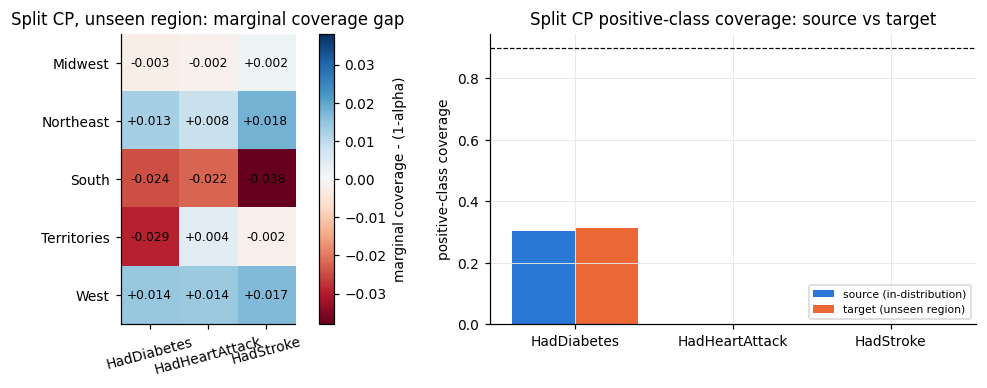

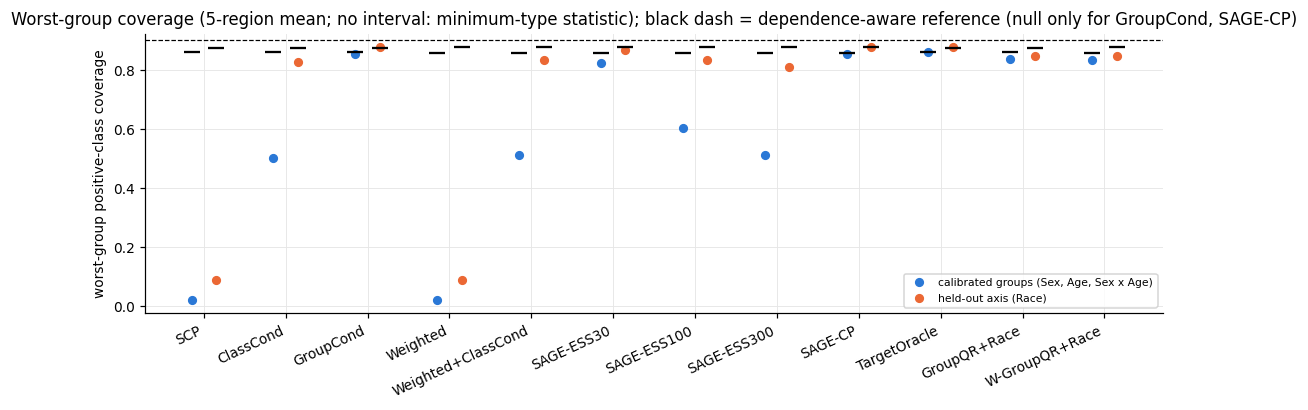

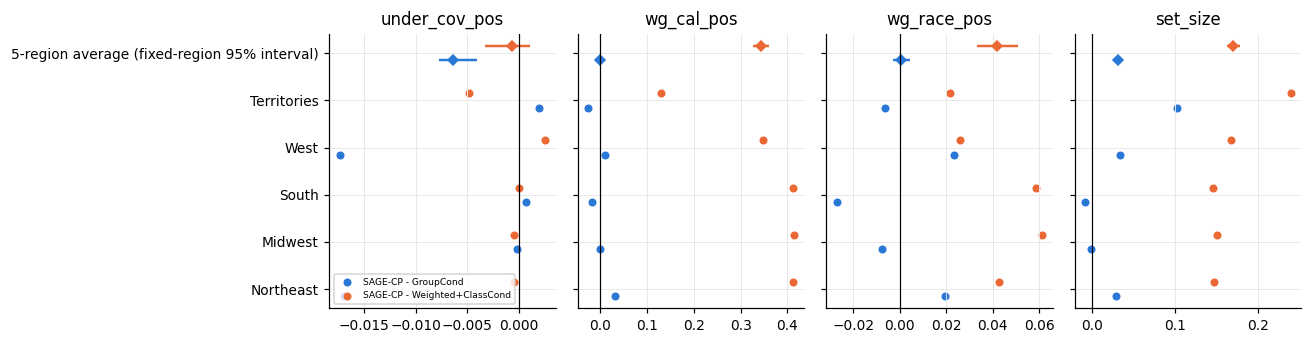

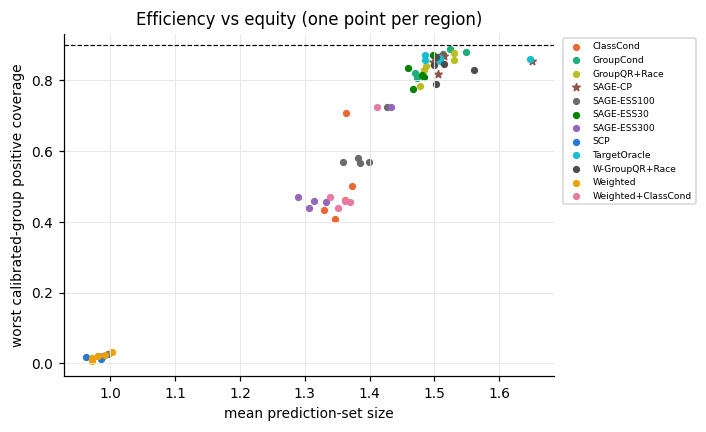

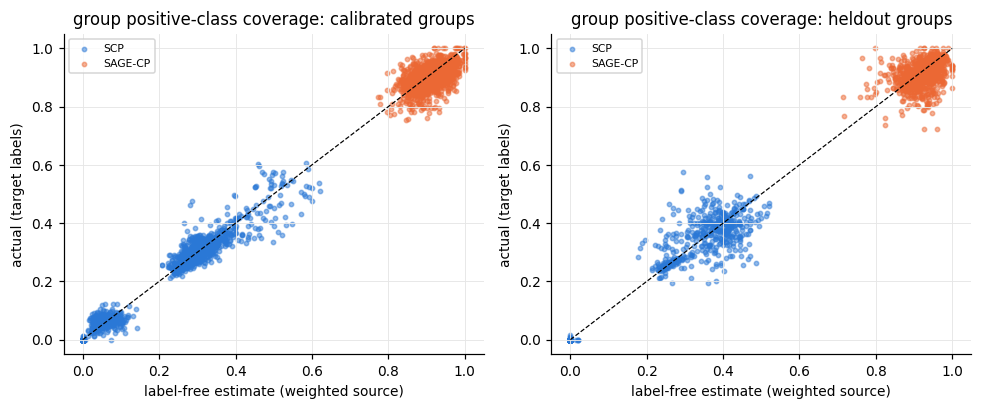

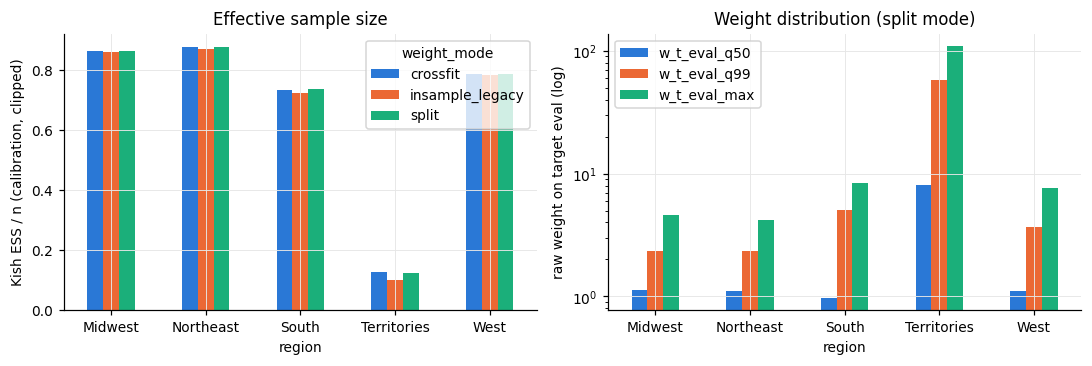

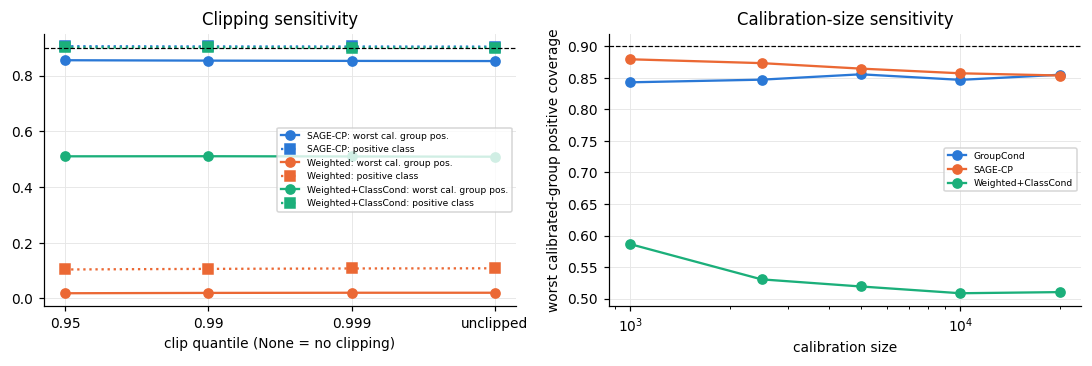

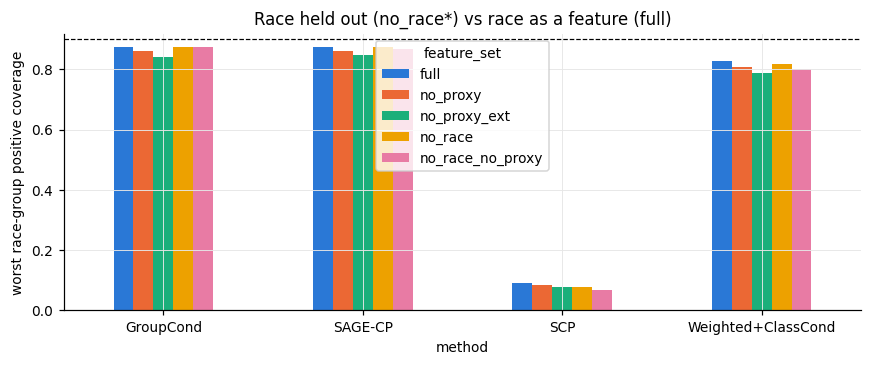

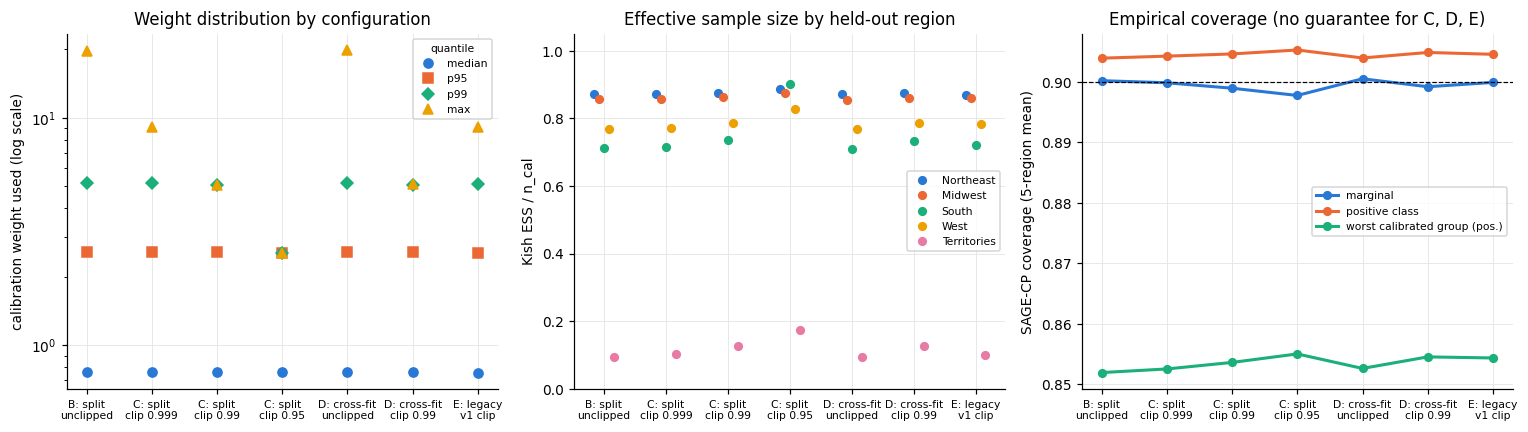

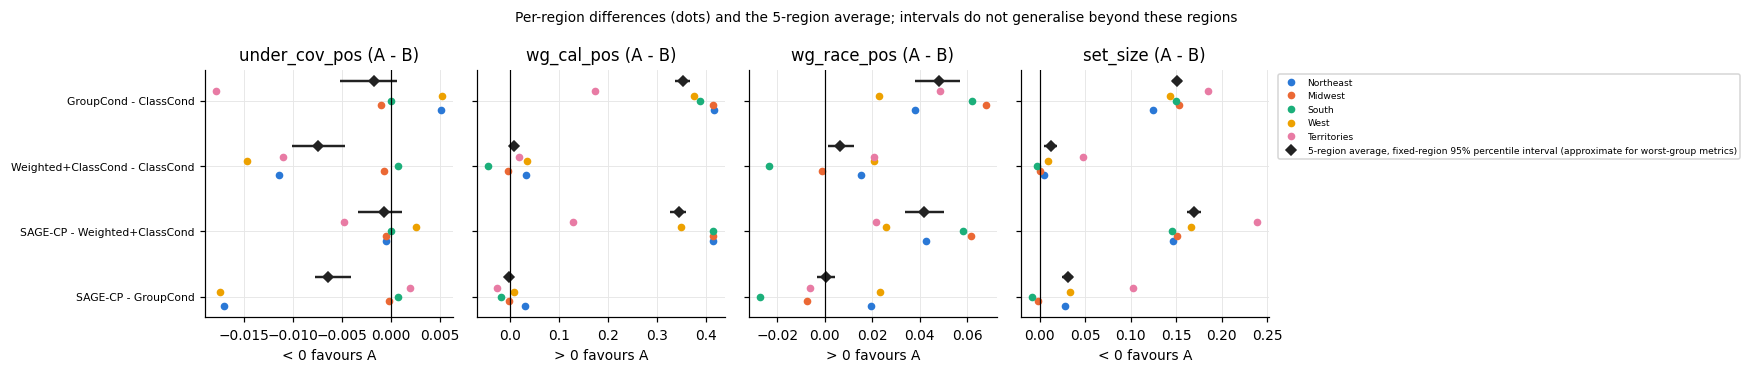

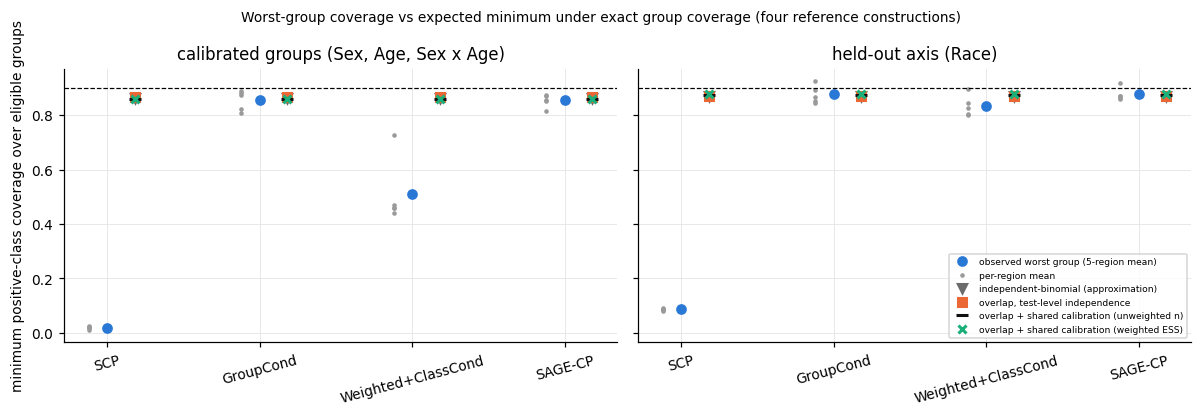

In [11]:
# ======================= 13. Figures (300 dpi; validated colour-blind-safe palette, one colour per method; v2 figures kept) =======================
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 300, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6})
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6b6b6b", "#9467bd", "#8c564b", "#17becf", "#bcbd22", "#4d4d4d", "#c49c94"]
METH_ORDER = [m for m in MAIN_METHODS + BASELINES if m in R.method.unique()]
COL = {m: PAL[i % len(PAL)] for i, m in enumerate(METH_ORDER)}
NOM = 1 - ALPHA
def _ivl(ax, pos, lo, hi, color, horizontal=False):
    """Draw intervals as segments from lo to hi (a basic-bootstrap interval need not contain the point estimate)."""
    pos, lo, hi = (np.atleast_1d(np.asarray(v, float)) for v in (pos, lo, hi))
    (ax.hlines if horizontal else ax.vlines)(pos, lo, hi, color=color, lw=1.6)
def finish(fig, name):
    if SYNTH: fig.text(0.5, 0.5, "SYNTHETIC SMOKE TEST", ha="center", va="center", fontsize=28, color="red", alpha=0.25, rotation=25)
    fig.tight_layout(); fig.savefig(f"{OUT}/{name}.png"); plt.show(); plt.close(fig)

# Fig 1: split CP - is the positive-class failure a SHIFT effect or a CLASS-IMBALANCE effect? (source vs target)
d = R[(R.exp == "main") & (R.variant == "primary") & (R.method == "SCP")]
if not d.empty:
    fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
    H = d[d.split == "target"].pivot_table(index="region", columns="outcome", values="coverage", aggfunc="mean") - NOM
    v = max(0.02, np.nanmax(np.abs(H.values)))
    im = axs[0].imshow(H.values, cmap="RdBu", vmin=-v, vmax=v)
    axs[0].set_xticks(range(H.shape[1]), H.columns, rotation=15); axs[0].set_yticks(range(H.shape[0]), H.index); axs[0].grid(False)
    for i in range(H.shape[0]):
        for j in range(H.shape[1]): axs[0].text(j, i, f"{H.values[i, j]:+.3f}", ha="center", va="center", fontsize=8)
    fig.colorbar(im, ax=axs[0], label="marginal coverage - (1-alpha)"); axs[0].set_title("Split CP, unseen region: marginal coverage gap")
    B_ = d.groupby(["outcome", "split"]).cov_pos.mean().unstack()
    x = np.arange(len(B_)); axs[1].bar(x - .2, B_["source"], .4, color=PAL[0], label="source (in-distribution)")
    axs[1].bar(x + .2, B_["target"], .4, color=PAL[1], label="target (unseen region)")
    axs[1].axhline(NOM, ls="--", c="k", lw=.8); axs[1].set_xticks(x, B_.index); axs[1].set_ylabel("positive-class coverage")
    axs[1].set_title("Split CP positive-class coverage: source vs target"); axs[1].legend(fontsize=7)
    finish(fig, "fig1_scp_shift_vs_imbalance")

# Fig 2: worst-group decomposition with finite-sample null reference
if not tab5.empty:
    t5 = tab5.set_index("method").reindex([m for m in METH_ORDER if m in tab5.method.values])
    fig, ax = plt.subplots(figsize=(10, 3.8)); x = np.arange(len(t5))
    for off, c, lab, colr in [(-.15, "wg_cal_pos", "calibrated groups (Sex, Age, Sex x Age)", PAL[0]), (.15, "wg_race_pos", "held-out axis (Race)", PAL[1])]:
        ax.plot(x + off, t5[c], "o", ms=5, color=colr, label=lab); _ivl(ax, x + off, t5[c + "_lo"], t5[c + "_hi"], colr)
        ref = [t5.loc[m_, f"ref_{ref_for(m_)}_{c.split('_')[1]}_mean"] for m_ in t5.index]
        ax.scatter(x + off, ref, marker="_", s=120, color="k", zorder=3)
    ax.axhline(NOM, ls="--", c="k", lw=.8); ax.set_xticks(x, t5.index, rotation=25, ha="right")
    ax.set_ylabel("worst-group positive-class coverage"); ax.legend(fontsize=7, loc="lower right")
    ax.set_title("Worst-group coverage (5-region mean; no interval: minimum-type statistic); black dash = dependence-aware reference (null only for GroupCond, SAGE-CP)")
    finish(fig, "fig2_worstgroup_decomposition")

# Fig 3: per-region paired differences (inference unit = region)
pairs = [("SAGE-CP", "GroupCond"), ("SAGE-CP", "Weighted+ClassCond")]
mets = ["under_cov_pos", "wg_cal_pos", "wg_race_pos", "set_size"]
if set(sum(pairs, ())) <= set(T_main.method):
    fig, axs = plt.subplots(1, len(mets), figsize=(12, 3.2), sharey=True)
    for a, mt in zip(axs, mets):
        for k, (A, Bm) in enumerate(pairs):
            c = compare(T_main[T_main.method == A], T_main[T_main.method == Bm], mt)
            regs = dict(s.split(":") for s in c["per_region"].split(";"))
            yv = np.arange(len(REG_LIST)) + (k - .5) * .3
            a.scatter([float(regs.get(r, np.nan)) for r in REG_LIST], yv, color=PAL[k], s=18, label=f"{A} - {Bm}")
            yy_ = len(REG_LIST) + (k - .5) * .3; a.plot(c["mean_diff"], yy_, "D", color=PAL[k], ms=5); _ivl(a, yy_, c["ci_lo"], c["ci_hi"], PAL[k], horizontal=True)
        a.axvline(0, c="k", lw=.8); a.set_title(mt)
    axs[0].set_yticks(list(range(len(REG_LIST))) + [len(REG_LIST)], REG_LIST + ["5-region average (fixed-region 95% interval)"]); axs[0].legend(fontsize=6, loc="lower left")
    finish(fig, "fig3_region_level_differences")

# Fig 4: efficiency vs equity (region-level points)
fig, ax = plt.subplots(figsize=(6.5, 4))
for meth, dm in T_main.groupby("method"):
    rr = dm.groupby("region")[["set_size", "wg_cal_pos"]].mean()
    ax.scatter(rr.set_size, rr.wg_cal_pos, s=26 if meth == "SAGE-CP" else 14, marker="*" if meth == "SAGE-CP" else "o",
               color=COL.get(meth, "#999"), label=meth)
ax.axhline(NOM, ls="--", c="k", lw=.8); ax.set_xlabel("mean prediction-set size"); ax.set_ylabel("worst calibrated-group positive coverage")
ax.legend(fontsize=6, loc="upper left", bbox_to_anchor=(1.01, 1)); ax.set_title("Efficiency vs equity (one point per region)")
finish(fig, "fig4_efficiency_vs_equity")

# Fig 5: monitoring estimate vs actual on aligned groups
if not mon_ok.empty:
    fig, axs = plt.subplots(1, 2, figsize=(9, 3.8))
    for a, at in zip(axs, ["calibrated", "heldout"]):
        for k, meth in enumerate(["SCP", "SAGE-CP"]):
            dd_ = mon_ok[(mon_ok.method == meth) & (mon_ok.axis_type == at)]
            a.scatter(dd_.cov_pos_est, dd_.cov_pos_act, s=8, alpha=.5, color=PAL[k], label=meth)
        a.plot([0, 1], [0, 1], "k--", lw=.8); a.set_xlabel("label-free estimate (weighted source)"); a.set_ylabel("actual (target labels)")
        a.set_title(f"group positive-class coverage: {at} groups"); a.legend(fontsize=7)
    finish(fig, "fig5_monitoring_aligned")

# Fig 6: weight diagnostics
w6 = WD[(WD.exp == "main") & WD.is_primary_config]
if not w6.empty:
    fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
    p6 = w6.groupby(["region", "weight_mode"]).ess_cal_frac.mean().unstack()
    p6.plot.bar(ax=axs[0], color=PAL[:p6.shape[1]], rot=0); axs[0].set_ylabel("Kish ESS / n (calibration, clipped)"); axs[0].set_title("Effective sample size")
    p7 = w6[(w6.weight_mode == CFG["WEIGHT_MODE"]) & w6.is_primary_config].groupby("region")[["w_t_eval_q50", "w_t_eval_q99", "w_t_eval_max"]].mean()
    p7.plot.bar(ax=axs[1], logy=True, color=PAL[:3], rot=0); axs[1].set_ylabel("raw weight on target eval (log)"); axs[1].set_title("Weight distribution (split mode)")
    finish(fig, "fig6_weight_diagnostics")

# Fig 7: clip and calibration-size sensitivity
if not tab9.empty or not tab10.empty:
    fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
    for k, (meth, d_) in enumerate(tab9.groupby("method")):
        axs[0].plot(d_.clip_q.astype(str), d_.wg_cal_pos, "-o", color=PAL[k], label=f"{meth}: worst cal. group pos.")
        axs[0].plot(d_.clip_q.astype(str), d_.cov_pos, ":s", color=PAL[k], label=f"{meth}: positive class")
    axs[0].axhline(NOM, ls="--", c="k", lw=.8); axs[0].set_xlabel("clip quantile (None = no clipping)"); axs[0].legend(fontsize=6); axs[0].set_title("Clipping sensitivity")
    for k, (meth, d_) in enumerate(tab10.groupby("method")):
        axs[1].plot(d_.n_cal_used, d_.wg_cal_pos, "-o", color=PAL[k], label=meth)
    axs[1].set_xscale("log"); axs[1].axhline(NOM, ls="--", c="k", lw=.8); axs[1].set_xlabel("calibration size")
    axs[1].set_ylabel("worst calibrated-group positive coverage"); axs[1].legend(fontsize=6); axs[1].set_title("Calibration-size sensitivity")
    finish(fig, "fig7_clip_and_ncal_sensitivity")

# Fig 8: feature-set experiments
if not tab11.empty:
    fig, ax = plt.subplots(figsize=(8, 3.4)); p8 = tab11.pivot_table(index="method", columns="feature_set", values="wg_race_pos")
    p8.plot.bar(ax=ax, color=PAL[:p8.shape[1]], rot=0); ax.axhline(NOM, ls="--", c="k", lw=.8)
    ax.set_ylabel("worst race-group positive coverage"); ax.set_title("Race held out (no_race*) vs race as a feature (full)")
    finish(fig, "fig8_feature_sets")

# ---------------- figure_weight_clipping (Issue 2) ----------------
CFG_ORDER = [("split", "unclipped"), ("split", "0.999"), ("split", "0.99"), ("split", "0.95"), ("crossfit", "unclipped"), ("crossfit", "0.99"), ("insample_legacy", "legacy")]
def _cfg_label(wm, cq):
    t = weight_type(wm, cq).split(":")[0]
    return f"{t}: {'split' if wm == 'split' else 'cross-fit' if wm == 'crossfit' else 'legacy'}\n{'unclipped' if cq == 'unclipped' else 'clip ' + cq if cq != 'legacy' else 'v1 clip'}"
wc_ = TWC[TWC.method == "SAGE-CP"].set_index(["weight_mode", "clip_q"])
order = [k for k in CFG_ORDER if k in wc_.index]
if order:
    fig, axs = plt.subplots(1, 3, figsize=(14, 4.0)); x = np.arange(len(order)); labs = [_cfg_label(*k) for k in order]
    for j, (s, mk) in enumerate([("median", "o"), ("p95", "s"), ("p99", "D"), ("max", "^")]):
        axs[0].plot(x, [wc_.loc[k, f"wcal_used_{s}"] for k in order], mk, color=PAL[j], ms=6, label=s, ls="none")
    axs[0].set_yscale("log"); axs[0].set_xticks(x, labs, fontsize=7); axs[0].set_ylabel("calibration weight used (log scale)")
    axs[0].legend(fontsize=7, title="quantile", title_fontsize=7); axs[0].set_title("Weight distribution by configuration")
    wr = TWC_R[TWC_R.method == "SAGE-CP"].set_index(["weight_mode", "clip_q", "region"])
    for j, rg in enumerate(REG_LIST):
        yv = [wr.loc[(k[0], k[1], rg), "ess_cal_frac"] if (k[0], k[1], rg) in wr.index else np.nan for k in order]
        axs[1].plot(x + (j - 2) * .08, yv, "o", ms=5, color=PAL[j], label=rg)
    axs[1].set_xticks(x, labs, fontsize=7); axs[1].set_ylabel("Kish ESS / n_cal"); axs[1].set_ylim(0, 1.05)
    axs[1].legend(fontsize=7); axs[1].set_title("Effective sample size by held-out region")
    for j, (m_, lab) in enumerate([("coverage", "marginal"), ("cov_pos", "positive class"), ("wg_cal_pos", "worst calibrated group (pos.)")]):
        axs[2].plot(x, [wc_.loc[k, m_] for k in order], "-o", color=PAL[j], ms=5, lw=2, label=lab)
    axs[2].axhline(NOM, ls="--", c="k", lw=.8); axs[2].set_xticks(x, labs, fontsize=7); axs[2].set_ylabel("SAGE-CP coverage (5-region mean)")
    axs[2].legend(fontsize=7); axs[2].set_title("Empirical coverage (no guarantee for C, D, E)")
    finish(fig, "figure_weight_clipping")

# ---------------- figure_region_effects (Issue 3) ----------------
FIG_CMP = [c for c in ["SAGE-CP - GroupCond", "SAGE-CP - Weighted+ClassCond", "Weighted+ClassCond - ClassCond", "GroupCond - ClassCond"] if c in set(tab4.comparison)]
FIG_MET = ["under_cov_pos", "wg_cal_pos", "wg_race_pos", "set_size"]
if FIG_CMP:
    fig, axs = plt.subplots(1, len(FIG_MET), figsize=(16, 3.4), sharey=True)
    for a, mt in zip(axs, FIG_MET):
        for i, cmp_ in enumerate(FIG_CMP):
            r_ = tab4[(tab4.comparison == cmp_) & (tab4.metric == mt)]
            if r_.empty: continue
            r_ = r_.iloc[0]; per = dict(s.split(":") for s in r_.per_region.split(";")) if r_.per_region else {}
            for j, rg in enumerate(REG_LIST):
                a.plot(float(per.get(rg, np.nan)), i + (j - 2) * .07, "o", ms=4, color=PAL[j], label=rg if (i == 0 and mt == FIG_MET[0]) else None)
            a.plot(r_.mean_diff, i + .3, "D", color="#222222", ms=5, label="5-region average, fixed-region 95% percentile interval (approximate for worst-group metrics)" if (i == 0 and mt == FIG_MET[0]) else None)
            _ivl(a, i + .3, r_.ci_lo, r_.ci_hi, "#222222", horizontal=True)
        a.axvline(0, c="k", lw=.8); a.set_title(f"{mt} (A - B)"); a.set_xlabel(DIRECTION.get(mt) == 1 and "> 0 favours A" or "< 0 favours A")
    axs[0].set_yticks(range(len(FIG_CMP)), FIG_CMP, fontsize=7)
    h_, l_ = axs[0].get_legend_handles_labels(); axs[-1].legend(h_, l_, fontsize=6, loc="upper left", bbox_to_anchor=(1.02, 1))
    fig.suptitle("Per-region differences (dots) and the 5-region average; intervals do not generalise beyond these regions", fontsize=9)
    finish(fig, "figure_region_effects")

# ---------------- figure_worst_group_reference (Issue 4) ----------------
tw = tab5.set_index("method").reindex([m for m in WG_METHODS if m in tab5.method.values])
if not tw.empty:
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True); x = np.arange(len(tw))
    for a, ax_ in zip(axs, ["cal", "race"]):
        a.plot(x, tw[f"wg_{ax_}_pos"], "o", color=PAL[0], ms=6, label="observed worst group (5-region mean)")
        for j_, rg in enumerate(REG_LIST):     # per-region values instead of an (invalid) interval
            vv = sel(methods=list(tw.index), region=rg).groupby("method")[f"wg_{ax_}_pos"].mean().reindex(tw.index)
            a.plot(x - .12, vv, ".", ms=4, color="#9a9a9a", label="per-region mean" if j_ == 0 else None)
        for j, (ref, mk, lab) in enumerate([("indep", "v", "independent-binomial (approximation)"), ("overlap", "s", "overlap, test-level independence"),
                                            ("overlap_beta", "_", "overlap + shared calibration (unweighted n)"),
                                            ("overlap_beta_ess", "x", "overlap + shared calibration (weighted ESS)")]):
            a.plot(x + .18, tw[f"ref_{ref}_{ax_}_mean"], mk, ms=8 if mk == "_" else 5, mew=2, color=["#6b6b6b", PAL[1], "#111111", PAL[2]][j], ls="none", label=lab)
        a.axhline(NOM, ls="--", c="k", lw=.8); a.set_xticks(x, tw.index, rotation=15)
        a.set_title({"cal": "calibrated groups (Sex, Age, Sex x Age)", "race": "held-out axis (Race)"}[ax_])
    axs[0].set_ylabel("minimum positive-class coverage over eligible groups"); axs[1].legend(fontsize=6, loc="lower right")
    fig.suptitle("Worst-group coverage vs expected minimum under exact group coverage (four reference constructions)", fontsize=9)
    finish(fig, "figure_worst_group_reference")

[PASS] Test S: [none] oracle weights (Tier 1): every calibrated group's mean positive coverage >= 1-alpha - 3 MC SE
[PASS] Test S: [none] estimated / clipped weights (Tiers 2-3): per-cell coverage >= 1-alpha - TV - 3 MC SE
[PASS] Test S: [strong] oracle weights (Tier 1): every calibrated group's mean positive coverage >= 1-alpha - 3 MC SE
[PASS] Test S: [strong] estimated / clipped weights (Tiers 2-3): per-cell coverage >= 1-alpha - TV - 3 MC SE
[PASS] Test S: [strong] clipping raises calibration ESS (C 0.95 >= C 0.99 >= B unclipped)
[PASS] Test S: [concept] T1a violated: oracle-weighted SAGE-CP is NOT expected to keep coverage (documented, not a pass criterion)
[PASS] Test S: [concept_harm] T1a violated: oracle-weighted SAGE-CP is NOT expected to keep coverage (documented, not a pass criterion)
[PASS] Test S: [prior] T1a violated: oracle-weighted SAGE-CP is NOT expected to keep coverage (documented, not a pass criterion)
SIMULATION: smallest per-group mean positive coverage (over repl

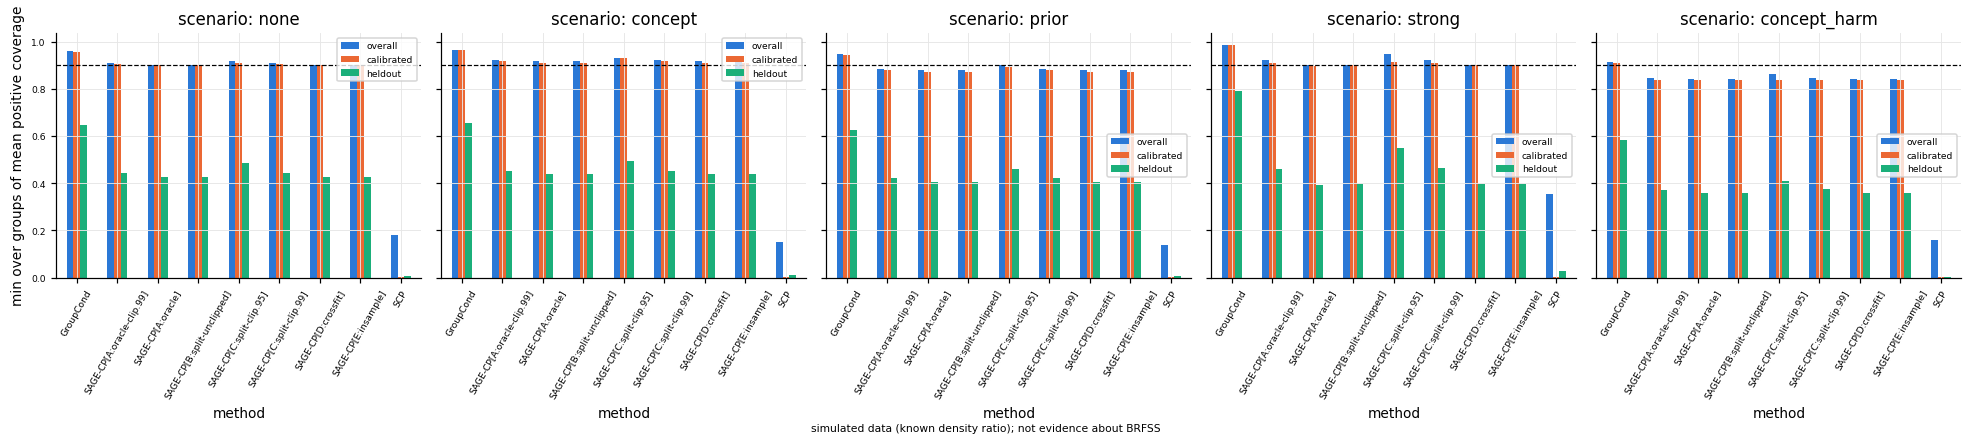

In [12]:
# ======================= 14. Simulation: known density ratio (I), concept and prior shift (J), estimated and clipped weights (Issue 7) =======================
# Source x ~ N(0, I_6); target x ~ N(mu, I_6)  =>  true w(x) = exp(mu.x - |mu|^2/2).
# Groups are functions of x: "Sex" = sign(x0), "Age" = tertiles of x1 (source cut points), "Race" = bins of x2 (held out).
# Scenarios: none (covariate shift only), strong (covariate shift with 2 x mu: heavier weight tails, where clipping binds),
# concept (v2: P(y|x) raised in the target for x2 > 0.5 - positives appear where the model already scores them high, so
# positive-class coverage does NOT fall; kept for continuity), concept_harm (v2.1: P(y|x) raised where x2 < -0.5, i.e. where
# the model scores positives LOW - a harmful concept shift) and prior (target intercept +0.7). Under concept and prior shift
# assumption T1a fails, so no weighting - oracle included - can be relied on to restore coverage.
# Weight types: A oracle (and A clipped), B split unclipped, C split clipped (0.99, 0.95; threshold from the domain
# fold, as in the real-data pipeline), D cross-fitted, E in-sample (v1-style).
# Tier-2/3 bound check (covariate-shift scenarios only): for every Sex x Age cell g, mean positive-class coverage over
# replications >= 1 - alpha - E[TV_g], TV_g = 1/2 E_{P(x|y=1,g)} | w/E[w] - w_hat/E[w_hat] |, estimated on a fresh source sample.
# THIS VALIDATES THE IMPLEMENTATION UNDER STATED ASSUMPTIONS. IT IS NOT EVIDENCE THAT BRFSS SATISFIES COVARIATE SHIFT.
SIM = dict(R=200, n=4000, n_tv=20000, mu=np.array([0.5, 0.3, 0.4, 0, 0, 0]),
           scenarios={"none": 0.0, "concept": 1.0, "prior": 0.7, "strong": 2.0, "concept_harm": 1.5})   # v2 order kept (seeds); new scenarios appended
if CFG["QUICK"]: SIM.update(R=8, n=1500, n_tv=5000)

def sim_mu(scenario): return SIM["mu"] * (SIM["scenarios"]["strong"] if scenario == "strong" else 1.0)

def sim_draw(n, rng, target=False, scenario="none"):
    X = rng.normal(size=(n, 6)) + (sim_mu(scenario) if target else 0)
    lo = -3.2 + .9 * X[:, 0] + .6 * X[:, 1] + 1.0 * X[:, 2] + .5 * X[:, 3]
    if target and scenario == "concept": lo = lo + SIM["scenarios"]["concept"] * (X[:, 2] > .5)
    if target and scenario == "prior": lo = lo + SIM["scenarios"]["prior"]
    if target and scenario == "concept_harm": lo = lo + SIM["scenarios"]["concept_harm"] * (X[:, 2] < -.5)
    y = (rng.random(n) < 1 / (1 + np.exp(-lo))).astype(int)
    sx = np.where(X[:, 0] > 0, "S1", "S2"); ag = np.where(X[:, 1] < -.43, "A1", np.where(X[:, 1] < .43, "A2", "A3"))
    gdf = pd.DataFrame({"Sex": sx, "Age": ag, "Race": np.where(X[:, 2] > .5, "R1", np.where(X[:, 2] < -.5, "R3", "R2")),
                        "SexxAge": pd.Series(sx) + "|" + pd.Series(ag)})
    return X, y, gdf

def true_w(X, scenario): mu = sim_mu(scenario); return np.exp(X @ mu - mu @ mu / 2)

def tv_half(w, wh):
    if len(w) == 0: return np.nan
    return 0.5 * np.mean(np.abs(w / w.mean() - wh / wh.mean()))

sim_rows, sim_mon, sim_w = [], [], []
for scen in SIM["scenarios"]:
    for rep in range(SIM["R"]):
        rng = np.random.default_rng(10_000 + rep + 1000 * list(SIM["scenarios"]).index(scen)); n = SIM["n"]
        Xtr, ytr, _ = sim_draw(n, rng); Xc, yc_, gc = sim_draw(n, rng); Xd, _, _ = sim_draw(n, rng); Xs, ys, gs = sim_draw(n, rng)
        Xu, _, _ = sim_draw(n, rng, True, scen); Xe, ye, ge = sim_draw(n, rng, True, scen)
        mdl = LogisticRegression(max_iter=500).fit(Xtr, ytr)
        p = {k: mdl.predict_proba(v)[:, 1] for k, v in dict(c=Xc, s=Xs, e=Xe).items()}
        kc = [gc.SexxAge.values, gc.Age.values, np.array(["all"] * n)]; ke = [ge.SexxAge.values, ge.Age.values, np.array(["all"] * n)]
        ks = [gs.SexxAge.values, gs.Age.values, np.array(["all"] * n)]
        md = fit_domain(Xd, Xu)                                                     # split: separate source fold
        fold = rng.permutation(np.arange(n) % CFG["CROSSFIT_K"]); w_cf = np.empty(n); mcf = []
        for k in range(CFG["CROSSFIT_K"]):
            mk = fit_domain(Xc[fold != k], Xu); mcf.append(mk); w_cf[fold == k] = weights_from([mk], Xc[fold == k])
        mi = fit_domain(Xc, Xu)                                                     # v1-style: classifier sees calibration points
        Xb, yb, gb = sim_draw(SIM["n_tv"], rng)        # fresh source sample for TV distances (drawn last: v2 random streams unchanged)
        fw = {"oracle": lambda X_: true_w(X_, scen), "split": lambda X_: weights_from([md], X_)}
        cv = {"oracle": {q: np.quantile(true_w(Xd, scen), q) for q in (.99,)}, "split": {q: np.quantile(weights_from([md], Xd), q) for q in (.99, .95)}}
        W = {"A:oracle": (true_w(Xc, scen), true_w(Xe, scen), true_w(Xs, scen), true_w(Xb, scen)),
             "A:oracle-clip.99": tuple(np.minimum(true_w(X_, scen), cv["oracle"][.99]) for X_ in (Xc, Xe, Xs, Xb)),
             "B:split-unclipped": tuple(fw["split"](X_) for X_ in (Xc, Xe, Xs, Xb)),
             "C:split-clip.99": tuple(np.minimum(fw["split"](X_), cv["split"][.99]) for X_ in (Xc, Xe, Xs, Xb)),
             "C:split-clip.95": tuple(np.minimum(fw["split"](X_), cv["split"][.95]) for X_ in (Xc, Xe, Xs, Xb)),
             "D:crossfit": (w_cf, weights_from(mcf, Xe), weights_from(mcf, Xs), weights_from(mcf, Xb)),
             "E:insample": (weights_from([mi], Xc), weights_from([mi], Xe), weights_from([mi], Xs), weights_from([mi], Xb))}
        wtrue_b = true_w(Xb, scen)
        for wn, (wc_, we_, ws_, wb_) in W.items():
            r_ = dict(scenario=scen, rep=rep, weights=wn, tv_overall=tv_half(wtrue_b, wb_), ess_cal_frac=kish(wc_) / n,
                      max_w_cal=wc_.max(), mean_w_srctest=ws_.mean())
            for cell in sorted(set(gb.SexxAge)):
                mm = (gb.SexxAge.values == cell) & (yb == 1); r_[f"tv_pos_{cell}"] = tv_half(wtrue_b[mm], wb_[mm])
            sim_w.append(r_)
        sets = {"SCP": (conformal_sets(p["c"], yc_, p["e"], ALPHA), conformal_sets(p["c"], yc_, p["s"], ALPHA), None),
                "GroupCond": (sage_sets(p["c"], yc_, kc, p["e"], ke, ALPHA, min_ess=1)[0],
                              sage_sets(p["c"], yc_, kc, p["s"], ks, ALPHA, min_ess=1)[0], None)}
        for wn, (wc_, we_, ws_, _) in W.items():
            sets[f"SAGE-CP[{wn}]"] = (sage_sets(p["c"], yc_, kc, p["e"], ke, ALPHA, wc_, we_, min_ess=1)[0],
                                      sage_sets(p["c"], yc_, kc, p["s"], ks, ALPHA, wc_, ws_, min_ess=1)[0], wn)
        for meth, (Se, Ss, wn) in sets.items():
            sm = set_metrics(Se, ye, ALPHA); gt = group_table(Se, ye, ge)
            for r_ in gt.to_dict("records"):
                sim_rows.append(dict(scenario=scen, rep=rep, method=meth, **r_))
            sim_rows.append(dict(scenario=scen, rep=rep, method=meth, axis="overall", axis_type="overall", group="all",
                                 n=sm["n"], n_pos=sm["n_pos"], cov=sm["coverage"], cov_pos=sm["cov_pos"], set_size=sm["set_size"]))
            for wmon in ["A:oracle", "B:split-unclipped", "C:split-clip.99"]:      # label-free monitor with oracle / estimated weights
                est = group_table(Ss, ys, gs, w=W[wmon][2]); mt = monitor_table(est, gt)
                mt = mt[mt.axis_type == "calibrated"]
                cs = Ss[np.arange(n), ys]; ct = Se[np.arange(n), ye]
                sim_mon.append(dict(scenario=scen, rep=rep, method=meth, monitor_weights=wmon,
                                    est_cov_pos=np.average(cs[ys == 1], weights=W[wmon][2][ys == 1]), act_cov_pos=ct[ye == 1].mean(),
                                    est_cov=np.average(cs, weights=W[wmon][2]), act_cov=ct.mean(),
                                    mae_group_pos=(mt.cov_pos_est - mt.cov_pos_act).abs().mean()))
SR = pd.DataFrame(sim_rows); SMON = pd.DataFrame(sim_mon); SW = pd.DataFrame(sim_w)
for t_ in (SR, SMON, SW): t_.insert(0, "data_source", "SIMULATION")
SR.to_csv(f"{OUT}/sim_results.csv", index=False); SMON.to_csv(f"{OUT}/sim_monitoring.csv", index=False); SW.to_csv(f"{OUT}/sim_weights.csv", index=False)

agg = SR.groupby(["scenario", "method", "axis_type", "axis", "group"]).agg(
    mean_cov_pos=("cov_pos", "mean"), mc_se=("cov_pos", lambda s: s.std() / np.sqrt(s.notna().sum())),
    frac_reps_below_thr=("cov_pos", lambda s: (s < 1 - ALPHA - CFG["ALARM_TOL"]).mean()), mean_n_pos=("n_pos", "mean")).reset_index()
agg.to_csv(f"{OUT}/table_sim_group_coverage.csv", index=False)
tab_sim = agg.groupby(["scenario", "method", "axis_type"]).agg(min_group_mean_cov_pos=("mean_cov_pos", "min"),
                                                               max_mc_se=("mc_se", "max")).reset_index()
SMON["ae_pos"] = (SMON.est_cov_pos - SMON.act_cov_pos).abs()
tab_sim_mon = SMON.groupby(["scenario", "method", "monitor_weights"]).agg(
    mean_est_cov_pos=("est_cov_pos", "mean"), mean_act_cov_pos=("act_cov_pos", "mean"),
    mae_overall_pos=("ae_pos", "mean"), mae_group_pos=("mae_group_pos", "mean")).reset_index()
tab_sim.to_csv(f"{OUT}/table_sim_summary.csv", index=False); tab_sim_mon.to_csv(f"{OUT}/table_sim_monitoring.csv", index=False)
tab_sim.pivot_table(index=["scenario", "method"], columns="axis_type", values=["min_group_mean_cov_pos", "max_mc_se"]).round(4) \
       .to_csv(f"{OUT}/simulation_verification_summary.csv")
SWa = SW.groupby(["scenario", "weights"]).mean(numeric_only=True).drop(columns="rep").reset_index()
SWa.to_csv(f"{OUT}/table_sim_weights.csv", index=False)
# ---- Tier-2/3 bound check per Sex x Age cell (positive class) ----
brows = []
for (scen, wn), d in SW.groupby(["scenario", "weights"]):
    for cell in sorted(c.replace("tv_pos_", "") for c in SW.columns if c.startswith("tv_pos_")):
        a = agg[(agg.scenario == scen) & (agg.method == f"SAGE-CP[{wn}]") & (agg.axis == "SexxAge") & (agg.group == cell)]
        if a.empty: continue
        tv = d[f"tv_pos_{cell}"].mean(); bound = 1 - ALPHA - tv; mc = a.mean_cov_pos.iloc[0]; se = a.mc_se.iloc[0]
        brows.append(dict(scenario=scen, weights=wn, cell=cell, mean_cov_pos=mc, mc_se=se, mean_tv_pos=tv, bound=bound, slack=mc - bound,
                          bound_applicable=scen in ("none", "strong") and not wn.startswith("D") and not wn.startswith("E"),
                          holds_within_3se=mc >= bound - 3 * se))
TB = pd.DataFrame(brows); TB.insert(0, "data_source", "SIMULATION"); TB.to_csv(f"{OUT}/table_sim_tv_bound.csv", index=False)
crit_sim = not CFG["QUICK"]
for scen in ["none", "strong"]:
    a = agg[(agg.scenario == scen) & (agg.method == "SAGE-CP[A:oracle]") & (agg.axis_type == "calibrated")]
    check("S", f"[{scen}] oracle weights (Tier 1): every calibrated group's mean positive coverage >= 1-alpha - 3 MC SE",
          bool(((a.mean_cov_pos >= 1 - ALPHA - 3 * a.mc_se) | a.mean_cov_pos.isna()).all()), f">= {1-ALPHA} - 3SE",
          f"min {a.mean_cov_pos.min():.4f} (max SE {a.mc_se.max():.4f})", critical=crit_sim)
    tb = TB[(TB.scenario == scen) & TB.bound_applicable]
    check("S", f"[{scen}] estimated / clipped weights (Tiers 2-3): per-cell coverage >= 1-alpha - TV - 3 MC SE",
          bool(tb.holds_within_3se.all()), "all cells", f"min slack {tb.slack.min():+.4f}; failing: {tb[~tb.holds_within_3se][['weights','cell']].values.tolist()}",
          critical=crit_sim)
sw_ = SWa[SWa.scenario == "strong"].set_index("weights")
check("S", "[strong] clipping raises calibration ESS (C 0.95 >= C 0.99 >= B unclipped)",
      sw_.loc["C:split-clip.95", "ess_cal_frac"] >= sw_.loc["C:split-clip.99", "ess_cal_frac"] >= sw_.loc["B:split-unclipped", "ess_cal_frac"],
      "monotone", sw_.loc[["B:split-unclipped", "C:split-clip.99", "C:split-clip.95"], "ess_cal_frac"].round(3).tolist(), critical=False)
for scen in ["concept", "concept_harm", "prior"]:
    a = agg[(agg.scenario == scen) & (agg.method == "SAGE-CP[A:oracle]") & (agg.axis_type == "calibrated")]
    check("S", f"[{scen}] T1a violated: oracle-weighted SAGE-CP is NOT expected to keep coverage (documented, not a pass criterion)",
          True, "informational", f"min calibrated-group mean positive coverage {a.mean_cov_pos.min():.4f}; positive class overall "
          f"{agg[(agg.scenario == scen) & (agg.method == 'SAGE-CP[A:oracle]') & (agg.axis_type == 'overall')].mean_cov_pos.min():.4f}", critical=False)
print("SIMULATION: smallest per-group mean positive coverage (over replications) by axis type\n",
      tab_sim.pivot_table(index=["scenario", "method"], columns="axis_type", values="min_group_mean_cov_pos").round(3).to_string())
print("\nSIMULATION weights (TV = distance between true and used weights; 0 for oracle)\n", SWa[["scenario", "weights", "tv_overall", "ess_cal_frac"]].round(4).to_string())
print("\nTier-2/3 bound check (covariate-shift scenarios)\n", TB[TB.bound_applicable].groupby(["scenario", "weights"]).slack.min().round(4).to_string())
print("\nSIMULATION monitoring (overall positive-class coverage)\n", tab_sim_mon.round(3).to_string())

fig, axs = plt.subplots(1, len(SIM["scenarios"]), figsize=(18, 4), sharey=True)
for a, scen in zip(axs, SIM["scenarios"]):
    t = tab_sim[tab_sim.scenario == scen].pivot_table(index="method", columns="axis_type", values="min_group_mean_cov_pos")
    t = t.reindex(columns=[c for c in ["overall", "calibrated", "heldout"] if c in t.columns])
    t.plot.bar(ax=a, color=PAL[:t.shape[1]], rot=60, fontsize=6); a.axhline(NOM, ls="--", c="k", lw=.8); a.set_title(f"scenario: {scen}")
    a.set_ylabel("min over groups of mean positive coverage"); a.legend(fontsize=6)
fig.text(0.5, 0.01, "simulated data (known density ratio); not evidence about BRFSS", ha="center", fontsize=7)
fig.tight_layout(); fig.savefig(f"{OUT}/fig9_simulation.png"); plt.show(); plt.close(fig)

In [13]:
# ======================= 15. Post-run validation (tests C, E-integration, G, R), experiments A-K status and claim audit =======================
# ---------------- Test C: region-level inference does not treat cells as independent ----------------
_dA, _dB = T_main[T_main.method == "SAGE-CP"], T_main[T_main.method == "GroupCond"]
def _dup(d):   # duplicate every cell under a new model name, with identical bootstrap replicates
    d2 = d.assign(model=d.model + "_dup")
    for r_ in d.itertuples(index=False):
        k = tuple(getattr(r_, c) for c in KEYCOLS)
        if k in BOOT: BOOT[k[:4] + (k[4] + "_dup",) + k[5:]] = BOOT[k]
    return pd.concat([d, d2], ignore_index=True)
RNG = np.random.default_rng(99); _c1 = region_inference(_dA, "under_cov_pos", _dB)
_dA2, _dB2 = _dup(_dA), _dup(_dB)
RNG = np.random.default_rng(99); _c2 = region_inference(_dA2, "under_cov_pos", _dB2)
check("C", "duplicating every cell leaves the estimate and the interval unchanged (no pseudo-replication)",
      np.isclose(_c1["point"], _c2["point"], equal_nan=True) and np.isclose(_c1["ci_fixed_lo"], _c2["ci_fixed_lo"], equal_nan=True)
      and np.isclose(_c1["ci_fixed_hi"], _c2["ci_fixed_hi"], equal_nan=True) and _c2["n_cells"] == 2 * _c1["n_cells"],
      f"{_c1['point']:.5f} [{_c1['ci_fixed_lo']:.5f}, {_c1['ci_fixed_hi']:.5f}]", f"{_c2['point']:.5f} [{_c2['ci_fixed_lo']:.5f}, {_c2['ci_fixed_hi']:.5f}]")
for k in [k for k in BOOT if str(k[4]).endswith("_dup")]: del BOOT[k]
RNG = np.random.default_rng(CFG["BOOT_SEED"])
_m = _dA.merge(_dB, on=["seed", "region", "outcome", "model"], suffixes=("", "_B"))
_direct = (_m.under_cov_pos - _m.under_cov_pos_B).groupby([_m.region, _m.seed]).mean().groupby(level=0).mean()
check("C", "per-region effects equal an independent recomputation (cells -> region x seed -> region; one value per region)",
      len(_direct) == _c1["n_regions"] and all(np.isclose(_direct[r], _c1["per_region"][r]) for r in _direct.index), _direct.round(5).to_dict(),
      {k: round(v, 5) for k, v in _c1["per_region"].items()})
check("C", "no interval is reported for worst-group LEVELS (minimum-type: bootstrap not valid)",
      bool(tab1[tab1.metric.map(is_min_type)].ci_lo.isna().all()), "all NaN", int(tab1[tab1.metric.map(is_min_type)].ci_lo.notna().sum()))
check("C", "sign-symmetry reference p with 5 regions cannot go below 2/32 = 0.0625", np.isclose(signflip_p(np.ones(5)), 0.0625), 0.0625, signflip_p(np.ones(5)))
check("C", "fixed-region interval resamples evaluation samples where replicates exist",
      bool(tab4.ci_method.str.contains("evaluation sample").any()), "present", tab4.ci_method.value_counts().to_dict())

# ---------------- Test E (integration): preprocessing in the real engine ----------------
check("E", "no encoder received an outcome, other-diagnosis, State or Region column (from fitted encoders' input names)",
      not PRE.outcome_in_encoder_input.any(), "False", bool(PRE.outcome_in_encoder_input.any()))
for e_ in [e["name"] for e in EXPERIMENTS if "no_race" in e["feature_set"]]:
    pe = PRE[PRE.exp == e_]
    if len(pe):
        check("E", f"{e_}: race absent from BOTH the base-model and the density-ratio encoders", not (pe.race_in_base.any() or pe.race_in_domain.any()),
              "absent", (pe.race_in_base.any(), pe.race_in_domain.any()))
_un = PRE.unseen_base_t_eval.map(lambda s: sum(json.loads(s).values()))
check("E", "unseen target categories are encoded safely and counted (engine completed with them)",
      (_un.sum() > 0 and all(v.startswith("complete") for v in EXP_STATUS.values())) if SYNTH else True,
      ">0 unseen in synthetic t_eval, runs complete", f"{int(_un.sum())} unseen row-variables", critical=SYNTH)
# label-permutation invariance of preprocessing and weights (one unit), with a positive control showing the check can fail
_s0, _r0 = CFG["SEEDS"][0], REG_LIST[0]; _P = partitions(_s0, _r0)
def _enc_w(leak=False):
    _X_CACHE.clear(); Xr, nu, ca = build_X("full")
    if leak: Xr = Xr.assign(_label_leak=np.nan_to_num(code_outcome(ACTIVE_OUTCOMES[0], "yes_only"))); nu = nu + ["_label_leak"]
    eb = fit_encoder(Xr, _P["s_train"], nu, ca); ed = fit_encoder(Xr, np.r_[_P["s_dom"], _P["t_unlab"]], nu, ca)
    XDp = {k: encode(ed, Xr, _P[k]) for k in WPARTS}
    return encode(eb, Xr, _P["t_eval"]), estimate_weights("split", XDp, _s0)[0]["t_eval"]
_x1, _w1 = _enc_w(); _xl1, _wl1 = _enc_w(leak=True)
_save = df[CFG["OUTCOMES"]].copy(); _save_rc = dict(RESP_CLASS); _tg = np.r_[_P["t_eval"], _P["t_unlab"]]
for o in CFG["OUTCOMES"]:
    df.loc[_tg, o] = df.loc[np.random.default_rng(1).permutation(_tg), o].values; RESP_CLASS[o] = response_class(df[o], o)
_n_codes_changed = int(sum((~np.isclose(code_from_classes(_save_rc[o], o, "yes_only"), code_outcome(o, "yes_only"), equal_nan=True)).sum() for o in CFG["OUTCOMES"]))
_x2, _w2 = _enc_w(); _xl2, _wl2 = _enc_w(leak=True)
df[CFG["OUTCOMES"]] = _save; RESP_CLASS.update(_save_rc); _X_CACHE.clear()
check("E", "permuting target labels (and recomputing the outcome codes) leaves encodings and importance weights unchanged",
      np.array_equal(_x1, _x2) and np.array_equal(_w1, _w2) and _n_codes_changed > 0, f"identical; >0 codes changed",
      f"encodings {np.array_equal(_x1, _x2)}, weights {np.array_equal(_w1, _w2)}, codes changed {_n_codes_changed}")
check("E", "positive control: the same comparison DETECTS a label injected into the covariates",
      not np.array_equal(_wl1, _wl2), "weights differ", f"max |dw| = {np.abs(_wl1 - _wl2).max():.3g}")
# labelled alternative (v2 transductive vocabulary): effect on LR predictions for this unit
_Xt = build_X_transductive("full").values.astype(np.float32); _yy = code_outcome(ACTIVE_OUTCOMES[0], "yes_only"); _ok = ~np.isnan(_yy)
_tr = _P["s_train"][_ok[_P["s_train"]]]; _ev = _P["t_eval"][_ok[_P["t_eval"]]]
_Xr, _nu, _ca = build_X("full"); _eb = fit_encoder(_Xr, _P["s_train"], _nu, _ca)
_pa = make_model("LR", _s0).fit(encode(_eb, _Xr, _tr), _yy[_tr].astype(int)).predict_proba(encode(_eb, _Xr, _ev))[:, 1]
_pb = make_model("LR", _s0).fit(_Xt[_tr], _yy[_tr].astype(int)).predict_proba(_Xt[_ev])[:, 1]
TRANSDUCTIVE_DIFF = float(np.abs(_pa - _pb).max())
check("E", "labelled alternative: train-only vs v2 transductive vocabulary, max |difference| in LR predicted probability (informational)",
      True, "reported", f"{TRANSDUCTIVE_DIFF:.2e}", critical=False)

# ---------------- Test G: every experiment ran completely ----------------
for e in EXPERIMENTS:
    st_ = EXP_STATUS.get(e["name"], "not run")
    nexp = len(CFG[e["seeds"]]) * len(REG_LIST) * len([o for o in (CFG["OUTCOMES"] if e["outcomes"] == "ALL" else e["outcomes"]) if o in ACTIVE_OUTCOMES]) \
           * len(CFG[e["models"]]) * len(MAIN_METHODS)
    nobs = int(((R.exp == e["name"]) & (R.variant == "primary") & (R.split == "target")).sum()) if len(R) else 0
    check("G", f"experiment '{e['name']}' complete with all primary cells", st_.startswith("complete") and nobs == nexp,
          f"complete, {nexp} cells", f"{st_}, {nobs} cells")

# ---------------- Test R (part 2): determinism ----------------
_pa1, _pa2 = partitions(_s0, _r0), partitions(_s0, _r0)
check("R", "partitions identical on a repeated in-process call (sanity only: cross-process reproducibility is checked by re-running the notebook)",
      all(np.array_equal(_pa1[k], _pa2[k]) for k in _pa1), "identical", True, critical=False)
check("R", "configuration unchanged during the run (hash)", hashlib.sha256(json.dumps([CFG, EXPERIMENTS], sort_keys=True, default=str).encode()).hexdigest()[:12] == CFG_HASH,
      CFG_HASH, hashlib.sha256(json.dumps([CFG, EXPERIMENTS], sort_keys=True, default=str).encode()).hexdigest()[:12])

# ---------------- Experiments A-K status (Issue 6): 'complete' only if the outputs exist ----------------
def _n(**kw):
    d = R
    for k, v in kw.items(): d = d[d[k].isin(v) if isinstance(v, list) else d[k] == v]
    return len(d)
nm = lambda m: _n(exp="main", variant="primary", split="target", method="SAGE-CP")
AK = [
 ("A", "split, cross-fitted and legacy weighting", (nm(0) > 0 and _n(exp="main", variant="wmode", weight_mode="crossfit") > 0 and
                                                   _n(exp="main", variant="wmode", weight_mode="insample_legacy") > 0), "raw_results (variant=wmode), table8"),
 ("B", "race-excluded features", EXP_STATUS.get("race_heldout", "").startswith("complete") and EXP_STATUS.get("no_race_no_proxy", "").startswith("complete"), "table11, preprocessing_manifest"),
 ("C", "region-level inference", len(tab4) > 0 and tab4.n_regions.max() >= 1, "table_region_inference, table_region_effects"),
 ("D", "worst-group decomposition", len(tab5) > 0 and len(REFS) > 0, "table5, table_worst_group_reference"),
 ("E", "corrected monitoring", len(tab6) > 0 and len(tab6b) > 0, "table6, table6b, table6c"),
 ("F", "clipping sensitivity", set(sel(variant="clip").clip_q.unique()) >= {cq_token(q) for q in CFG["CLIP_GRID"]}, "table9, table_weight_clipping"),
 ("G", "calibration-size sensitivity", _n(exp="main", variant="ncal") > 0, "table10"),
 ("H", "proxy-feature ablation", EXP_STATUS.get("no_proxy", "").startswith("complete") and EXP_STATUS.get("no_race_no_proxy", "").startswith("complete"), "table11"),
 ("I", "known-density-ratio simulation", len(SR[(SR.scenario == "none") & (SR.method == "SAGE-CP[A:oracle]")]) > 0, "table_sim_*, fig9"),
 ("J", "concept and prior shift simulation", len(SR[SR.scenario.isin(["concept", "prior"])]) > 0, "table_sim_*"),
 ("K", "conditional baselines", all(_n(exp="main", method=m) > 0 for m in BASELINES), "table1 (TargetOracle, GroupQR+Race, W-GroupQR+Race)"),
 ("-", "three diabetes codings", EXP_STATUS.get("diab_borderline", "").startswith("complete") and EXP_STATUS.get("diab_drop_ambig", "").startswith("complete"), "table12, table_outcome_coding"),
 ("-", "per-outcome set composition", len(tab3) > 0, "table3"),
 ("-", "source and target comparisons", _n(split="source") > 0, "table2, table3"),
 ("-", "weight diagnostics", len(WD) > 0, "weight_diagnostics_v2_1.csv, table7"),
 ("-", "group-level coverage", len(G) > 0, "group_results.csv, table5b"),
 ("-", "monitoring outputs", len(MON) > 0, "monitor_results.csv"),
]
AKS = pd.DataFrame([dict(id=a, component=c, executed=bool(ok), status="complete" if ok else "NOT COMPLETE", outputs=o) for a, c, ok, o in AK])
AKS.insert(0, "data_source", DATA_SOURCE); AKS.to_csv(f"{OUT}/experiments_AK_status.csv", index=False)
for r_ in AKS.itertuples(): check("G", f"experiment {r_.id}: {r_.component} executed", r_.executed, "complete", r_.status)
print(AKS.to_string())

# ---------------- Claim audit (dataset protocol Section 11; pre-specified rules) ----------------
def _cmp(a, b, m):
    r_ = tab4[(tab4.comparison == f"{a} - {b}") & (tab4.metric == m)]
    return None if r_.empty else r_.iloc[0]
def _desc(r_): return "not available" if r_ is None else f"{r_.mean_diff:+.4f} [{r_.ci_lo:+.4f}, {r_.ci_hi:+.4f}], favours A in {r_.regions_favouring_A}/{r_.n_regions} regions"
def _consistent(r_): return r_ is not None and str(r_.supported_statement).startswith(("consistent", "same direction")) and "favouring A" in str(r_.supported_statement)
auc_reg = WD[(WD.exp == "main") & (WD.weight_mode == "split") & WD.is_primary_config].groupby("region").dom_auc_oos.mean()
prev_rng = TOC[(TOC.region != "ALL") & (TOC.coding.isin(["binary", "yes_only"]))].groupby("outcome").prevalence.agg(["min", "max"])
c_w1, c_w2 = _cmp("Weighted+ClassCond", "ClassCond", "under_cov_pos"), _cmp("SAGE-CP", "GroupCond", "under_cov_pos")
sens_dir = {}
for e_ in ["race_heldout", "no_proxy", "no_race_no_proxy", "no_proxy_ext"]:
    dA_ = R[(R.exp == e_) & (R.variant == "primary") & (R.split == "target") & (R.method == "SAGE-CP")]
    dB_ = R[(R.exp == e_) & (R.variant == "primary") & (R.split == "target") & (R.method == "GroupCond")]
    if len(dA_): sens_dir[e_] = region_inference(dA_, "under_cov_pos", dB_).get("point")
c_g1, c_g2 = _cmp("GroupCond", "ClassCond", "wg_cal_pos"), _cmp("SAGE-CP", "Weighted+ClassCond", "wg_cal_pos")
pre_r = PRE.groupby("exp")[["race_in_base", "race_in_domain"]].any()
mon = tab6b[tab6b.method == "SAGE-CP"].iloc[0] if (len(tab6b) and (tab6b.method == "SAGE-CP").any()) else None
eq = sel(methods=["SAGE-CP"]).groupby(["region", "outcome"])[["wg_cal_pos", "wg_race_pos"]].mean()   # per region AND outcome
CLAIMS = [
 ("Geographic distribution differences exist", "source/target distribution diagnostics",
  f"out-of-sample domain AUC by region: {auc_reg.round(3).to_dict()}; prevalence range by region: {prev_rng.round(4).to_dict('index')}",
  "supported (descriptive) if domain AUC >= 0.6 in every region; never evidence of covariate shift",
  "supported (descriptive): covariate distributions differ; whether the shift is covariate, prior or concept shift is NOT identified" if len(auc_reg) and (auc_reg >= .6).all()
  else "partially supported (some regions barely distinguishable from the source)" if len(auc_reg) and (auc_reg >= .6).any() else "not established"),
 ("Importance weighting improves robustness", "region-level comparisons and sensitivity analyses",
  f"W+CC - ClassCond: {_desc(c_w1)}; SAGE-CP - GroupCond: {_desc(c_w2)}; SAGE-CP - GroupCond in sensitivity experiments: { {k: round(v, 4) for k, v in sens_dir.items() if v is not None} }",
  "supported only if both comparisons favour weighting in every region with the fixed-region interval excluding 0, and the sign is the same in every sensitivity experiment",
  "supported (for the 5 studied regions)" if _consistent(c_w1) and _consistent(c_w2) and all(v is not None and v < 0 for v in sens_dir.values())
  else "not established - downgrade to a descriptive statement of the observed differences"),
 ("Group calibration improves subgroup coverage", "calibrated-group coverage with uncertainty",
  f"GroupCond - ClassCond (worst calibrated group, pos.): {_desc(c_g1)}; SAGE-CP - W+CC: {_desc(c_g2)}",
  "supported only if both favour group calibration in every region (worst-group metric: no valid interval, so direction in all regions is required)",
  "supported (calibrated groups, 5 studied regions)" if _consistent(c_g1) and _consistent(c_g2) else "not established - report as descriptive"),
 ("Race-held-out evaluation is valid", "race excluded from both base model and density-ratio model",
  f"race in encoders by experiment: {pre_r.to_dict('index')}",
  "valid only where race is absent from both encoders",
  "valid ONLY for race_heldout / no_race_no_proxy; in 'main' race is a model and weight feature, so race groups are evaluated but not held out"
  if all(not pre_r.loc[e_].any() for e_ in ["race_heldout", "no_race_no_proxy"] if e_ in pre_r.index) else "NOT valid: race leaked into an encoder"),
 ("Monitoring detects subgroup failure", "aligned estimands and meaningful detection performance",
  "n/a" if mon is None else f"SAGE-CP: failures {mon.n_failures}/{mon.n_cells}, recall {mon.recall:.3f}, specificity {mon.specificity:.3f}, balanced accuracy {mon.balanced_accuracy:.3f}",
  "supported only if >= 10 failures, recall >= 0.8 and specificity >= 0.8 (assumes covariate shift)",
  "supported (conditional on covariate shift)" if mon is not None and mon.n_failures >= 10 and mon.recall >= .8 and mon.specificity >= .8
  else "not established - too few failures or insufficient recall/specificity"),
 ("SAGE-CP achieves group equity", "adequate worst-group coverage, not merely improvement",
  f"SAGE-CP worst calibrated / race group positive coverage by region x outcome (mean over seeds, models): min {eq.min().round(3).to_dict()}; "
  f"missing (no eligible group): {int(eq.isna().sum().sum())} region-outcome values",
  f"supported only if worst-group positive coverage >= {1-ALPHA-CFG['ALARM_TOL']:.2f} in EVERY region and outcome for calibrated AND race groups, none missing",
  "supported" if len(eq) and eq.notna().all().all() and (eq.wg_cal_pos >= thr).all() and (eq.wg_race_pos >= thr).all()
  else "partially: calibrated groups only - race groups not adequate" if len(eq) and eq.wg_cal_pos.notna().all() and (eq.wg_cal_pos >= thr).all()
  else "not established - claim improvement only where Table region_inference supports it"),
 ("Clinical screening is effective", "prospective clinical evaluation", "cross-sectional self-reported survey; no clinical outcome or intervention", "cannot be established by this design", "NOT ESTABLISHED (remove)"),
 ("Future / prospective disease prediction", "longitudinal data", "outcomes are prevalent self-reported conditions measured with the features", "cannot be established", "NOT SUPPORTED (remove)"),
 ("Population (US-level) coverage", "survey design (weights, strata, PSU)", f"design variables present: {PROV['survey_design_vars_present']}", "requires design variables",
  "NOT SUPPORTED: sample-level estimates only" if not SURVEY_DESIGN_AVAILABLE else "requires a separate design-based analysis"),
 ("Finite-sample coverage guarantee on BRFSS", "T1a-T1c with the true density ratio", "w unknown; covariate shift untestable; weights estimated and clipped",
  "Tier 1 needs the true ratio", "NOT SUPPORTED: report empirical coverage; cite the TV bound only as conditional on covariate shift"),
]
CLAIM_AUDIT = pd.DataFrame(CLAIMS, columns=["claim", "evidence_required", "evidence_observed", "pre_specified_rule", "verdict"])
CLAIM_AUDIT.insert(0, "data_source", DATA_SOURCE)
CLAIM_AUDIT.to_csv(f"{OUT}/claim_audit.csv", index=False)
print(CLAIM_AUDIT[["claim", "verdict"]].to_string())

VAL = pd.DataFrame(VALIDATION); VAL.insert(0, "data_source", DATA_SOURCE); VAL.to_csv(f"{OUT}/validation_results.csv", index=False)
CRIT_FAIL = VAL[(~VAL.passed) & VAL.critical]
print(f"\nValidation: {int(VAL.passed.sum())}/{len(VAL)} checks passed; critical failures: {len(CRIT_FAIL)}")
if len(CRIT_FAIL): print(CRIT_FAIL[["test", "check", "expected", "observed"]].to_string())

[PASS] Test C: duplicating every cell leaves the estimate and the interval unchanged (no pseudo-replication)
[PASS] Test C: per-region effects equal an independent recomputation (cells -> region x seed -> region; one value per region)
[PASS] Test C: no interval is reported for worst-group LEVELS (minimum-type: bootstrap not valid)
[PASS] Test C: sign-symmetry reference p with 5 regions cannot go below 2/32 = 0.0625
[PASS] Test C: fixed-region interval resamples evaluation samples where replicates exist
[PASS] Test E: no encoder received an outcome, other-diagnosis, State or Region column (from fitted encoders' input names)
[PASS] Test E: race_heldout: race absent from BOTH the base-model and the density-ratio encoders
[PASS] Test E: no_race_no_proxy: race absent from BOTH the base-model and the density-ratio encoders
[PASS] Test E: unseen target categories are encoded safely and counted (engine completed with them)
[PASS] Test E: permuting target labels (and recomputing the outcome cod

In [14]:
# ======================= 16. Manifest, dataset provenance, dataset-validation report and auto-generated findings (Issue 8) =======================
import sklearn, scipy, matplotlib
def _ver(mod):
    try: return __import__(mod).__version__
    except Exception: return "not installed"
FALLBACKS = {k: v for k, v in MODEL_BACKEND.items() if "FALLBACK" in v}
ready = (not SYNTH) and len(CRIT_FAIL) == 0 and all(v.startswith("complete") for v in EXP_STATUS.values()) and not FALLBACKS
manifest = dict(
    version=CFG["VERSION"], cfg_hash=CFG_HASH, code_hash=CODE_HASH, run_hash=RUN_HASH, runtime_min=round((time.time() - T0) / 60, 1),
    execution=dict(data_source=DATA_SOURCE, synthetic=SYNTH, quick_mode=CFG["QUICK"],
                   status="SYNTHETIC VALIDATION RUN - NOT RESULTS" if SYNTH else "REAL-DATA RUN"),
    ready_for_reporting=bool(ready),
    ready_reason="all critical checks passed, all experiments complete, no fallback backend, real data" if ready else
                 f"synthetic={SYNTH}; critical failures={len(CRIT_FAIL)}; incomplete experiments={[k for k, v in EXP_STATUS.items() if not v.startswith('complete')]}; fallbacks={FALLBACKS}",
    python=sys.version.split()[0], platform=platform.platform(),
    packages=dict(numpy=np.__version__, pandas=pd.__version__, sklearn=sklearn.__version__, scipy=scipy.__version__,
                  matplotlib=matplotlib.__version__, xgboost=_ver("xgboost"), lightgbm=_ver("lightgbm"), catboost=_ver("catboost")),
    dataset=dict(**{k: PROV.get(k) for k in ["dataset", "kaggle_slug", "url", "origin", "filename", "path", "sha256", "kaggle_version",
                                              "shape", "expected_shape", "shape_matches_expected", "columns_missing", "columns_unexpected"]},
                 n_rows_analysed=int(len(df)), regions=REG_LIST,
                 feature_counts={fs: m["n_variables"] for fs, m in FS_MANIFEST.items()},
                 onehot_columns_base_model=dict(PRE.groupby("feature_set").n_cols_base.agg(["min", "max"]).to_dict("index")) if len(PRE) else {}),
    outcomes=dict(definitions=CFG["OUTCOME_CATEGORIES"], unknown_responses=CFG["UNKNOWN_RESPONSES"], codings=CFG["CODINGS"],
                  analysed=ACTIVE_OUTCOMES, verification=OUTCOME_CHECK, diabetes_notes=DIAB_NOTES),
    seeds=dict(SEEDS=CFG["SEEDS"], SENS_SEEDS=CFG["SENS_SEEDS"], BOOT_SEED=CFG["BOOT_SEED"],
               partition_rule="np.random.default_rng(seed*100 + region_index) (identical to v1/v2)",
               eval_bootstrap_rule="np.random.default_rng(BOOT_SEED + 7*(seed*100 + region_index))",
               simulation_rule="np.random.default_rng(10000 + rep + 1000*scenario_index)"),
    weights=dict(primary_mode=CFG["WEIGHT_MODE"], alt_modes=CFG["ALT_WEIGHT_MODES"], domain_classifier=f"StandardScaler + LogisticRegression(C={CFG['DOMAIN_C']})",
                 domain_encoder="OneHotEncoder(handle_unknown='ignore') + median imputer fitted on s_dom + t_unlab covariates",
                 crossfit_K=CFG["CROSSFIT_K"], clip_q_primary=CFG["CLIP_Q"], clip_reference=CFG["CLIP_REF"], clip_grid=CFG["CLIP_GRID"],
                 weight_types={"A": "oracle (simulation only)", "B": "split, unclipped", "C": "split, clipped", "D": "cross-fitted", "E": "legacy in-sample (v1)"}),
    model_backends=MODEL_BACKEND, fallbacks=FALLBACKS,
    monitoring=dict(primary_weights="B: unclipped split weights", secondary_weights="C: clipped (v2 behaviour)", alarm_groups="deployable (label-free) groups"),
    preprocessing=dict(mode=CFG["PREPROC_MODE"], alternatives=CFG["PREPROC_ALT_MODES"],
                       max_abs_pred_diff_vs_transductive=TRANSDUCTIVE_DIFF),
    experiments=EXP_STATUS, experiment_errors=EXP_ERRORS, experiments_AK=AKS[["id", "component", "status"]].to_dict("records"),
    skipped_units=SKIPPED,
    validation=dict(n_checks=len(VAL), n_passed=int(VAL.passed.sum()), n_critical_failures=len(CRIT_FAIL),
                    failures=VAL[~VAL.passed][["test", "check", "critical"]].to_dict("records")),
    survey_design=dict(present=PROV["survey_design_vars_present"], used=False),
    outputs=sorted(os.listdir(OUT)))
json.dump(manifest, open(f"{OUT}/SAGE_CP_v2_1_manifest.json", "w"), indent=2, default=str)
json.dump(manifest, open(f"{OUT}/run_manifest.json", "w"), indent=2, default=str)       # v2 file name kept
json.dump(PROV, open(f"{OUT}/dataset_provenance.json", "w"), indent=2, default=str)

# ---------------- dataset_validation_report.md (actual inspected values only) ----------------
def _f(x, d=4):
    try: return "nan" if x is None or (isinstance(x, float) and np.isnan(x)) else (f"{x:.{d}f}" if isinstance(x, (float, np.floating)) else str(x))
    except Exception: return str(x)
def _md(t): return t.to_markdown(index=False) if hasattr(t, "to_markdown") else t.to_string(index=False)
try:
    import tabulate  # noqa: F401  (to_markdown needs it)
except ImportError:
    _md = lambda t: "```\n" + t.to_string(index=False) + "\n```"
regs_ = REGC[REGC.level == "region"][["region", "state", "n", "frac"] + [c for c in REGC.columns if c.startswith("n_pos_")] + ["adequate_heldout_unit"]]
prev_ = TOC[TOC.region != "ALL"][["outcome", "coding", "region", "n_valid", "n_positive", "n_excluded", "prevalence", "prev_ci95_lo", "prev_ci95_hi"]]
excl_ = pd.DataFrame(EXCL)
L = [f"# Dataset validation report — {CFG['VERSION']}",
     "", f"**Data source of this report: `{DATA_SOURCE}`**" + (" — SYNTHETIC VALIDATION DATA. Nothing below describes BRFSS." if SYNTH else ""),
     f"Config hash `{CFG_HASH}`, code hash `{CODE_HASH[:12]}`, run hash `{RUN_HASH}`; generated {pd.Timestamp.now(tz='UTC').isoformat()}.",
     "", "## 1. Source and version",
     f"- Dataset: {PROV['dataset']} ({PROV['url']}); origin: {PROV['origin']}.",
     f"- File used for modelling: `{PROV.get('filename')}` at `{PROV.get('path')}`; SHA-256 `{PROV.get('sha256')}`; size {PROV.get('size_bytes')} bytes.",
     f"- Kaggle dataset version: {PROV['kaggle_version']}.",
     f"- Copies found: {PROV['files_found']}. No other file or version was substituted.",
     "", "## 2. Shape, columns, types",
     f"- Shape {PROV['shape']} vs expected {PROV['expected_shape']}: **{'match' if PROV['shape_matches_expected'] else 'MISMATCH'}**.",
     f"- Missing expected columns: {PROV['columns_missing']}; unexpected columns: {PROV['columns_unexpected']}; order matches: {PROV['column_order_matches']}.",
     f"- Column types and unique counts: `dataset_schema.csv`; every categorical value with its count: `dataset_response_categories.csv`.",
     f"- Exact duplicate rows: {PROV['n_duplicate_rows']} (kept: without respondent IDs identical answer patterns may be different people).",
     f"- Columns with any missing value: {SCHEMA[SCHEMA.n_missing > 0][['column', 'n_missing']].values.tolist()} (by region: `dataset_missingness.csv`).",
     "", "## 3. Outcomes and coding (Issue 1)",
     f"- Analysed outcomes: {ACTIVE_OUTCOMES}; not analysed (coding not verifiable): {[o for o in CFG['OUTCOMES'] if o not in ACTIVE_OUTCOMES]}.",
     *[f"- {o}: response classes {OUTCOME_CHECK[o]['class_counts']}; unrecognised values {OUTCOME_CHECK[o]['unrecognised_values']}." for o in CFG["OUTCOMES"]],
     "- Coding: explicit positive → 1, explicit negative → 0; don't know / refused / missing / unrecognised → excluded (never 0). Diabetes: "
     "`yes_only` (v1/v2 definition: borderline and pregnancy-only → 0), `yes_or_borderline` (borderline → 1), `drop_ambiguous` (borderline and pregnancy-only excluded).",
     *[f"- {n}" for n in DIAB_NOTES],
     "- Per-answer diagnostics: `outcome_coding_diagnostics.csv`; counts, exclusions and prevalence by region and coding: `table_outcome_coding.csv`.",
     "", "## 4. Regions (dataset protocol Section 3)",
     f"- State → region map verified against: {CENSUS_SOURCE}. Census regions cover the 50 states + DC (NE 9, MW 12, S 17 incl. DC, W 13); "
     "**'Territories' (Guam, Puerto Rico, Virgin Islands) is a study-defined group, not a Census region.**",
     f"- Unmapped State values: {UNMAPPED_STATES}.", "", _md(regs_), "",
     "- Territories adequacy: see `adequate_heldout_unit` (n > 500 and expected target-evaluation positives ≥ MIN_POS for every outcome). "
     "Positive-class and worst-group metrics for small regions are noisy and may be ineligible.",
     "- Source/target counts for every held-out-region split: `dataset_heldout_partition_counts.csv`; demographics: `dataset_region_demographics.csv`.",
     "- **Only five regions serve as independent shift units. They are fixed groups, not a random sample of geographic populations; no universal geographic generalisation is claimed.**",
     "", "## 5. Prevalence by region (sample-level, unweighted; Wilson 95% intervals)", "", _md(prev_.round(4)), "",
     "## 6. Exclusions", "", _md(excl_), "",
     "## 7. Survey design (dataset protocol Section 4)",
     f"- Design variables {CFG['SURVEY_DESIGN_VARS']} present: {PROV['survey_design_vars_present']}.",
     "- " + ("ABSENT: weights are not reconstructed; every estimate is a sample-level empirical estimate; the BRFSS complex sampling design is not accounted for; "
             "coverage is not generalised to the US population." if not SURVEY_DESIGN_AVAILABLE else "Present: a design-based analysis would be a separate, documented extension."),
     "", "## 8. Complete-case selection (dataset protocol Section 5)",
     ("- Companion file found: comparison in `dataset_complete_case_comparison.csv`. Complete cases of the companion file "
      f"{'reproduce' if PROV.get('complete_case_reproduces_no_nans') else 'do NOT reproduce'} the row count of the modelling file. "
      "Retained respondents may differ systematically from excluded ones; complete-case processing does not remove selection bias. "
      "The companion file is itself a processed extract: exclusions before it (e.g. answers recoded to missing by the Kaggle author) cannot be reconstructed here."
      if RAW_CC is not None else
      "- Companion `heart_2022_with_nans.csv` NOT found next to the modelling file: the original count, per-stage exclusions and prevalence before/after "
      "complete-case filtering CANNOT be reported. Complete-case processing does not remove selection bias."),
     "", "## 9. Post-diagnosis and proxy features (dataset protocol Section 6)",
     f"- Per-feature audit (author judgement): `feature_proxy_audit.csv` ({int(AUDIT.audited.sum())} entries). v2 proxy list (unchanged, excluded in no_proxy / no_race_no_proxy): "
     f"{CFG['PROXY_FEATURES']}. Additional possibly post-diagnosis features (excluded only in the new no_proxy_ext experiment): {CFG['EXTENDED_PROXY_CANDIDATES']}.",
     "- Exact variable lists per experiment: `feature_sets_manifest.json`. Because post-diagnosis information may be present, no prospective prediction is claimed.",
     "", "## 10. Distribution-shift assumptions (dataset protocol Section 8)",
     "- Covariate shift: P(X) changes, P(Y|X) fixed. Prior shift: P(Y) changes. Concept shift: P(Y|X) changes. Observed geographic differences do not show which applies.",
     "- Target evaluation labels are used only for retrospective evaluation and the labelled TargetOracle reference; never for density ratios, calibration or tuning.",
     "- The simulation (known ratio, prior and concept shift) validates the implementation under stated assumptions; it is not evidence that BRFSS satisfies them.",
     "", "## 11. Research framing",
     "Cross-sectional health-condition identification using conformal prediction under geographic and demographic distribution differences. "
     "Not established: future disease prediction, prospective clinical risk, screening effectiveness, diagnostic accuracy, deployment readiness.",
     "", "## 12. Limitations (must be retained regardless of results)",
     "1. The dataset is cross-sectional.", "2. Outcomes are self-reported.", "3. The study identifies prevalent conditions rather than predicting future disease.",
     "4. The processed Kaggle dataset lacks the original BRFSS survey-design variables.", "5. Population-level coverage cannot be claimed without survey-design handling.",
     "6. Complete-case selection may introduce bias.", "7. Healthcare-related features may contain post-diagnosis information.",
     "8. Geographic differences do not prove covariate shift.", "9. Only five geographic regions are used as independent shift units.",
     "10. Results cannot establish clinical deployment readiness.",
     "", "## 13. Claim audit (pre-specified rules; `claim_audit.csv`)", "", _md(CLAIM_AUDIT[["claim", "verdict"]]),
     "", "## 14. Validation checks", f"{int(VAL.passed.sum())}/{len(VAL)} passed; critical failures: {len(CRIT_FAIL)} (`validation_results.csv`)."]
open(f"{OUT}/dataset_validation_report.md", "w").write("\n".join(L))

# ---------------- key findings (numbers only; interpretation is the author's) ----------------
def t1(meth, mt):
    r_ = tab1[(tab1.method == meth) & (tab1.metric == mt)]
    return "n/a" if r_.empty else f"{_f(r_['mean'].iloc[0], 3)} [{_f(r_.ci_lo.iloc[0], 3)}, {_f(r_.ci_hi.iloc[0], 3)}]"
K = [f"# Auto-generated summary - {CFG['VERSION']} (config {CFG_HASH}, code {CODE_HASH[:12]}, data: {DATA_SOURCE}, runtime {manifest['runtime_min']} min)",
     "**SYNTHETIC VALIDATION RUN - NOT RESULTS**" if SYNTH else "", f"ready_for_reporting: {ready} ({manifest['ready_reason']})",
     "Inference unit = held-out region (5 fixed regions). Values: 5-region mean [95% fixed-region percentile interval: seeds x evaluation samples; regions not resampled]. "
     "Worst-group levels have NO interval (minimum-type statistic).",
     f"Experiments: {EXP_STATUS}", "", "## Methods on the unseen region (main experiment)"]
for meth in METH_ORDER:
    K.append(f"- {meth}: coverage {t1(meth, 'coverage')}; positive-class {t1(meth, 'cov_pos')}; worst calibrated group (pos) "
             f"{t1(meth, 'wg_cal_pos')}; worst race group (pos) {t1(meth, 'wg_race_pos')}; set size {t1(meth, 'set_size')}; share {{0,1}} {t1(meth, 'both')}")
K += ["", "## Region-level comparisons (A - B; regions favouring A / B; sign-symmetry reference p, min 0.0625)"]
for r_ in tab4.itertuples():
    K.append(f"- {r_.comparison} | {r_.metric}: {_f(r_.mean_diff)} [{_f(r_.ci_lo)}, {_f(r_.ci_hi)}], {r_.regions_favouring_A}/{r_.regions_favouring_B}, "
             f"p_ref={_f(r_.p_signsym_region)} -> {r_.supported_statement}")
K += ["", "## Claim audit"] + [f"- {c.claim}: {c.verdict}" for c in CLAIM_AUDIT.itertuples()]
open(f"{OUT}/key_findings.md", "w").write("\n".join(K)); print("\n".join(K[:12]))
print("\nready_for_reporting:", ready, "|", manifest["ready_reason"])
print("Output files:", len(manifest["outputs"]))

# Auto-generated summary - SAGE-CP corrected v2.1 (config 73ad18d4dd99, code 15eb366d6942, data: kaggle, runtime 78.4 min)

ready_for_reporting: True (all critical checks passed, all experiments complete, no fallback backend, real data)
Inference unit = held-out region (5 fixed regions). Values: 5-region mean [95% fixed-region percentile interval: seeds x evaluation samples; regions not resampled]. Worst-group levels have NO interval (minimum-type statistic).
Experiments: {'main': 'complete, 32.5 min', 'race_heldout': 'complete, 6.9 min', 'no_proxy': 'complete, 6.4 min', 'no_race_no_proxy': 'complete, 6.5 min', 'diab_borderline': 'complete, 3.8 min', 'diab_drop_ambig': 'complete, 4.1 min', 'no_proxy_ext': 'complete, 6.8 min'}

## Methods on the unseen region (main experiment)
- SCP: coverage 0.898 [0.897, 0.899]; positive-class 0.105 [0.102, 0.107]; worst calibrated group (pos) 0.019 [nan, nan]; worst race group (pos) 0.087 [nan, nan]; set size 0.983 [0.982, 0.984]; share {0,1} 0.028 [

### Reproducibility and reporting checklist (tick before reporting any number)

**Run status**
- [ ] `SAGE_CP_v2_1_manifest.json` shows:
  - `ready_for_reporting = true`;
  - `data_source = kaggle`;
  - every experiment `complete`;
  - no entry in `fallbacks`.

  The Kaggle dataset **version number** has been copied into `dataset_provenance.json` → `kaggle_version`.
- [ ] `validation_results.csv` has no failed critical check. `dataset_validation_report.md` has been read in full: shape, outcome categories, unmapped states, Territories adequacy, complete-case comparison.
- [ ] Config hash quoted in the supplementary material. Notebook and `results/` archived together.

**Seeds**
- [ ] Splits use `seed*100 + region_index` (identical to v1/v2).
- [ ] The evaluation bootstrap uses `BOOT_SEED + 7*(seed*100 + region_index)`.
- [ ] Simulation replicates use `10000 + rep + 1000*scenario_index`.

**Outcomes**
- [ ] Outcomes are coded only through the explicit maps. Excluded answers are reported per outcome and region.
- [ ] Diabetes results are given for all three codings (Table 12).

**Weights**
- [ ] Every weighted result states its weight type (A–E).
- [ ] Coverage claims for types B and C are stated as conditional on covariate shift and on weight-estimation error plus clipping bias.
- [ ] No exact guarantee is claimed for C, D or E (Section 2).

**Inference**
- [ ] All inferential statements use `table_region_inference.csv`: per-region effects, favouring counts and the fixed-region interval.
- [ ] Sign-symmetry p-values are presented only as references under stated assumptions; they are never called significant.

**Subgroups and monitoring**
- [ ] Worst-group results are reported separately for calibrated groups and for race, against the dependence-aware reference. The independent-binomial value is called an approximation.
- [ ] Race is described as held out only for `race_heldout` and `no_race_no_proxy`.
- [ ] Monitoring is evaluated only on aligned, eligible groups.

**Claims and framing**
- [ ] `claim_audit.csv` verdicts are respected. Claims marked *not established* are removed or downgraded.
- [ ] The title, abstract and conclusions use *cross-sectional health-condition identification*. No screening, prospective-risk, diagnostic-accuracy or deployment claim is made.
- [ ] The ten limitations in `dataset_validation_report.md` §12 appear in the paper.

In [15]:
import os, zipfile
from IPython.display import FileLink

src = "/kaggle/working/results"
dst = "/kaggle/working/sagecp_results.zip"
with zipfile.ZipFile(dst, "w", zipfile.ZIP_DEFLATED) as z:
    for f in sorted(os.listdir(src)):
        if f == "boot_eval_replicates.npz":      # large file, not needed for the analysis
            continue
        z.write(os.path.join(src, f), arcname=f)
print(len(z.namelist()), "files,", round(os.path.getsize(dst) / 1e6, 1), "MB")
FileLink("sagecp_results.zip")

93 files, 14.7 MB


/kaggle/working/sagecp_results.zip

In [16]:
import os, json, pandas as pd
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 70)
R = "/kaggle/working/results/"
def show(name, cols=None, query=None, n=200):
    p = R + name
    if not os.path.exists(p): print(f"\n### {name}: MISSING"); return
    d = pd.read_csv(p, low_memory=False)
    if query: d = d.query(query)
    if cols: d = d[[c for c in cols if c in d.columns]]
    print(f"\n### {name} ({len(d)} rows)"); print(d.head(n).round(4).to_string(index=False))

m = json.load(open(R + "SAGE_CP_v2_1_manifest.json"))
print("### MANIFEST")
for k in ["version", "cfg_hash", "code_hash", "runtime_min", "ready_for_reporting", "ready_reason", "execution", "fallbacks", "experiments", "model_backends", "packages"]:
    print(k, ":", m.get(k))
print("dataset:", m["dataset"]); print("outcome checks:", m["outcomes"]["verification"]); print("validation:", m["validation"])
show("validation_results.csv", ["test", "check", "passed", "critical", "expected", "observed"], "passed == False")
show("dataset_region_counts.csv", query="level == 'region'")
show("table_outcome_coding.csv", ["outcome", "coding", "region", "n_valid", "n_positive", "n_excluded", "n_dont_know", "n_refused",
     "n_missing", "n_unrecognised", "n_borderline", "n_gestational", "prevalence"])
show("dataset_complete_case_comparison.csv", query="section != 'missing_by_column'")
show("dataset_heldout_partition_counts.csv", query="seed == 0")
show("table2_model_perf_source_vs_target_by_region.csv")
show("table1_methods_target_long.csv", ["method", "metric", "mean", "ci_lo", "ci_hi", "n_regions", "models_averaged"],
     "metric in ['coverage','cov_pos','under_cov_pos','wg_cal_pos','wg_race_pos','set_size','both','empty']")
show("table_region_inference.csv", ["comparison", "metric", "mean_diff", "ci_lo", "ci_hi", "regions_favouring_A", "regions_favouring_B",
     "n_regions", "frac_cells_missing", "p_signsym_region", "per_region", "supported_statement"])
show("table5_worstgroup_decomposition.csv", ["method", "reference", "reference_role", "wg_cal_pos", "ref_indep_cal_mean",
     "ref_overlap_beta_cal_mean", "ref_overlap_beta_ess_cal_mean", "gap_wg_cal_pos_minus_reference_mean", "wg_race_pos",
     "gap_wg_race_pos_minus_reference_mean", "frac_cells_wg_race_pos_missing", "most_frequent_worst_cal_group", "most_frequent_worst_race_group"])
show("table3_set_composition_by_outcome.csv", query="split == 'target'")
show("table_weight_clipping.csv", ["method", "weight_type", "clip_q", "ess_cal_frac", "wcal_used_p99", "wcal_used_max", "n_clipped_cal",
     "dom_auc_oos", "coverage", "cov_pos", "wg_cal_pos", "wg_race_pos", "set_size"])
show("table7_weight_diagnostics.csv", query="exp == 'main'")
show("table8_weight_mode_sensitivity.csv")
show("table6_monitoring_aligned.csv"); show("table6b_worstgroup_alarm_aligned.csv"); show("table6d_monitoring_clipped_vs_unclipped.csv")
show("table10_calibration_size_sensitivity.csv"); show("table11_feature_set_experiments.csv"); show("table12_diabetes_coding.csv")
show("table13_cell_level_descriptive.csv"); show("table_sim_summary.csv")
show("claim_audit.csv", ["claim", "evidence_observed", "verdict"]); show("experiments_AK_status.csv", ["id", "component", "status"])

### MANIFEST
version : SAGE-CP corrected v2.1
cfg_hash : 73ad18d4dd99
code_hash : 15eb366d6942d5d653bd5de3a0078897755f5e0bde0b9ce673e66b5f344c283e
runtime_min : 78.4
ready_for_reporting : True
ready_reason : all critical checks passed, all experiments complete, no fallback backend, real data
execution : {'data_source': 'kaggle', 'synthetic': False, 'quick_mode': False, 'status': 'REAL-DATA RUN'}
fallbacks : {}
experiments : {'main': 'complete, 32.5 min', 'race_heldout': 'complete, 6.9 min', 'no_proxy': 'complete, 6.4 min', 'no_race_no_proxy': 'complete, 6.5 min', 'diab_borderline': 'complete, 3.8 min', 'diab_drop_ambig': 'complete, 4.1 min', 'no_proxy_ext': 'complete, 6.8 min'}
model_backends : {'CatBoost': 'catboost 1.2.10', 'LGBM': 'lightgbm 4.6.0', 'LR': 'sklearn LogisticRegression', 'XGB': 'xgboost 3.4.1'}
packages : {'numpy': '2.1.3', 'pandas': '2.3.3', 'sklearn': '1.6.1', 'scipy': '1.16.3', 'matplotlib': '3.10.0', 'xgboost': '3.4.1', 'lightgbm': '4.6.0', 'catboost': '1.2.10'}
dat